# SegFormer: Retinal Vessel Segmentation from Fundus Images (+ Multi-Task Extension)

**Backbone:** SegFormer — Xie, E., et al. (2021). *SegFormer: Simple and Efficient Design for Semantic Segmentation with Transformers.* NeurIPS.
(This notebook was originally written for DCNU-Net; the main model has been **replaced by SegFormer**.)

| # | Component | Purpose |
|---|---|---|
| 1 | Hierarchical Mix-Transformer (MiT) encoder, features at 1/4, 1/8, 1/16, 1/32 | Multi-scale features, no positional encoding |
| 2 | Overlap patch embedding / merging | Keeps local continuity between patches |
| 3 | Efficient self-attention (spatially reduced keys/values) | Cheaper attention on high-resolution maps |
| 4 | Mix-FFN (MLP → 3×3 depth-wise conv → GELU → MLP) | Positional information via zero-padding |
| 5 | Lightweight all-MLP decoder | Fuses multi-level features, global + local attention |

The **hybrid loss = Dice + λ·Focal (λ = 0.5)**, dataset, split and training loop are unchanged, so differences come from the architecture only.

> Set the paths in the **Config** cell before running on Kaggle.
> The old DCNU-Net classes are **kept** (Sections 5.1 and 11.1) only because the Part III `FlexUNet` ablation still compares DCNU-Net components.

> **Notebook roadmap.** Part I (Sections 1–10): single-task segmentation. Part II (Sections 11–28): multi-task extension (segmentation + classification + thickness regression), statistics and explainability. **Part III (Sections 29–41): additional tables and figures for a Q1 submission.**


## 1. Setup & Imports

In [1]:
import os, glob, random, json, time, re
import numpy as np
import pandas as pd
from PIL import Image

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision.ops import DeformConv2d

from sklearn.metrics import roc_auc_score, roc_curve, precision_recall_curve, auc, confusion_matrix, average_precision_score
from sklearn.model_selection import GroupShuffleSplit
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110


In [2]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Device: cuda
GPU: Tesla T4


## 1.1 Publication-quality figure style

Global Matplotlib/Seaborn settings applied to **every** figure in this notebook (run once, right after the imports):
sans-serif font (Arial → Liberation Sans/Helvetica → DejaVu Sans fallback), larger and consistent font sizes for axis
labels / ticks / legends (≥ 8 pt after typical column-width scaling), colour-blind-safe palette, thicker lines, no top/right
spines, 300 dpi export, and **embedded TrueType fonts (Type 42) in PDF/EPS** so text stays editable and sharp in the journal's
production pipeline. Figures are saved as PNG + PDF + TIFF (LZW) by `save_fig()` in Section 29.

In [3]:
import matplotlib as mpl
from matplotlib import font_manager as _fm

# pick the first available journal-standard sans-serif font
_pref = ["Arial", "Helvetica", "Liberation Sans", "Nimbus Sans", "DejaVu Sans"]
_avail = {f.name for f in _fm.fontManager.ttflist}
FONT_FAMILY = next((f for f in _pref if f in _avail), "DejaVu Sans")

sns.set_theme(style="ticks", context="notebook", palette="colorblind")
mpl.rcParams.update({
    # fonts
    "font.family": "sans-serif", "font.sans-serif": [FONT_FAMILY, "DejaVu Sans"],
    "font.size": 11, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 11.5,
    "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 9.5, "legend.title_fontsize": 10,
    "figure.titlesize": 14, "mathtext.fontset": "stix",
    # lines / axes
    "lines.linewidth": 2.0, "lines.markersize": 6, "axes.linewidth": 1.1,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlepad": 8, "axes.labelpad": 4,
    "xtick.direction": "out", "ytick.direction": "out", "xtick.major.width": 1.1, "ytick.major.width": 1.1,
    "legend.frameon": False, "axes.grid": False,
    # export
    "figure.dpi": 120, "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.pad_inches": 0.05,
    "pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none",
})
print("Figure font:", FONT_FAMILY, "| palette: colorblind | export dpi:", mpl.rcParams["savefig.dpi"])

Figure font: Liberation Sans | palette: colorblind | export dpi: 300.0


## 2. Config

Edit the paths below to match your Kaggle dataset structure (`images_dir` holds `<name>.png`, `masks_dir` holds `<name>_mask.png`).

In [4]:
CFG = dict(
    images_dir = "/kaggle/input/datasets/rofikbme/fundus-image/Fundus_CIMT_2903 Dataset/Fundus_CIMT_2903 Dataset",
    csv_path   = "/kaggle/input/datasets/rofikbme/fundus-image/data_info.csv",
    masks_dir  = "/kaggle/input/datasets/rofikbme/fundus-image/predicted_masks_5806",
    out_dir    = "/kaggle/working",
    img_size   = 512,
    batch_size = 8,
    epochs     = 20,
    lr         = 1e-4,
    val_ratio  = 0.2,   # unused now: split comes from the CSV 'group' column (1=train, 2=val, 3=test)
    num_workers = 2,
    lam        = 0.5,   # hybrid loss weight (Dice + lam * Focal)
    seed       = 42,
)
os.makedirs(CFG["out_dir"], exist_ok=True)
CFG


{'images_dir': '/kaggle/input/datasets/rofikbme/fundus-image/Fundus_CIMT_2903 Dataset/Fundus_CIMT_2903 Dataset',
 'csv_path': '/kaggle/input/datasets/rofikbme/fundus-image/data_info.csv',
 'masks_dir': '/kaggle/input/datasets/rofikbme/fundus-image/predicted_masks_5806',
 'out_dir': '/kaggle/working',
 'img_size': 512,
 'batch_size': 8,
 'epochs': 20,
 'lr': 0.0001,
 'val_ratio': 0.2,
 'num_workers': 2,
 'lam': 0.5,
 'seed': 42}

## 3. Data Exploration

Before touching the model, we inspect the dataset: how many image/mask pairs exist,
what the images look like, image resolution spread, and how imbalanced the
vessel-vs-background pixel ratio is (this justifies the hybrid Dice+Focal loss).


In [5]:
def build_file_list(images_dir, masks_dir):
    """Base names (no extension) that have BOTH an image and a matching _mask.png."""
    img_files = glob.glob(os.path.join(images_dir, "*.png"))
    valid = []
    for p in img_files:
        base = os.path.splitext(os.path.basename(p))[0]
        mask_path = os.path.join(masks_dir, base + "_mask.png")
        if os.path.exists(mask_path):
            valid.append(base)
    valid.sort()
    return valid

file_list = build_file_list(CFG["images_dir"], CFG["masks_dir"])
print(f"Matched image/mask pairs: {len(file_list)}")
print("First 5:", file_list[:5])


Matched image/mask pairs: 5806
First 5: ['100464002_L', '100464002_R', '100468003_L', '100468003_R', '10323005_L']


In [6]:
# --- Basic dataset statistics: resolution + vessel pixel ratio ---
def dataset_stats(file_list, images_dir, masks_dir, sample_n=200, seed=42):
    rng = random.Random(seed)
    sample = rng.sample(file_list, min(sample_n, len(file_list)))
    rows = []
    for base in sample:
        img = Image.open(os.path.join(images_dir, base + ".png"))
        mask = np.array(Image.open(os.path.join(masks_dir, base + "_mask.png")).convert("L"))
        vessel_ratio = (mask > 127).mean()
        rows.append({"name": base, "width": img.width, "height": img.height,
                      "vessel_pixel_ratio": vessel_ratio})
    return pd.DataFrame(rows)

stats_df = dataset_stats(file_list, CFG["images_dir"], CFG["masks_dir"], sample_n=min(300, len(file_list)))
stats_df.describe()


,width,height,vessel_pixel_ratio
count,300.0,300.0,300.000000
mean,512.0,512.0,0.098265
std,0.0,0.0,0.014151
min,512.0,512.0,0.017548
25%,512.0,512.0,0.092763
50%,512.0,512.0,0.100275
75%,512.0,512.0,0.107176
max,512.0,512.0,0.128181


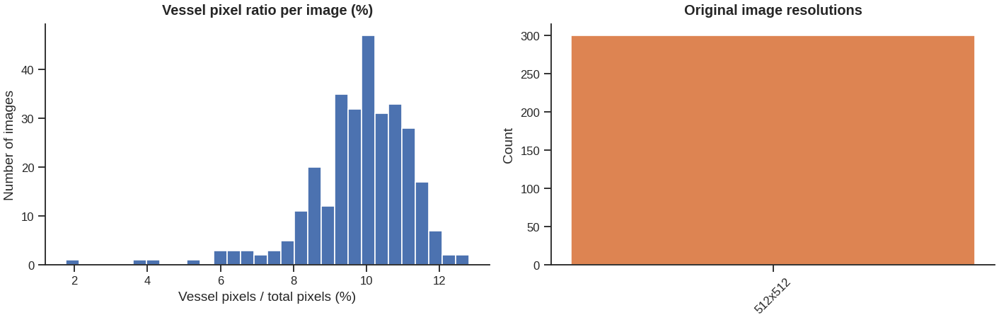

Mean vessel pixel ratio: 9.83%  (confirms strong foreground/background class imbalance -> motivates Dice+Focal loss)


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(stats_df["vessel_pixel_ratio"] * 100, bins=30, color="#4C72B0", edgecolor="white")
axes[0].set_title("Vessel pixel ratio per image (%)")
axes[0].set_xlabel("Vessel pixels / total pixels (%)")
axes[0].set_ylabel("Number of images")

wh = stats_df.groupby(["width", "height"]).size().reset_index(name="count")
axes[1].bar([f"{w}x{h}" for w, h in zip(wh.width, wh.height)], wh["count"], color="#DD8452")
axes[1].set_title("Original image resolutions")
axes[1].set_ylabel("Count")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

print(f"Mean vessel pixel ratio: {stats_df['vessel_pixel_ratio'].mean()*100:.2f}%  "
      f"(confirms strong foreground/background class imbalance -> motivates Dice+Focal loss)")


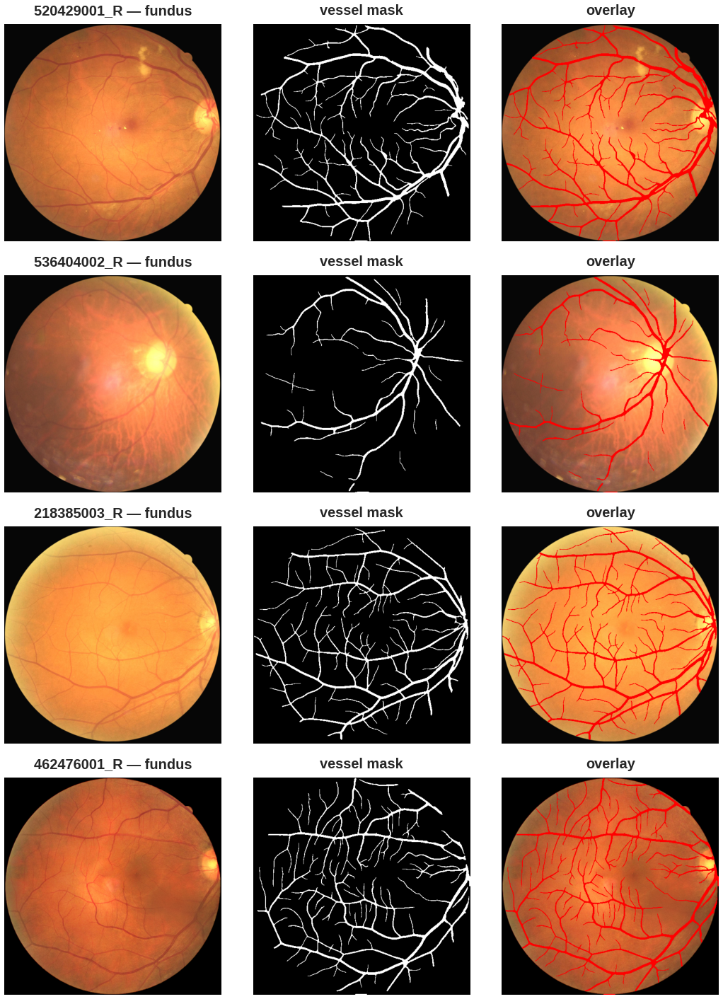

In [8]:
# --- Visualize a handful of raw image / mask / overlay triplets ---
def show_samples(file_list, images_dir, masks_dir, n=4, seed=0):
    n = min(n, len(file_list))
    rng = random.Random(seed)
    sample = rng.sample(file_list, n)
    fig, axes = plt.subplots(n, 3, figsize=(9, 3 * n))
    if n == 1:
        axes = axes[None, :]
    for i, base in enumerate(sample):
        img = Image.open(os.path.join(images_dir, base + ".png")).convert("RGB")
        mask = Image.open(os.path.join(masks_dir, base + "_mask.png")).convert("L")
        mask_np = np.array(mask)

        overlay = np.array(img.resize(mask.size)).copy()
        overlay[mask_np > 127] = [255, 0, 0]

        axes[i, 0].imshow(img); axes[i, 0].set_title(f"{base} — fundus"); axes[i, 0].axis("off")
        axes[i, 1].imshow(mask_np, cmap="gray"); axes[i, 1].set_title("vessel mask"); axes[i, 1].axis("off")
        axes[i, 2].imshow(overlay); axes[i, 2].set_title("overlay"); axes[i, 2].axis("off")
    plt.tight_layout()
    plt.show()

show_samples(file_list, CFG["images_dir"], CFG["masks_dir"], n=4)


## 4. Dataset Class & Augmentation

Random rotation (±15°), horizontal flip, and Gaussian noise are applied to the training
split only, following the paper's preprocessing protocol. We visualize the effect below.


In [9]:
class RetinalVesselDataset(Dataset):
    def __init__(self, images_dir, masks_dir, file_list, img_size=512, augment=False):
        self.images_dir = images_dir
        self.masks_dir = masks_dir
        self.file_list = file_list
        self.img_size = img_size
        self.augment = augment

    def __len__(self):
        return len(self.file_list)

    def _load_pair(self, base_name):
        img = Image.open(os.path.join(self.images_dir, base_name + ".png")).convert("RGB")
        mask = Image.open(os.path.join(self.masks_dir, base_name + "_mask.png")).convert("L")
        return img, mask

    def __getitem__(self, idx):
        base_name = self.file_list[idx]
        img, mask = self._load_pair(base_name)

        img = img.resize((self.img_size, self.img_size), Image.BILINEAR)
        mask = mask.resize((self.img_size, self.img_size), Image.NEAREST)

        if self.augment:
            if random.random() < 0.5:
                angle = random.uniform(-15, 15)
                img = img.rotate(angle, resample=Image.BILINEAR)
                mask = mask.rotate(angle, resample=Image.NEAREST)
            if random.random() < 0.5:
                img = img.transpose(Image.FLIP_LEFT_RIGHT)
                mask = mask.transpose(Image.FLIP_LEFT_RIGHT)

        img = np.array(img, dtype=np.float32) / 255.0
        mask = np.array(mask, dtype=np.float32) / 255.0
        mask = (mask > 0.5).astype(np.float32)

        if self.augment and random.random() < 0.5:
            noise = np.random.normal(0, 0.02, img.shape).astype(np.float32)
            img = np.clip(img + noise, 0.0, 1.0)

        img_t = torch.from_numpy(img).permute(2, 0, 1)
        mask_t = torch.from_numpy(mask).unsqueeze(0)
        return img_t, mask_t


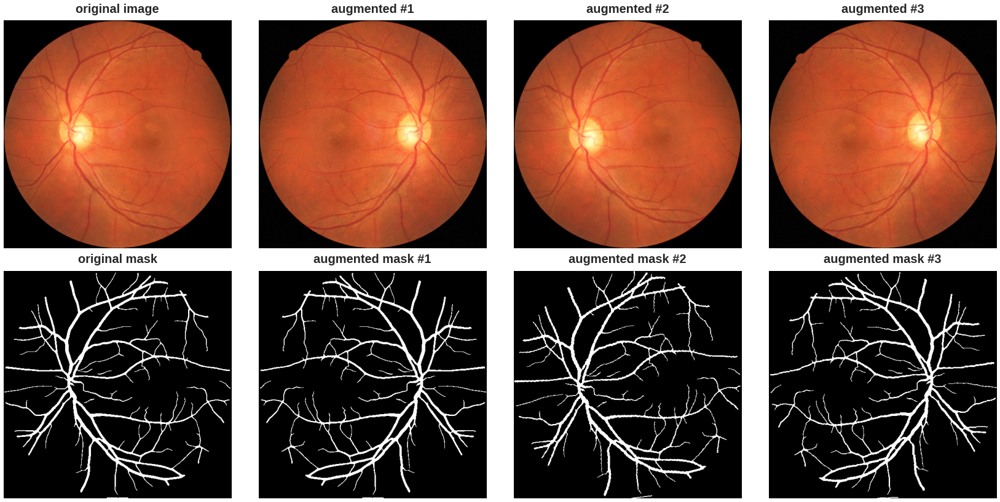

In [10]:
# --- Visual sanity check of augmentation ---
demo_ds_plain = RetinalVesselDataset(CFG["images_dir"], CFG["masks_dir"], file_list[:1],
                                      img_size=CFG["img_size"], augment=False)
demo_ds_aug = RetinalVesselDataset(CFG["images_dir"], CFG["masks_dir"], file_list[:1],
                                    img_size=CFG["img_size"], augment=True)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
img0, mask0 = demo_ds_plain[0]
axes[0, 0].imshow(img0.permute(1, 2, 0)); axes[0, 0].set_title("original image"); axes[0, 0].axis("off")
axes[1, 0].imshow(mask0[0], cmap="gray"); axes[1, 0].set_title("original mask"); axes[1, 0].axis("off")

for i in range(1, 4):
    img_a, mask_a = demo_ds_aug[0]
    axes[0, i].imshow(img_a.permute(1, 2, 0)); axes[0, i].set_title(f"augmented #{i}"); axes[0, i].axis("off")
    axes[1, i].imshow(mask_a[0], cmap="gray"); axes[1, i].set_title(f"augmented mask #{i}"); axes[1, i].axis("off")

plt.tight_layout()
plt.show()


In [11]:
def get_patient_id(base_name):
    """Strip trailing eye/side suffix so both eyes of one patient share one ID."""
    return re.sub(r'(_L|_R|_OD|_OS)$', '', base_name, flags=re.IGNORECASE)


def make_dataloaders(images_dir, masks_dir, file_list, csv_path, img_size=512, batch_size=8,
                      num_workers=2):
    """Split taken from the `group` column of data_info.csv (patient-level, no leakage):
         group 1 -> TRAIN,  group 2 -> VALIDATION,  group 3 -> TEST."""
    csv = pd.read_csv(csv_path)
    csv["base"] = csv["image_name"].map(lambda n: os.path.splitext(n)[0])
    gmap = dict(zip(csv["base"], csv["group"]))

    missing = [f for f in file_list if f not in gmap]
    if missing:
        print(f"WARNING: {len(missing)} image/mask pairs are not listed in the CSV and are skipped (e.g. {missing[:3]})")

    train_files = [f for f in file_list if gmap.get(f) == 1]
    val_files   = [f for f in file_list if gmap.get(f) == 2]
    test_files  = [f for f in file_list if gmap.get(f) == 3]

    # --- patient-level leakage check across the three splits ---
    tr_p = {get_patient_id(f) for f in train_files}
    va_p = {get_patient_id(f) for f in val_files}
    te_p = {get_patient_id(f) for f in test_files}
    assert not (tr_p & va_p) and not (tr_p & te_p) and not (va_p & te_p), "Patient leakage between CSV groups!"
    print(f"Leakage check passed: {len(tr_p)} train / {len(va_p)} val / {len(te_p)} test patients, 0 overlap")

    train_ds = RetinalVesselDataset(images_dir, masks_dir, train_files, img_size, augment=True)
    val_ds   = RetinalVesselDataset(images_dir, masks_dir, val_files,   img_size, augment=False)
    test_ds  = RetinalVesselDataset(images_dir, masks_dir, test_files,  img_size, augment=False)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                               num_workers=num_workers, pin_memory=True, drop_last=True)
    val_loader   = DataLoader(val_ds, batch_size=batch_size, shuffle=False,
                               num_workers=num_workers, pin_memory=True)
    test_loader  = DataLoader(test_ds, batch_size=batch_size, shuffle=False,
                               num_workers=num_workers, pin_memory=True)

    print(f"Total: {len(file_list)} | Train: {len(train_files)} | Val: {len(val_files)} | Test: {len(test_files)}")
    return train_loader, val_loader, test_loader, train_files, val_files, test_files

train_loader, val_loader, test_loader, train_files, val_files, test_files = make_dataloaders(
    CFG["images_dir"], CFG["masks_dir"], file_list, CFG["csv_path"],
    img_size=CFG["img_size"], batch_size=CFG["batch_size"], num_workers=CFG["num_workers"],
)


Leakage check passed: 2603 train / 200 val / 100 test patients, 0 overlap
Total: 5806 | Train: 5206 | Val: 400 | Test: 200


## 5. Model — SegFormer

Encoder (MiT-B2 by default): 4 stages of `Overlap Patch Embedding → N × [Efficient Self-Attention + Mix-FFN]`, channels 64/128/320/512
at 1/4, 1/8, 1/16, 1/32 resolution. Decoder: per-scale MLP to 256 channels → upsample to 1/4 → concat (4C) → MLP fuse →
classifier → bilinear upsample to the input size. Raw logits are returned (sigmoid is applied in the loss/metrics).
Use `variant="b0"` for a light model (≈3.7M parameters).


### 5.0 SegFormer (main model)

In [12]:
# ===================== SegFormer (Xie et al., 2021) =====================
# Hierarchical Mix Transformer (MiT) encoder: Overlap Patch Embedding -> N x [Efficient Self-Attn + Mix-FFN] per stage,
# features at 1/4, 1/8, 1/16, 1/32 (no positional encoding) -> lightweight all-MLP decoder
# (per-scale MLP -> upsample to 1/4 -> concat -> MLP fuse -> classifier) -> upsample to input size.
import math

class DropPath(nn.Module):
    def __init__(self, p=0.0):
        super().__init__(); self.p = p
    def forward(self, x):
        if self.p == 0.0 or not self.training: return x
        keep = 1 - self.p
        mask = x.new_empty((x.shape[0],) + (1,) * (x.ndim - 1)).bernoulli_(keep)
        return x * mask / keep


class OverlapPatchEmbed(nn.Module):
    """Overlapping patch embedding (conv with stride < kernel) + LayerNorm. Returns tokens (B, N, C) and (H, W)."""
    def __init__(self, in_ch, out_ch, k, s):
        super().__init__()
        self.proj = nn.Conv2d(in_ch, out_ch, k, stride=s, padding=k // 2)
        self.norm = nn.LayerNorm(out_ch)
    def forward(self, x):
        x = self.proj(x); _, _, H, W = x.shape
        return self.norm(x.flatten(2).transpose(1, 2)), H, W


class EfficientSelfAttention(nn.Module):
    """Self-attention whose keys/values are spatially reduced by sr_ratio (strided conv) -> O(N^2/R) cost."""
    def __init__(self, dim, heads, sr_ratio, attn_drop=0.0, proj_drop=0.0):
        super().__init__()
        assert dim % heads == 0
        self.h, self.dh, self.sr_ratio = heads, dim // heads, sr_ratio
        self.q = nn.Linear(dim, dim); self.kv = nn.Linear(dim, dim * 2); self.proj = nn.Linear(dim, dim)
        self.attn_drop, self.proj_drop = attn_drop, nn.Dropout(proj_drop)
        if sr_ratio > 1:
            self.sr = nn.Conv2d(dim, dim, sr_ratio, stride=sr_ratio); self.sr_norm = nn.LayerNorm(dim)
        self._nkv = 0
    def forward(self, x, H, W):
        B, N, C = x.shape
        q = self.q(x).reshape(B, N, self.h, self.dh).transpose(1, 2)
        if self.sr_ratio > 1:
            xr = self.sr(x.transpose(1, 2).reshape(B, C, H, W)).reshape(B, C, -1).transpose(1, 2)
            xr = self.sr_norm(xr)
        else:
            xr = x
        self._nkv = xr.shape[1]
        k, v = self.kv(xr).reshape(B, -1, 2, self.h, self.dh).permute(2, 0, 3, 1, 4)
        if hasattr(F, "scaled_dot_product_attention"):
            o = F.scaled_dot_product_attention(q, k, v, dropout_p=self.attn_drop if self.training else 0.0)
        else:
            a = (q @ k.transpose(-2, -1)) / math.sqrt(self.dh)
            o = F.dropout(a.softmax(-1), self.attn_drop, self.training) @ v
        return self.proj_drop(self.proj(o.transpose(1, 2).reshape(B, N, C)))


class MixFFN(nn.Module):
    """Mix-FFN: MLP -> 3x3 depth-wise conv (zero-padding leaks position info, so no positional encoding) -> GELU -> MLP."""
    def __init__(self, dim, ratio=4, drop=0.0):
        super().__init__()
        hid = dim * ratio
        self.fc1 = nn.Linear(dim, hid)
        self.dw = nn.Conv2d(hid, hid, 3, padding=1, groups=hid)
        self.act = nn.GELU(); self.fc2 = nn.Linear(hid, dim); self.drop = nn.Dropout(drop)
    def forward(self, x, H, W):
        x = self.fc1(x); B, N, C = x.shape
        x = self.dw(x.transpose(1, 2).reshape(B, C, H, W)).flatten(2).transpose(1, 2)
        return self.drop(self.fc2(self.drop(self.act(x))))


class MiTBlock(nn.Module):
    def __init__(self, dim, heads, sr_ratio, mlp_ratio, drop, drop_path):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim); self.attn = EfficientSelfAttention(dim, heads, sr_ratio, drop, drop)
        self.norm2 = nn.LayerNorm(dim); self.ffn = MixFFN(dim, mlp_ratio, drop)
        self.dp = DropPath(drop_path)
    def forward(self, x, H, W):
        x = x + self.dp(self.attn(self.norm1(x), H, W))
        return x + self.dp(self.ffn(self.norm2(x), H, W))


MIT_CFG = {   # dims, heads, depths, sr_ratios
    "b0": dict(dims=(32, 64, 160, 256),  heads=(1, 2, 5, 8), depths=(2, 2, 2, 2),  sr=(8, 4, 2, 1)),
    "b1": dict(dims=(64, 128, 320, 512), heads=(1, 2, 5, 8), depths=(2, 2, 2, 2),  sr=(8, 4, 2, 1)),
    "b2": dict(dims=(64, 128, 320, 512), heads=(1, 2, 5, 8), depths=(3, 4, 6, 3),  sr=(8, 4, 2, 1)),
}


class SegFormer(nn.Module):
    """SegFormer (MiT encoder + all-MLP decoder) for binary segmentation. Returns raw logits at input resolution.
    variant: 'b0' (3.7M, light) | 'b1' | 'b2' (25M). Trained from scratch here (no ImageNet weights).
    Input in [0,1]; ImageNet mean/std normalisation is applied inside the model."""
    def __init__(self, in_ch=3, out_ch=1, variant="b2", decoder_dim=256, mlp_ratio=4, drop=0.0, drop_path=0.1, dec_drop=0.1):
        super().__init__()
        cfg = MIT_CFG[variant]; dims = cfg["dims"]; self.dims = dims
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std",  torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
        dpr = torch.linspace(0, drop_path, sum(cfg["depths"])).tolist(); c = 0
        self.embeds, self.stages, self.norms = nn.ModuleList(), nn.ModuleList(), nn.ModuleList()
        prev = in_ch
        for i in range(4):
            k, s = (7, 4) if i == 0 else (3, 2)
            self.embeds.append(OverlapPatchEmbed(prev, dims[i], k, s))
            self.stages.append(nn.ModuleList([MiTBlock(dims[i], cfg["heads"][i], cfg["sr"][i], mlp_ratio, drop, dpr[c + j])
                                              for j in range(cfg["depths"][i])]))
            self.norms.append(nn.LayerNorm(dims[i])); c += cfg["depths"][i]; prev = dims[i]
        # all-MLP decoder: per-scale linear (1x1 conv) -> upsample -> concat -> fuse MLP -> classifier
        self.dec_mlps = nn.ModuleList([nn.Conv2d(d, decoder_dim, 1) for d in dims])
        self.fuse = nn.Sequential(nn.Conv2d(4 * decoder_dim, decoder_dim, 1, bias=False),
                                  nn.BatchNorm2d(decoder_dim), nn.ReLU(inplace=False))   # bridge / Grad-CAM target
        self.dec_drop = nn.Dropout2d(dec_drop)
        self.seg_conv = nn.Conv2d(decoder_dim, out_ch, 1)
        self.bridge_ch = decoder_dim
        self.apply(self._init)

    @staticmethod
    def _init(m):
        if isinstance(m, nn.Linear):
            nn.init.trunc_normal_(m.weight, std=0.02)
            if m.bias is not None: nn.init.zeros_(m.bias)
        elif isinstance(m, nn.LayerNorm):
            nn.init.ones_(m.weight); nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Conv2d):
            fan_out = m.kernel_size[0] * m.kernel_size[1] * m.out_channels // m.groups
            nn.init.normal_(m.weight, 0, math.sqrt(2.0 / fan_out))
            if m.bias is not None: nn.init.zeros_(m.bias)

    def _forward_features(self, x):
        size = x.shape[-2:]
        if x.shape[1] == 3: x = (x - self.mean) / self.std
        feats = []
        for emb, blocks, norm in zip(self.embeds, self.stages, self.norms):
            x, H, W = emb(x)
            for blk in blocks: x = blk(x, H, W)
            x = norm(x).transpose(1, 2).reshape(x.shape[0], -1, H, W)
            feats.append(x)
        tgt = feats[0].shape[-2:]
        ups = [F.interpolate(m(f), size=tgt, mode="bilinear", align_corners=False) if i else m(f)
               for i, (m, f) in enumerate(zip(self.dec_mlps, feats))]
        b = self.fuse(torch.cat(ups[::-1], dim=1))                                   # H/4 x W/4 x C
        seg = F.interpolate(self.seg_conv(self.dec_drop(b)), size=size, mode="bilinear", align_corners=False)
        return seg, b

    def forward(self, x):
        return self._forward_features(x)[0]


### 5.1 Legacy DCNU-Net blocks (not used by the main model — needed by the Part III `FlexUNet` ablation check)

In [13]:
class DeformableConvBlock(nn.Module):
    """Deformable convolution: offsets learned by a plain conv, applied via DeformConv2d."""
    def __init__(self, in_ch, out_ch, kernel_size=3, padding=1):
        super().__init__()
        self.offset_conv = nn.Conv2d(in_ch, 2 * kernel_size * kernel_size,
                                      kernel_size=kernel_size, padding=padding)
        nn.init.constant_(self.offset_conv.weight, 0.0)
        nn.init.constant_(self.offset_conv.bias, 0.0)
        self.deform_conv = DeformConv2d(in_ch, out_ch, kernel_size=kernel_size, padding=padding)
        self.bn = nn.BatchNorm2d(out_ch)
        self.act = nn.LeakyReLU(0.01, inplace=True)

    def forward(self, x):
        offset = self.offset_conv(x)
        x = self.deform_conv(x, offset)
        x = self.bn(x)
        return self.act(x)


class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, dropout_p=0.0):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.LeakyReLU(0.01, inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.LeakyReLU(0.01, inplace=True),
        )
        self.dropout = nn.Dropout2d(dropout_p) if dropout_p > 0 else nn.Identity()

    def forward(self, x):
        return self.dropout(self.block(x))


class EncoderStage(nn.Module):
    def __init__(self, in_ch, out_ch, dropout_p=0.0):
        super().__init__()
        self.conv = ConvBlock(in_ch, out_ch, dropout_p)
        self.deform = DeformableConvBlock(out_ch, out_ch)

    def forward(self, x):
        return self.deform(self.conv(x))


class SPPModule(nn.Module):
    """Spatial Pyramid Pooling: parallel 1x1/3x3/5x5 conv branches, replaces max-pool at bottleneck."""
    def __init__(self, in_ch, branch_ch=16):
        super().__init__()
        self.branch1 = nn.Conv2d(in_ch, branch_ch, kernel_size=1, padding=0)
        self.branch3 = nn.Conv2d(in_ch, branch_ch, kernel_size=3, padding=1)
        self.branch5 = nn.Conv2d(in_ch, branch_ch, kernel_size=5, padding=2)
        self.fuse = nn.Sequential(
            nn.Conv2d(branch_ch * 3 + in_ch, in_ch, kernel_size=1),
            nn.BatchNorm2d(in_ch), nn.LeakyReLU(0.01, inplace=True),
        )

    def forward(self, x):
        out = torch.cat([x, self.branch1(x), self.branch3(x), self.branch5(x)], dim=1)
        return self.fuse(out)


class DecoderStage(nn.Module):
    def __init__(self, in_ch, skip_ch, out_ch, dropout_p=0.0):
        super().__init__()
        self.up = nn.Upsample(scale_factor=2, mode="nearest")
        self.conv = ConvBlock(in_ch + skip_ch, out_ch, dropout_p)

    def forward(self, x, skip):
        x = self.up(x)
        if x.shape[-2:] != skip.shape[-2:]:
            x = F.interpolate(x, size=skip.shape[-2:], mode="nearest")
        return self.conv(torch.cat([x, skip], dim=1))


class DCNUNet(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, base_ch=16):
        super().__init__()
        c1, c2, c3, c4, c5 = base_ch, base_ch*2, base_ch*4, base_ch*8, base_ch*16

        self.enc1 = EncoderStage(in_ch, c1, 0.1); self.pool1 = nn.MaxPool2d(2)
        self.enc2 = EncoderStage(c1, c2, 0.1);    self.pool2 = nn.MaxPool2d(2)
        self.enc3 = EncoderStage(c2, c3, 0.2);    self.pool3 = nn.MaxPool2d(2)
        self.enc4 = EncoderStage(c3, c4, 0.2);    self.pool4 = nn.MaxPool2d(2)

        self.bottleneck_conv = ConvBlock(c4, c5, 0.3)
        self.spp = SPPModule(c5, branch_ch=16)

        self.dec4 = DecoderStage(c5, c4, c4, 0.2)
        self.dec3 = DecoderStage(c4, c3, c3, 0.2)
        self.dec2 = DecoderStage(c3, c2, c2, 0.1)
        self.dec1 = DecoderStage(c2, c1, c1, 0.1)

        self.out_conv = nn.Sequential(
            nn.Conv2d(c1, c1, kernel_size=1), nn.LeakyReLU(0.01, inplace=True),
            nn.Conv2d(c1, out_ch, kernel_size=1),
        )

    def forward(self, x):
        e1 = self.enc1(x); p1 = self.pool1(e1)
        e2 = self.enc2(p1); p2 = self.pool2(e2)
        e3 = self.enc3(p2); p3 = self.pool3(e3)
        e4 = self.enc4(p3); p4 = self.pool4(e4)

        b = self.spp(self.bottleneck_conv(p4))

        d4 = self.dec4(b, e4)
        d3 = self.dec3(d4, e3)
        d2 = self.dec2(d3, e2)
        d1 = self.dec1(d2, e1)
        return self.out_conv(d1)   # raw logits


In [14]:
model = SegFormer(in_ch=3, out_ch=1, variant="b2").to(device)
n_params = sum(p.numel() for p in model.parameters())
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters:     {n_params:,}")
print(f"Trainable parameters: {n_trainable:,}")

# quick forward-pass shape check
with torch.no_grad():
    dummy = torch.randn(1, 3, CFG["img_size"], CFG["img_size"]).to(device)
    out = model(dummy)
print("Output shape:", out.shape)


Total parameters:     24,722,369
Trainable parameters: 24,722,369
Output shape: torch.Size([1, 1, 512, 512])


## 6. Loss Function & Evaluation Metrics

Hybrid loss $L = L_{Dice} + \lambda \cdot L_{Focal}$ with $\lambda = 0.5$ (paper Eq. 6,
selected via the paper's sensitivity analysis over $\lambda \in [0.3, 0.7]$).
Metrics follow the paper's definitions (Eqs. 9–11): **ACC**, **SE** (sensitivity/recall),
**SP** (specificity), and pixel-level **AUC**.


In [15]:
class DiceLoss(nn.Module):
    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits).reshape(logits.size(0), -1)
        targets = targets.reshape(targets.size(0), -1)
        inter = (probs * targets).sum(dim=1)
        dice = (2 * inter + self.smooth) / (probs.sum(dim=1) + targets.sum(dim=1) + self.smooth)
        return 1 - dice.mean()


class FocalLoss(nn.Module):
    def __init__(self, alpha=0.8, gamma=2.0):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits).clamp(1e-6, 1 - 1e-6)
        pos = -self.alpha * (1 - probs) ** self.gamma * targets * torch.log(probs)
        neg = -(1 - self.alpha) * probs ** self.gamma * (1 - targets) * torch.log(1 - probs)
        return (pos + neg).mean()


class HybridLoss(nn.Module):
    def __init__(self, lam=0.5):
        super().__init__()
        self.dice = DiceLoss()
        self.focal = FocalLoss()
        self.lam = lam

    def forward(self, logits, targets):
        return self.dice(logits, targets) + self.lam * self.focal(logits, targets)


criterion = HybridLoss(lam=CFG["lam"])


In [16]:
@torch.no_grad()
def compute_metrics(logits, targets, threshold=0.5):
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()

    tp = (preds * targets).sum().item()
    tn = ((1 - preds) * (1 - targets)).sum().item()
    fp = (preds * (1 - targets)).sum().item()
    fn = ((1 - preds) * targets).sum().item()

    acc = (tp + tn) / (tp + tn + fp + fn + 1e-8)
    se = tp / (tp + fn + 1e-8)
    sp = tn / (tn + fp + 1e-8)
    iou = tp / (tp + fp + fn + 1e-8)
    dice = (2 * tp) / (2 * tp + fp + fn + 1e-8)

    try:
        auc_val = roc_auc_score(targets.reshape(-1).cpu().numpy(), probs.reshape(-1).cpu().numpy())
    except ValueError:
        auc_val = float("nan")

    return {"ACC": acc, "SE": se, "SP": sp, "AUC": auc_val, "IoU": iou, "Dice": dice,
            "TP": tp, "TN": tn, "FP": fp, "FN": fn}


def average_metrics(metric_dicts, keys=("ACC", "SE", "SP", "AUC", "IoU", "Dice")):
    out = {}
    for k in keys:
        vals = [m[k] for m in metric_dicts if not np.isnan(m[k])]
        out[k] = float(np.mean(vals)) if vals else float("nan")
    return out


## 7. Training Loop

Adam optimizer, `ReduceLROnPlateau` scheduler on validation loss, best model
checkpointed by validation ACC. Per-epoch loss and all four metrics are logged
and plotted below.


In [17]:
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0.0
    for imgs, masks in loader:
        imgs, masks = imgs.to(device), masks.to(device)
        optimizer.zero_grad()
        logits = model(imgs)
        loss = criterion(logits, masks)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
    return total_loss / len(loader.dataset)


@torch.no_grad()
def validate(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    metric_list = []
    for imgs, masks in loader:
        imgs, masks = imgs.to(device), masks.to(device)
        logits = model(imgs)
        loss = criterion(logits, masks)
        total_loss += loss.item() * imgs.size(0)
        metric_list.append(compute_metrics(logits, masks))
    return total_loss / len(loader.dataset), average_metrics(metric_list), metric_list


In [18]:
optimizer = torch.optim.Adam(model.parameters(), lr=CFG["lr"])
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=5)

best_acc = 0.0
history = []
best_ckpt_path = os.path.join(CFG["out_dir"], "segformer_best.pth")

for epoch in range(1, CFG["epochs"] + 1):
    t0 = time.time()
    train_loss = train_one_epoch(model, train_loader, optimizer, criterion, device)
    val_loss, val_metrics, _ = validate(model, val_loader, criterion, device)
    scheduler.step(val_loss)
    dt = time.time() - t0

    print(f"Epoch {epoch:03d}/{CFG['epochs']} ({dt:.1f}s) | "
          f"train_loss={train_loss:.4f} val_loss={val_loss:.4f} | "
          f"ACC={val_metrics['ACC']:.4f} SE={val_metrics['SE']:.4f} "
          f"SP={val_metrics['SP']:.4f} AUC={val_metrics['AUC']:.4f} "
          f"IoU={val_metrics['IoU']:.4f} Dice={val_metrics['Dice']:.4f}")

    history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss, **val_metrics})

    if val_metrics["ACC"] > best_acc:
        best_acc = val_metrics["ACC"]
        torch.save(model.state_dict(), best_ckpt_path)
        print(f"  -> new best model saved (ACC={best_acc:.4f})")

torch.save(model.state_dict(), os.path.join(CFG["out_dir"], "segformer_last.pth"))
with open(os.path.join(CFG["out_dir"], "training_history.json"), "w") as f:
    json.dump(history, f, indent=2)

hist_df = pd.DataFrame(history)
hist_df.to_csv(os.path.join(CFG["out_dir"], "training_history.csv"), index=False)
print("\nTraining complete. Best val ACC:", best_acc)


Epoch 001/20 (782.9s) | train_loss=0.4852 val_loss=0.2879 | ACC=0.9565 SE=0.7707 SP=0.9765 AUC=0.9721 IoU=0.6333 Dice=0.7754
  -> new best model saved (ACC=0.9565)
Epoch 002/20 (768.4s) | train_loss=0.2727 val_loss=0.2060 | ACC=0.9677 SE=0.8513 SP=0.9802 AUC=0.9856 IoU=0.7196 Dice=0.8369
  -> new best model saved (ACC=0.9677)
Epoch 003/20 (766.9s) | train_loss=0.2201 val_loss=0.1795 | ACC=0.9717 SE=0.8735 SP=0.9823 AUC=0.9887 IoU=0.7504 Dice=0.8574
  -> new best model saved (ACC=0.9717)
Epoch 004/20 (766.4s) | train_loss=0.2008 val_loss=0.1690 | ACC=0.9720 SE=0.9006 SP=0.9797 AUC=0.9908 IoU=0.7581 Dice=0.8624
  -> new best model saved (ACC=0.9720)
Epoch 005/20 (767.1s) | train_loss=0.1897 val_loss=0.1625 | ACC=0.9736 SE=0.9025 SP=0.9813 AUC=0.9908 IoU=0.7689 Dice=0.8693
  -> new best model saved (ACC=0.9736)
Epoch 006/20 (767.4s) | train_loss=0.1831 val_loss=0.1536 | ACC=0.9753 SE=0.9012 SP=0.9833 AUC=0.9920 IoU=0.7804 Dice=0.8766
  -> new best model saved (ACC=0.9753)
Epoch 007/20 (76

### 7.1 Training Curves

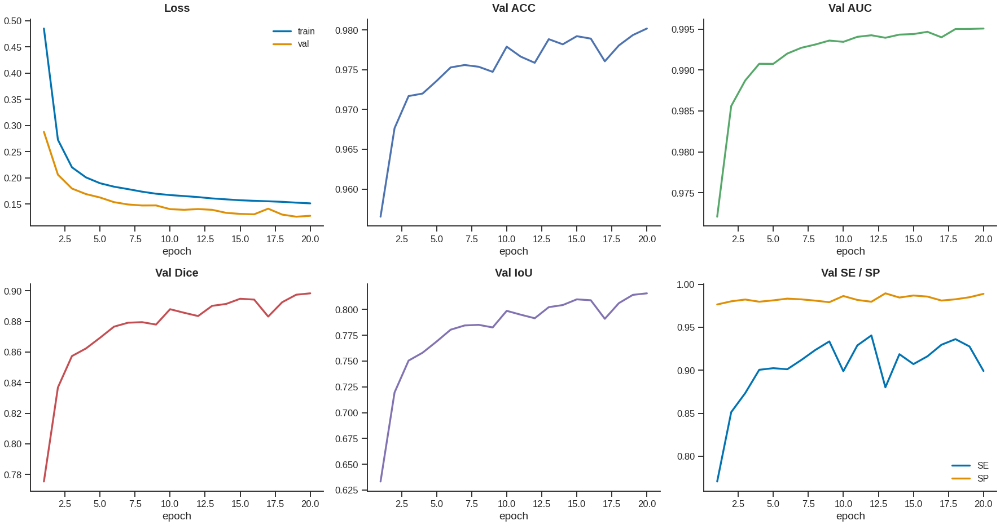

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

axes[0, 0].plot(hist_df["epoch"], hist_df["train_loss"], label="train")
axes[0, 0].plot(hist_df["epoch"], hist_df["val_loss"], label="val")
axes[0, 0].set_title("Loss"); axes[0, 0].legend()

axes[0, 1].plot(hist_df["epoch"], hist_df["ACC"], color="#4C72B0")
axes[0, 1].set_title("Val ACC")

axes[0, 2].plot(hist_df["epoch"], hist_df["AUC"], color="#55A868")
axes[0, 2].set_title("Val AUC")

axes[1, 0].plot(hist_df["epoch"], hist_df["Dice"], color="#C44E52")
axes[1, 0].set_title("Val Dice")

axes[1, 1].plot(hist_df["epoch"], hist_df["IoU"], color="#8172B2")
axes[1, 1].set_title("Val IoU")

axes[1, 2].plot(hist_df["epoch"], hist_df["SE"], label="SE")
axes[1, 2].plot(hist_df["epoch"], hist_df["SP"], label="SP")
axes[1, 2].set_title("Val SE / SP"); axes[1, 2].legend()

for ax in axes.flat:
    ax.set_xlabel("epoch")

plt.tight_layout()
plt.savefig(os.path.join(CFG["out_dir"], "training_curves.png"), dpi=300)
plt.show()


## 8. Final Evaluation on the Validation and Test Sets

Data split (from the `group` column of `data_info.csv`, patient-level): **group 1 = train, group 2 = validation, group 3 = test**.
The best checkpoint is selected on the validation set (group 2); the numbers to report in the manuscript are the held-out **test-set** (group 3) metrics.
The ROC / PR curves, confusion matrix and per-image distributions below are computed on the validation set; the test metrics follow right after.


In [20]:
model.load_state_dict(torch.load(best_ckpt_path, map_location=device))
model.eval()

final_val_loss, final_val_metrics, per_image_metrics = validate(model, val_loader, criterion, device)
print("Final validation metrics (best checkpoint):")
for k, v in final_val_metrics.items():
    print(f"  {k}: {v:.4f}")


Final validation metrics (best checkpoint):
  ACC: 0.9802
  SE: 0.8992
  SP: 0.9889
  AUC: 0.9951
  IoU: 0.8156
  Dice: 0.8984


In [21]:
# --- Held-out TEST set (CSV group 3) with the best checkpoint (selected on the validation set, group 2) ---
final_test_loss, final_test_metrics, per_image_metrics_test = validate(model, test_loader, criterion, device)
print("Final TEST metrics (best checkpoint, group 3):")
for k, v in final_test_metrics.items():
    print(f"  {k}: {v:.4f}")


Final TEST metrics (best checkpoint, group 3):
  ACC: 0.9800
  SE: 0.9001
  SP: 0.9887
  AUC: 0.9950
  IoU: 0.8153
  Dice: 0.8982


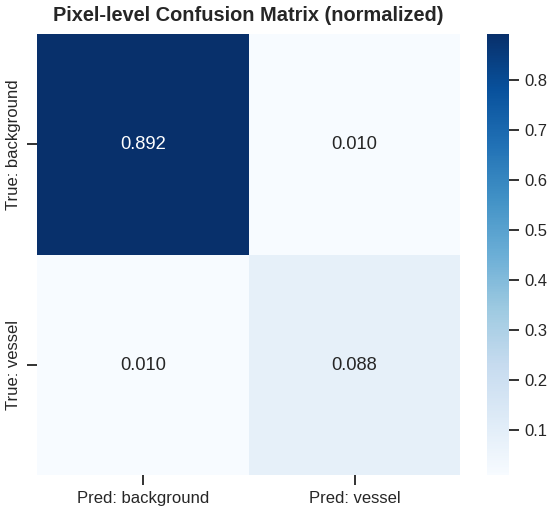

In [22]:
# --- Pixel-level confusion matrix (aggregated over validation set) ---
agg_tp = sum(m["TP"] for m in per_image_metrics)
agg_tn = sum(m["TN"] for m in per_image_metrics)
agg_fp = sum(m["FP"] for m in per_image_metrics)
agg_fn = sum(m["FN"] for m in per_image_metrics)

cm = np.array([[agg_tn, agg_fp], [agg_fn, agg_tp]])
cm_norm = cm / cm.sum()

fig, ax = plt.subplots(figsize=(5, 4.5))
sns.heatmap(cm_norm, annot=True, fmt=".3f", cmap="Blues",
            xticklabels=["Pred: background", "Pred: vessel"],
            yticklabels=["True: background", "True: vessel"], ax=ax)
ax.set_title("Pixel-level Confusion Matrix (normalized)")
plt.tight_layout()
plt.show()


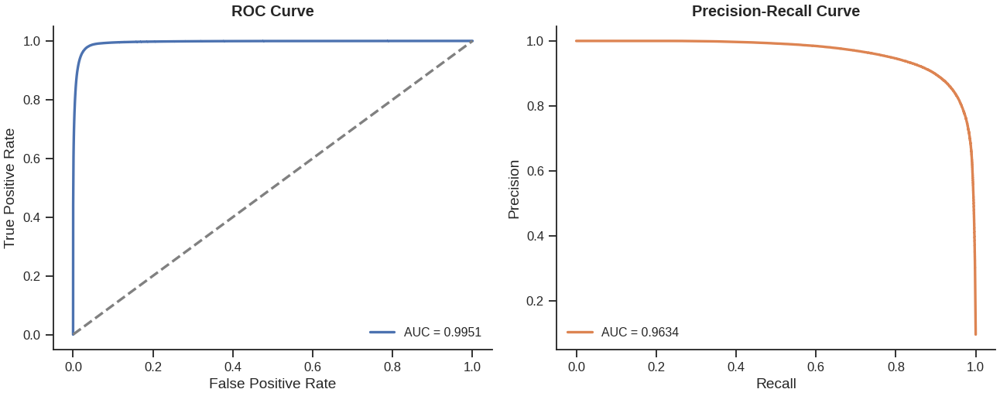

In [23]:
# --- ROC and Precision-Recall curves (pooled over a subset of validation batches) ---
@torch.no_grad()
def pool_probs_targets(model, loader, device, max_batches=None):
    all_probs, all_targets = [], []
    for i, (imgs, masks) in enumerate(loader):
        if max_batches is not None and i >= max_batches:
            break
        imgs = imgs.to(device)
        logits = model(imgs)
        probs = torch.sigmoid(logits).cpu().numpy().reshape(-1)
        all_probs.append(probs)
        all_targets.append(masks.numpy().reshape(-1))
    return np.concatenate(all_probs), np.concatenate(all_targets)

# subsample pixels for speed on large validation sets
probs_all, targets_all = pool_probs_targets(model, val_loader, device, max_batches=10)
if len(probs_all) > 2_000_000:
    idx = np.random.choice(len(probs_all), 2_000_000, replace=False)
    probs_all, targets_all = probs_all[idx], targets_all[idx]

fpr, tpr, _ = roc_curve(targets_all, probs_all)
roc_auc_val = auc(fpr, tpr)
precision, recall, _ = precision_recall_curve(targets_all, probs_all)
pr_auc_val = auc(recall, precision)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(fpr, tpr, color="#4C72B0", label=f"AUC = {roc_auc_val:.4f}")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve"); axes[0].legend()

axes[1].plot(recall, precision, color="#DD8452", label=f"AUC = {pr_auc_val:.4f}")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve"); axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(CFG["out_dir"], "roc_pr_curves.png"), dpi=300)
plt.show()


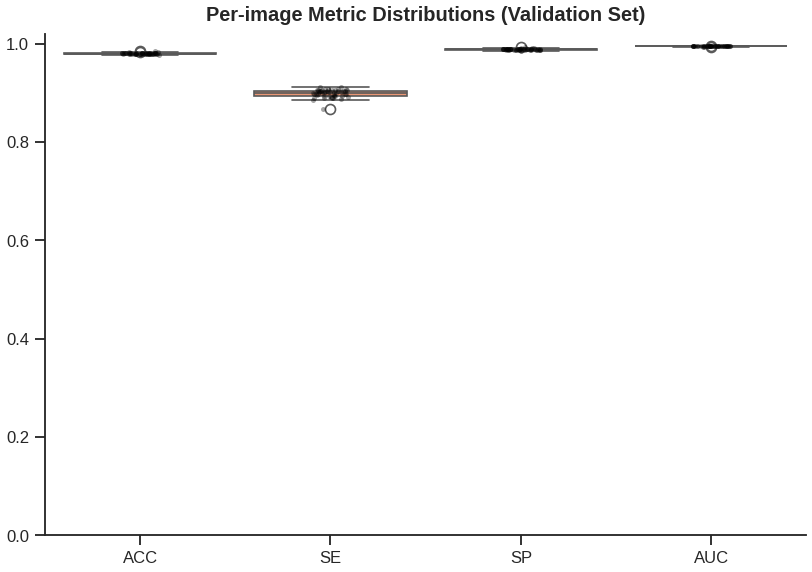

,ACC,SE,SP,AUC
count,50.000000,50.000000,50.000000,50.000000
mean,0.980184,0.899197,0.988893,0.995069
std,0.001452,0.007909,0.001264,0.000361
min,0.976933,0.868166,0.986234,0.994201
25%,0.979158,0.894501,0.988200,0.994842
50%,0.980148,0.900497,0.988639,0.995019
75%,0.980971,0.904809,0.989792,0.995262
max,0.984784,0.911984,0.992393,0.995944


In [24]:
# --- Per-image metric distributions (boxplots) ---
per_img_df = pd.DataFrame([{"ACC": m["ACC"], "SE": m["SE"], "SP": m["SP"], "AUC": m["AUC"]}
                            for m in per_image_metrics])

fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=per_img_df, palette="Set2", ax=ax)
sns.stripplot(data=per_img_df, color="black", alpha=0.35, size=3, ax=ax)
ax.set_title("Per-image Metric Distributions (Validation Set)")
ax.set_ylim(0, 1.02)
plt.tight_layout()
plt.show()

per_img_df.describe()


### 8.1 Qualitative Results: Prediction vs Ground Truth

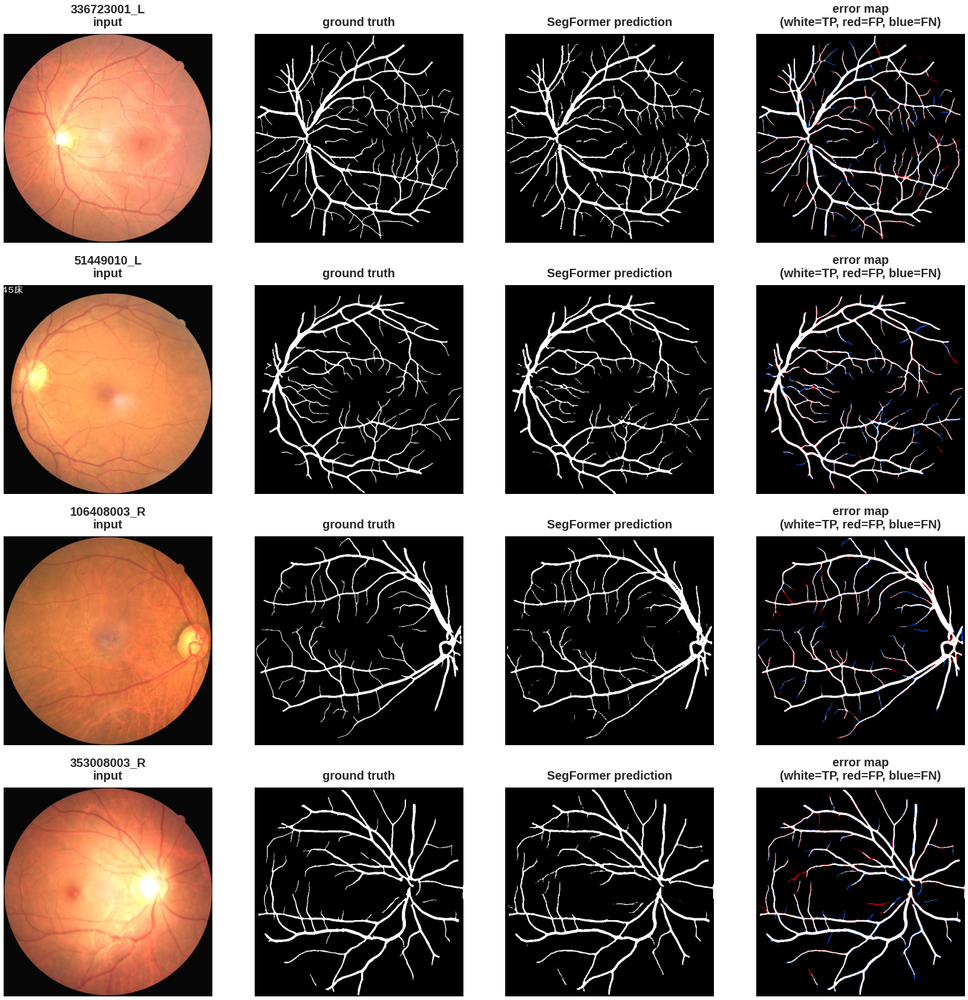

In [25]:
@torch.no_grad()
def visualize_predictions(model, images_dir, masks_dir, base_names, img_size, device, threshold=0.5):
    n = len(base_names)
    fig, axes = plt.subplots(n, 4, figsize=(14, 3.5 * n))
    if n == 1:
        axes = axes[None, :]

    for i, base in enumerate(base_names):
        img_pil = Image.open(os.path.join(images_dir, base + ".png")).convert("RGB")
        mask_pil = Image.open(os.path.join(masks_dir, base + "_mask.png")).convert("L")

        img_resized = img_pil.resize((img_size, img_size), Image.BILINEAR)
        mask_resized = mask_pil.resize((img_size, img_size), Image.NEAREST)

        arr = np.array(img_resized, dtype=np.float32) / 255.0
        tensor = torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0).to(device)
        probs = torch.sigmoid(model(tensor))[0, 0].cpu().numpy()
        pred = (probs > threshold).astype(np.uint8)

        gt = (np.array(mask_resized) > 127).astype(np.uint8)

        # error map: TP=white, FP=red, FN=blue, TN=black
        error_map = np.zeros((img_size, img_size, 3), dtype=np.uint8)
        error_map[(pred == 1) & (gt == 1)] = [255, 255, 255]   # TP
        error_map[(pred == 1) & (gt == 0)] = [255, 0, 0]        # FP
        error_map[(pred == 0) & (gt == 1)] = [0, 100, 255]      # FN

        axes[i, 0].imshow(img_resized); axes[i, 0].set_title(f"{base}\ninput"); axes[i, 0].axis("off")
        axes[i, 1].imshow(gt, cmap="gray"); axes[i, 1].set_title("ground truth"); axes[i, 1].axis("off")
        axes[i, 2].imshow(pred, cmap="gray"); axes[i, 2].set_title("SegFormer prediction"); axes[i, 2].axis("off")
        axes[i, 3].imshow(error_map); axes[i, 3].set_title("error map\n(white=TP, red=FP, blue=FN)")
        axes[i, 3].axis("off")

    plt.tight_layout()
    plt.savefig(os.path.join(CFG["out_dir"], "qualitative_predictions.png"), dpi=300)
    plt.show()

sample_val = random.sample(val_files, min(4, len(val_files)))
visualize_predictions(model, CFG["images_dir"], CFG["masks_dir"], sample_val,
                       CFG["img_size"], device)


## 9. Results Summary

Final metrics table (best checkpoint, validation set), saved alongside the paper's
reported DRIVE-dataset numbers for reference.

> **Note:** the paper rows are DRIVE-dataset numbers from the original publication; they are *not* directly comparable with results on this dataset (different data, resolution, split and annotation). Use them for context only; the like-for-like comparison is in Section 35 (Table 8).

In [26]:
paper_reference = {
    "U-Net (paper baseline)": {"ACC": 0.9448, "SE": 0.8221, "SP": 0.9779, "AUC": 0.9771},
    "DCNU-Net (paper, DRIVE)": {"ACC": 0.9682, "SE": 0.8763, "SP": 0.9816, "AUC": 0.9759},
    "SegFormer (this notebook, val)": final_val_metrics,
    "SegFormer (this notebook, test)": final_test_metrics,
}

summary_df = pd.DataFrame(paper_reference).T
summary_df.to_csv(os.path.join(CFG["out_dir"], "results_summary.csv"))
summary_df


,ACC,SE,SP,AUC,IoU,Dice
U-Net (paper baseline),0.944800,0.822100,0.977900,0.977100,NaN,NaN
"DCNU-Net (paper, DRIVE)",0.968200,0.876300,0.981600,0.975900,NaN,NaN
"SegFormer (this notebook, val)",0.980184,0.899197,0.988893,0.995069,0.815601,0.898417
"SegFormer (this notebook, test)",0.980028,0.900132,0.988687,0.995014,0.815320,0.898243


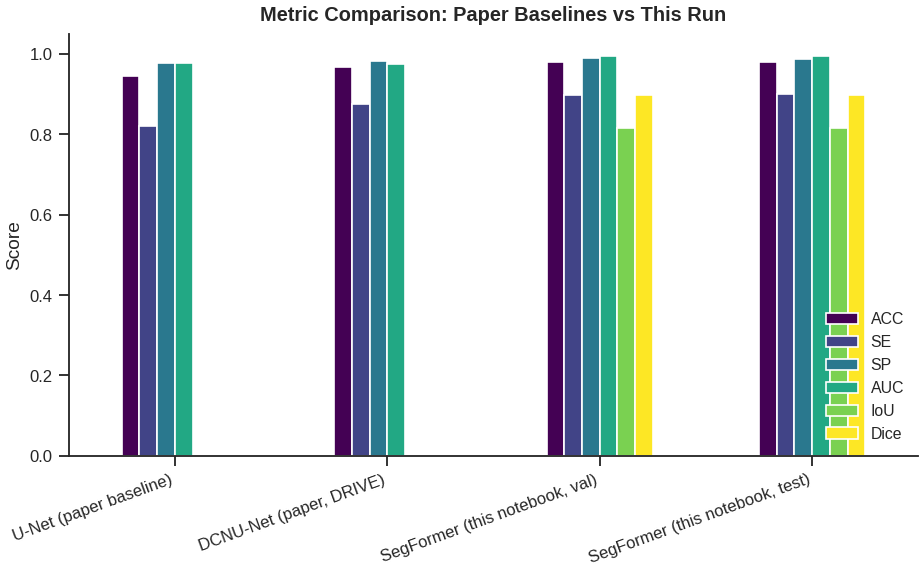

In [27]:
fig, ax = plt.subplots(figsize=(8, 5))
summary_df.plot(kind="bar", ax=ax, colormap="viridis")
ax.set_title("Metric Comparison: Paper Baselines vs This Run")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.legend(loc="lower right")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(CFG["out_dir"], "results_comparison.png"), dpi=300)
plt.show()


## 10. Conclusion

- The main network is **SegFormer** (MiT encoder with efficient self-attention and Mix-FFN, all-MLP decoder) trained with the original hybrid Dice+Focal loss.
- Red = false positives, blue = false negatives in the error maps show where thin/low-contrast vessels are still missed.
- Artifacts (`segformer_best.pth`, `training_history.csv/json`, figures) are saved to `CFG["out_dir"]`.

**Next steps:** `variant="b0"/"b1"` for speed, more `epochs` (transformers trained from scratch need longer), `lam` in `[0.3, 0.7]`, mixed precision.


## 11. Multi-Task Extension — Segmentation + Classification + Thickness Regression

Shared SegFormer encoder + MLP decoder, three heads:
1. **Segmentation** — all-MLP decoder (pixel-level vessel mask)
2. **Classification** — binary `label`, from the pooled 256-ch decoder feature + clinical MLP (age, gender)
3. **Thickness regression** — continuous `thickness` from the same fused features

Split is by the CSV `group` column (patient-level): `group==1` train, `group==2` validation, `group==3` test.


In [28]:
from sklearn.metrics import accuracy_score, mean_absolute_error, mean_squared_error, classification_report, r2_score

CFG2 = dict(
    csv_path    = CFG["csv_path"],
    images_dir  = CFG["images_dir"],   # same fundus images used for segmentation
    masks_dir   = CFG["masks_dir"],    # same vessel masks
    out_dir     = CFG["out_dir"],
    img_size    = CFG["img_size"],
    batch_size  = CFG["batch_size"],
    epochs      = 30,
    lr          = 1e-4,
    num_workers = CFG["num_workers"],
    lam         = CFG["lam"],   # Dice + lam*Focal (segmentation)
    w_seg       = 1.0,
    w_cls       = 1.0,
    w_reg       = 1.0,
    seed        = 42,
)

csv_df = pd.read_csv(CFG2["csv_path"])
print(csv_df.shape)
csv_df.head()


(5806, 7)


,image_name,thickness,label,True_age,age,gender,group
0,2491006_R.png,0.8,0,63,0.684932,0,1
1,2491006_L.png,0.8,0,63,0.684932,0,1
2,3730004_R.png,1.2,1,61,0.657534,1,1
3,3730004_L.png,1.2,1,61,0.657534,1,1
4,3730006_R.png,1.2,1,64,0.698630,1,1


In [29]:
class MultiTaskRetinalDataset(Dataset):
    """Image + mask + clinical (age, gender) + label + thickness, driven by data_info.csv rows."""
    def __init__(self, images_dir, masks_dir, df, img_size=512, augment=False):
        self.images_dir = images_dir
        self.masks_dir = masks_dir
        self.df = df.reset_index(drop=True)
        self.img_size = img_size
        self.augment = augment

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        base = os.path.splitext(row["image_name"])[0]

        img = Image.open(os.path.join(self.images_dir, base + ".png")).convert("RGB")
        mask = Image.open(os.path.join(self.masks_dir, base + "_mask.png")).convert("L")

        img = img.resize((self.img_size, self.img_size), Image.BILINEAR)
        mask = mask.resize((self.img_size, self.img_size), Image.NEAREST)

        img_np = np.array(img).astype(np.float32) / 255.0
        mask_np = (np.array(mask).astype(np.float32) / 255.0 > 0.5).astype(np.float32)

        if self.augment:
            if random.random() < 0.5:
                img_np = np.fliplr(img_np).copy()
                mask_np = np.fliplr(mask_np).copy()
            angle = random.uniform(-15, 15)
            img_pil = Image.fromarray((img_np * 255).astype(np.uint8)).rotate(angle, resample=Image.BILINEAR)
            mask_pil = Image.fromarray((mask_np * 255).astype(np.uint8)).rotate(angle, resample=Image.NEAREST)
            img_np = np.array(img_pil).astype(np.float32) / 255.0
            mask_np = (np.array(mask_pil).astype(np.float32) / 255.0 > 0.5).astype(np.float32)
            if random.random() < 0.3:
                img_np = np.clip(img_np + np.random.normal(0, 0.02, img_np.shape), 0, 1).astype(np.float32)

        img_t = torch.from_numpy(img_np.copy()).permute(2, 0, 1).float()
        mask_t = torch.from_numpy(mask_np.copy()).unsqueeze(0).float()
        clinical_t = torch.tensor([row["age"], row["gender"]], dtype=torch.float32)
        label_t = torch.tensor(row["label"], dtype=torch.float32)
        thickness_t = torch.tensor(row["thickness"], dtype=torch.float32)
        return img_t, mask_t, clinical_t, label_t, thickness_t


def make_mt_dataloaders(images_dir, masks_dir, csv_df, img_size=512, batch_size=8, num_workers=2):
    # CSV `group` column:  1 = train,  2 = validation,  3 = test
    train_df = csv_df[csv_df["group"] == 1].copy()
    val_df   = csv_df[csv_df["group"] == 2].copy()
    test_df  = csv_df[csv_df["group"] == 3].copy()

    # --- Patient-level leakage check across train/val/test (CSV "group" split) ---
    pid = lambda name: get_patient_id(os.path.splitext(name)[0])
    train_p = set(train_df["image_name"].map(pid))
    val_p   = set(val_df["image_name"].map(pid))
    test_p  = set(test_df["image_name"].map(pid))
    leak_tv, leak_tt, leak_vt = train_p & val_p, train_p & test_p, val_p & test_p
    if leak_tv or leak_tt or leak_vt:
        print(f"WARNING - patient leakage found: train/val={len(leak_tv)} "
              f"train/test={len(leak_tt)} val/test={len(leak_vt)}")
    else:
        print(f"Leakage check passed: train={len(train_p)}, val={len(val_p)}, "
              f"test={len(test_p)} patients, 0 overlap")

    train_ds = MultiTaskRetinalDataset(images_dir, masks_dir, train_df, img_size, augment=True)
    val_ds   = MultiTaskRetinalDataset(images_dir, masks_dir, val_df,   img_size, augment=False)
    test_ds  = MultiTaskRetinalDataset(images_dir, masks_dir, test_df,  img_size, augment=False)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,  num_workers=num_workers, drop_last=True)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False, num_workers=num_workers)
    test_loader  = DataLoader(test_ds,  batch_size=batch_size, shuffle=False, num_workers=num_workers)

    print(f"train={len(train_ds)}  val={len(val_ds)}  test={len(test_ds)}")
    return train_loader, val_loader, test_loader, train_df, val_df, test_df

mt_train_loader, mt_val_loader, mt_test_loader, mt_train_df, mt_val_df, mt_test_df = make_mt_dataloaders(
    CFG2["images_dir"], CFG2["masks_dir"], csv_df,
    img_size=CFG2["img_size"], batch_size=CFG2["batch_size"], num_workers=CFG2["num_workers"],
)


Leakage check passed: train=2603, val=200, test=100 patients, 0 overlap
train=5206  val=400  test=200


### 11.1 Model — SegFormer Multi-Task (uses `SegFormer` from Section 5 + `ClinicalMLP`)


In [30]:
class ClinicalMLP(nn.Module):
    def __init__(self, in_dim=2, hidden=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.LeakyReLU(0.01, inplace=True),
            nn.Linear(hidden, hidden), nn.LeakyReLU(0.01, inplace=True),
        )

    def forward(self, x):
        return self.net(x)


class DCNUNetMultiTask(nn.Module):
    """Shared DCNU-Net encoder/bottleneck -> (1) segmentation decoder, (2) classification head,
    (3) thickness regression head. Classification/regression heads consume the global-pooled
    bottleneck feature fused with a small clinical (age, gender) MLP."""
    def __init__(self, in_ch=3, seg_out_ch=1, base_ch=16, clinical_dim=2, clinical_hidden=32, fc_dim=128):
        super().__init__()
        c1, c2, c3, c4, c5 = base_ch, base_ch*2, base_ch*4, base_ch*8, base_ch*16

        self.enc1 = EncoderStage(in_ch, c1, 0.1); self.pool1 = nn.MaxPool2d(2)
        self.enc2 = EncoderStage(c1, c2, 0.1);    self.pool2 = nn.MaxPool2d(2)
        self.enc3 = EncoderStage(c2, c3, 0.2);    self.pool3 = nn.MaxPool2d(2)
        self.enc4 = EncoderStage(c3, c4, 0.2);    self.pool4 = nn.MaxPool2d(2)

        self.bottleneck_conv = ConvBlock(c4, c5, 0.3)
        self.spp = SPPModule(c5, branch_ch=16)

        self.dec4 = DecoderStage(c5, c4, c4, 0.2)
        self.dec3 = DecoderStage(c4, c3, c3, 0.2)
        self.dec2 = DecoderStage(c3, c2, c2, 0.1)
        self.dec1 = DecoderStage(c2, c1, c1, 0.1)
        self.seg_out = nn.Sequential(
            nn.Conv2d(c1, c1, kernel_size=1), nn.LeakyReLU(0.01, inplace=True),
            nn.Conv2d(c1, seg_out_ch, kernel_size=1),
        )

        self.gap = nn.AdaptiveAvgPool2d(1)
        self.clinical_mlp = ClinicalMLP(clinical_dim, clinical_hidden)
        self.shared_fc = nn.Sequential(
            nn.Linear(c5 + clinical_hidden, fc_dim), nn.LeakyReLU(0.01, inplace=True), nn.Dropout(0.3),
        )
        self.cls_head = nn.Linear(fc_dim, 1)
        self.reg_head = nn.Linear(fc_dim, 1)

    def forward(self, x, clinical):
        e1 = self.enc1(x); p1 = self.pool1(e1)
        e2 = self.enc2(p1); p2 = self.pool2(e2)
        e3 = self.enc3(p2); p3 = self.pool3(e3)
        e4 = self.enc4(p3); p4 = self.pool4(e4)

        b = self.spp(self.bottleneck_conv(p4))

        d4 = self.dec4(b, e4)
        d3 = self.dec3(d4, e3)
        d2 = self.dec2(d3, e2)
        d1 = self.dec1(d2, e1)
        seg_logits = self.seg_out(d1)

        pooled = self.gap(b).flatten(1)
        clin = self.clinical_mlp(clinical)
        fused = torch.cat([pooled, clin], dim=1)
        shared = self.shared_fc(fused)
        cls_logit = self.cls_head(shared).squeeze(1)
        reg_pred = self.reg_head(shared).squeeze(1)
        return seg_logits, cls_logit, reg_pred


class SegFormerMultiTask(SegFormer):
    """Shared SegFormer encoder + MLP decoder -> (1) segmentation, (2) classification head, (3) thickness regression head.
    Heads use the global-pooled decoder feature (256-ch) fused with a clinical (age, gender) MLP.
    forward(img, clinical) -> (seg_logits, cls_logit, reg_pred); exposes `.gap` and `.fuse`."""
    def __init__(self, in_ch=3, seg_out_ch=1, variant="b2", clinical_dim=2, clinical_hidden=32, fc_dim=128):
        super().__init__(in_ch, seg_out_ch, variant)
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.clinical_mlp = ClinicalMLP(clinical_dim, clinical_hidden)
        self.shared_fc = nn.Sequential(nn.Linear(self.bridge_ch + clinical_hidden, fc_dim),
                                       nn.LeakyReLU(0.01, inplace=True), nn.Dropout(0.3))
        self.cls_head = nn.Linear(fc_dim, 1)
        self.reg_head = nn.Linear(fc_dim, 1)

    def forward(self, x, clinical):
        seg_logits, b = self._forward_features(x)
        fused = torch.cat([self.gap(b).flatten(1), self.clinical_mlp(clinical)], dim=1)
        shared = self.shared_fc(fused)
        return seg_logits, self.cls_head(shared).squeeze(1), self.reg_head(shared).squeeze(1)


mt_model = SegFormerMultiTask(in_ch=3, seg_out_ch=1, variant="b2").to(device)
n_params = sum(p.numel() for p in mt_model.parameters())
print(f"Total parameters: {n_params:,}")

with torch.no_grad():
    dummy_img = torch.randn(2, 3, CFG2["img_size"], CFG2["img_size"]).to(device)
    dummy_clin = torch.randn(2, 2).to(device)
    seg_o, cls_o, reg_o = mt_model(dummy_img, dummy_clin)
print("seg:", seg_o.shape, "cls:", cls_o.shape, "reg:", reg_o.shape)


Total parameters: 24,760,771
seg: torch.Size([2, 1, 512, 512]) cls: torch.Size([2]) reg: torch.Size([2])


### 11.2 Multi-Task Loss & Metrics

In [31]:
n_pos = (mt_train_df["label"] == 1).sum()
n_neg = (mt_train_df["label"] == 0).sum()
pos_weight = torch.tensor(n_neg / max(n_pos, 1), dtype=torch.float32).to(device)
print(f"train label counts -> pos(1)={n_pos} neg(0)={n_neg}  pos_weight={pos_weight.item():.3f}")


class MultiTaskLoss(nn.Module):
    def __init__(self, lam=0.5, w_seg=1.0, w_cls=1.0, w_reg=1.0, pos_weight=None):
        super().__init__()
        self.dice = DiceLoss()
        self.focal = FocalLoss()
        self.lam = lam
        self.bce = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
        self.reg = nn.SmoothL1Loss()
        self.w_seg, self.w_cls, self.w_reg = w_seg, w_cls, w_reg

    def forward(self, seg_logits, masks, cls_logit, labels, reg_pred, thickness):
        seg_loss = self.dice(seg_logits, masks) + self.lam * self.focal(seg_logits, masks)
        cls_loss = self.bce(cls_logit, labels)
        reg_loss = self.reg(reg_pred, thickness)
        total = self.w_seg * seg_loss + self.w_cls * cls_loss + self.w_reg * reg_loss
        return total, seg_loss.item(), cls_loss.item(), reg_loss.item()


mt_criterion = MultiTaskLoss(lam=CFG2["lam"], w_seg=CFG2["w_seg"], w_cls=CFG2["w_cls"],
                              w_reg=CFG2["w_reg"], pos_weight=pos_weight)


def train_one_epoch_mt(model, loader, optimizer, criterion, device):
    model.train()
    tot, tot_seg, tot_cls, tot_reg = 0.0, 0.0, 0.0, 0.0
    for imgs, masks, clin, labels, thick in loader:
        imgs, masks, clin = imgs.to(device), masks.to(device), clin.to(device)
        labels, thick = labels.to(device), thick.to(device)
        optimizer.zero_grad()
        seg_logits, cls_logit, reg_pred = model(imgs, clin)
        loss, sl, cl, rl = criterion(seg_logits, masks, cls_logit, labels, reg_pred, thick)
        loss.backward()
        optimizer.step()
        bs = imgs.size(0)
        tot += loss.item() * bs; tot_seg += sl * bs; tot_cls += cl * bs; tot_reg += rl * bs
    n = len(loader.dataset)
    return tot / n, tot_seg / n, tot_cls / n, tot_reg / n


@torch.no_grad()
def validate_mt(model, loader, criterion, device, threshold=0.5):
    model.eval()
    tot, tot_seg, tot_cls, tot_reg = 0.0, 0.0, 0.0, 0.0
    seg_metric_list = []
    cls_probs, cls_true, reg_pred_all, reg_true_all = [], [], [], []

    for imgs, masks, clin, labels, thick in loader:
        imgs, masks, clin = imgs.to(device), masks.to(device), clin.to(device)
        labels, thick = labels.to(device), thick.to(device)
        seg_logits, cls_logit, reg_pred = model(imgs, clin)
        loss, sl, cl, rl = criterion(seg_logits, masks, cls_logit, labels, reg_pred, thick)
        bs = imgs.size(0)
        tot += loss.item() * bs; tot_seg += sl * bs; tot_cls += cl * bs; tot_reg += rl * bs

        seg_metric_list.append(compute_metrics(seg_logits, masks, threshold))
        cls_probs.append(torch.sigmoid(cls_logit).cpu().numpy())
        cls_true.append(labels.cpu().numpy())
        reg_pred_all.append(reg_pred.cpu().numpy())
        reg_true_all.append(thick.cpu().numpy())

    n = len(loader.dataset)
    cls_probs = np.concatenate(cls_probs); cls_true = np.concatenate(cls_true)
    reg_pred_all = np.concatenate(reg_pred_all); reg_true_all = np.concatenate(reg_true_all)
    cls_pred = (cls_probs > 0.5).astype(int)

    metrics = {
        "seg_ACC": np.mean([m["ACC"] for m in seg_metric_list]),
        "seg_SE": np.mean([m["SE"] for m in seg_metric_list]),
        "seg_SP": np.mean([m["SP"] for m in seg_metric_list]),
        "seg_AUC": np.nanmean([m["AUC"] for m in seg_metric_list]),
        "seg_IoU": np.mean([m["IoU"] for m in seg_metric_list]),
        "seg_Dice": np.mean([m["Dice"] for m in seg_metric_list]),
        "cls_ACC": accuracy_score(cls_true, cls_pred),
        "cls_AUC": roc_auc_score(cls_true, cls_probs) if len(np.unique(cls_true)) > 1 else float("nan"),
        "reg_MAE": mean_absolute_error(reg_true_all, reg_pred_all),
        "reg_RMSE": mean_squared_error(reg_true_all, reg_pred_all) ** 0.5,
        "reg_R2": r2_score(reg_true_all, reg_pred_all) if len(np.unique(reg_true_all)) > 1 else float("nan"),
    }
    return tot / n, tot_seg / n, tot_cls / n, tot_reg / n, metrics, (cls_true, cls_probs, cls_pred, reg_true_all, reg_pred_all)


train label counts -> pos(1)=3808 neg(0)=1398  pos_weight=0.367


### 11.3 Training Loop

In [32]:
mt_optimizer = torch.optim.Adam(mt_model.parameters(), lr=CFG2["lr"])
mt_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(mt_optimizer, mode="min", factor=0.5, patience=5)

mt_best_score = -1.0
mt_history = []
mt_best_ckpt_path = os.path.join(CFG2["out_dir"], "segformer_multitask_best.pth")

for epoch in range(1, CFG2["epochs"] + 1):
    t0 = time.time()
    tr_loss, tr_seg, tr_cls, tr_reg = train_one_epoch_mt(mt_model, mt_train_loader, mt_optimizer, mt_criterion, device)
    val_loss, val_seg, val_cls, val_reg, val_metrics, _ = validate_mt(mt_model, mt_val_loader, mt_criterion, device)
    mt_scheduler.step(val_loss)
    dt = time.time() - t0

    combined_score = val_metrics["seg_ACC"] + val_metrics["cls_ACC"] - val_metrics["reg_MAE"]
    row = dict(epoch=epoch, train_loss=tr_loss, val_loss=val_loss,
               train_seg=tr_seg, train_cls=tr_cls, train_reg=tr_reg, **val_metrics)
    mt_history.append(row)

    print(f"Epoch {epoch:03d}/{CFG2['epochs']} ({dt:.1f}s) "
          f"train_loss={tr_loss:.4f} val_loss={val_loss:.4f} | "
          f"seg_ACC={val_metrics['seg_ACC']:.4f} seg_IoU={val_metrics['seg_IoU']:.4f} "
          f"seg_Dice={val_metrics['seg_Dice']:.4f} | "
          f"cls_ACC={val_metrics['cls_ACC']:.4f} cls_AUC={val_metrics['cls_AUC']:.4f} | "
          f"reg_MAE={val_metrics['reg_MAE']:.4f} reg_R2={val_metrics['reg_R2']:.4f}")

    if combined_score > mt_best_score:
        mt_best_score = combined_score
        torch.save(mt_model.state_dict(), mt_best_ckpt_path)

mt_hist_df = pd.DataFrame(mt_history)
mt_hist_df.to_csv(os.path.join(CFG2["out_dir"], "multitask_training_history.csv"), index=False)
mt_hist_df.tail()


Epoch 001/30 (782.9s) train_loss=0.8622 val_loss=0.7376 | seg_ACC=0.9557 seg_IoU=0.6191 seg_Dice=0.7646 | cls_ACC=0.6200 cls_AUC=0.6921 | reg_MAE=0.1587 reg_R2=0.1764
Epoch 002/30 (781.5s) train_loss=0.6374 val_loss=0.6451 | seg_ACC=0.9617 seg_IoU=0.6826 seg_Dice=0.8113 | cls_ACC=0.7600 cls_AUC=0.8192 | reg_MAE=0.1441 reg_R2=0.3446
Epoch 003/30 (783.3s) train_loss=0.5604 val_loss=0.5942 | seg_ACC=0.9677 seg_IoU=0.7209 seg_Dice=0.8378 | cls_ACC=0.7625 cls_AUC=0.8474 | reg_MAE=0.1521 reg_R2=0.2401
Epoch 004/30 (784.6s) train_loss=0.5193 val_loss=0.5513 | seg_ACC=0.9687 seg_IoU=0.7333 seg_Dice=0.8461 | cls_ACC=0.7800 cls_AUC=0.8636 | reg_MAE=0.1317 reg_R2=0.4060
Epoch 005/30 (785.0s) train_loss=0.4944 val_loss=0.5468 | seg_ACC=0.9709 seg_IoU=0.7486 seg_Dice=0.8562 | cls_ACC=0.7800 cls_AUC=0.8693 | reg_MAE=0.1478 reg_R2=0.2868
Epoch 006/30 (783.4s) train_loss=0.4841 val_loss=0.5260 | seg_ACC=0.9735 seg_IoU=0.7636 seg_Dice=0.8659 | cls_ACC=0.7875 cls_AUC=0.8704 | reg_MAE=0.1377 reg_R2=0.381

,epoch,train_loss,val_loss,train_seg,train_cls,train_reg,seg_ACC,seg_SE,seg_SP,seg_AUC,seg_IoU,seg_Dice,cls_ACC,cls_AUC,reg_MAE,reg_RMSE,reg_R2
25,26,0.438803,0.481704,0.169134,0.257117,0.012552,0.977399,0.928785,0.982634,0.994392,0.800133,0.888943,0.7950,0.872000,0.139790,0.171148,0.356568
26,27,0.436516,0.488559,0.167023,0.256965,0.012528,0.976741,0.935137,0.981213,0.994426,0.796624,0.886772,0.7900,0.871400,0.134765,0.166631,0.390082
27,28,0.435531,0.506143,0.166593,0.256753,0.012185,0.976780,0.936182,0.981153,0.994596,0.797011,0.887008,0.7950,0.874900,0.148116,0.179823,0.289689
28,29,0.435228,0.500931,0.167351,0.255567,0.012310,0.977916,0.924208,0.983708,0.994587,0.803026,0.890727,0.7825,0.872725,0.148311,0.180934,0.280883
29,30,0.437331,0.490276,0.167200,0.257627,0.012504,0.976398,0.938837,0.980422,0.994578,0.794944,0.885731,0.7975,0.872450,0.141612,0.171120,0.356774


### 11.4 Training Curves

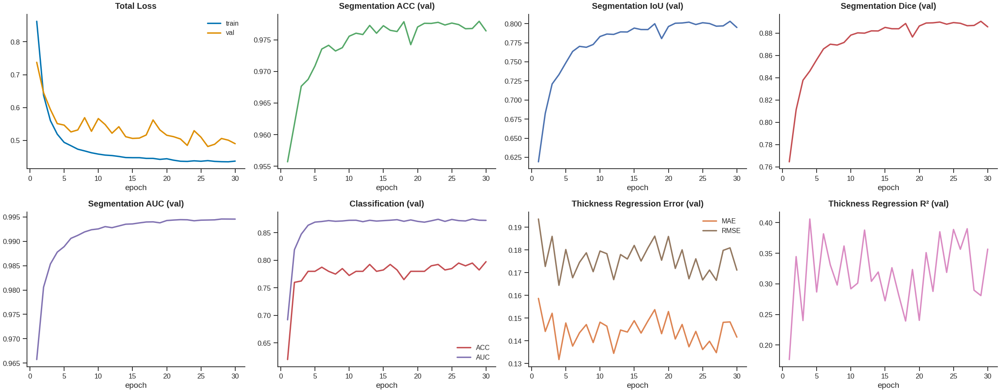

In [33]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))

axes[0, 0].plot(mt_hist_df["epoch"], mt_hist_df["train_loss"], label="train")
axes[0, 0].plot(mt_hist_df["epoch"], mt_hist_df["val_loss"], label="val")
axes[0, 0].set_title("Total Loss"); axes[0, 0].legend()

axes[0, 1].plot(mt_hist_df["epoch"], mt_hist_df["seg_ACC"], color="#55A868")
axes[0, 1].set_title("Segmentation ACC (val)")

axes[0, 2].plot(mt_hist_df["epoch"], mt_hist_df["seg_IoU"], color="#4C72B0")
axes[0, 2].set_title("Segmentation IoU (val)")

axes[0, 3].plot(mt_hist_df["epoch"], mt_hist_df["seg_Dice"], color="#C44E52")
axes[0, 3].set_title("Segmentation Dice (val)")

axes[1, 0].plot(mt_hist_df["epoch"], mt_hist_df["seg_AUC"], color="#8172B2")
axes[1, 0].set_title("Segmentation AUC (val)")

axes[1, 1].plot(mt_hist_df["epoch"], mt_hist_df["cls_ACC"], label="ACC", color="#C44E52")
axes[1, 1].plot(mt_hist_df["epoch"], mt_hist_df["cls_AUC"], label="AUC", color="#8172B2")
axes[1, 1].set_title("Classification (val)"); axes[1, 1].legend()

axes[1, 2].plot(mt_hist_df["epoch"], mt_hist_df["reg_MAE"], label="MAE", color="#DD8452")
axes[1, 2].plot(mt_hist_df["epoch"], mt_hist_df["reg_RMSE"], label="RMSE", color="#937860")
axes[1, 2].set_title("Thickness Regression Error (val)"); axes[1, 2].legend()

axes[1, 3].plot(mt_hist_df["epoch"], mt_hist_df["reg_R2"], color="#DA8BC3")
axes[1, 3].set_title("Thickness Regression R\u00b2 (val)")

for ax in axes.flat:
    ax.set_xlabel("epoch")

plt.tight_layout()
plt.savefig(os.path.join(CFG2["out_dir"], "multitask_training_curves.png"), dpi=300)
plt.show()


## 12. Final Multi-Task Evaluation (Test Set)

In [34]:
mt_model.load_state_dict(torch.load(mt_best_ckpt_path, map_location=device))
mt_model.eval()

test_loss, test_seg, test_cls, test_reg, test_metrics, raw = validate_mt(mt_model, mt_test_loader, mt_criterion, device)
cls_true, cls_probs, cls_pred, reg_true, reg_pred = raw

print("Final test metrics (best checkpoint):")
for k, v in test_metrics.items():
    print(f"  {k}: {v:.4f}")

print()
print(classification_report(cls_true, cls_pred, target_names=["class 0", "class 1"]))


Final test metrics (best checkpoint):
  seg_ACC: 0.9775
  seg_SE: 0.9251
  seg_SP: 0.9832
  seg_AUC: 0.9945
  seg_IoU: 0.8013
  seg_Dice: 0.8897
  cls_ACC: 0.8650
  cls_AUC: 0.9467
  reg_MAE: 0.1094
  reg_RMSE: 0.1375
  reg_R2: 0.4864

              precision    recall  f1-score   support

     class 0       0.91      0.81      0.86       100
     class 1       0.83      0.92      0.87       100

    accuracy                           0.86       200
   macro avg       0.87      0.86      0.86       200
weighted avg       0.87      0.86      0.86       200



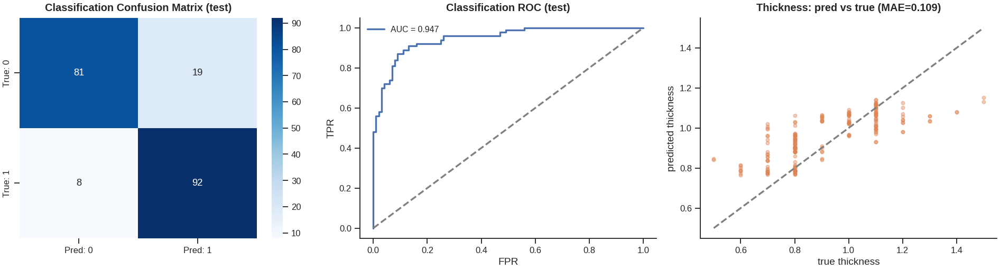

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

cm = confusion_matrix(cls_true, cls_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["Pred: 0", "Pred: 1"], yticklabels=["True: 0", "True: 1"])
axes[0].set_title("Classification Confusion Matrix (test)")

fpr, tpr, _ = roc_curve(cls_true, cls_probs)
axes[1].plot(fpr, tpr, label=f"AUC = {test_metrics['cls_AUC']:.3f}", color="#4C72B0")
axes[1].plot([0, 1], [0, 1], "--", color="gray")
axes[1].set_title("Classification ROC (test)"); axes[1].set_xlabel("FPR"); axes[1].set_ylabel("TPR"); axes[1].legend()

axes[2].scatter(reg_true, reg_pred, alpha=0.4, s=15, color="#DD8452")
lims = [min(reg_true.min(), reg_pred.min()), max(reg_true.max(), reg_pred.max())]
axes[2].plot(lims, lims, "--", color="gray")
axes[2].set_title(f"Thickness: pred vs true (MAE={test_metrics['reg_MAE']:.3f})")
axes[2].set_xlabel("true thickness"); axes[2].set_ylabel("predicted thickness")

plt.tight_layout()
plt.savefig(os.path.join(CFG2["out_dir"], "multitask_test_results.png"), dpi=300)
plt.show()


In [36]:
mt_summary = pd.DataFrame([test_metrics], index=["SegFormer Multi-Task (test)"])
mt_summary.to_csv(os.path.join(CFG2["out_dir"], "multitask_results_summary.csv"))
mt_summary


,seg_ACC,seg_SE,seg_SP,seg_AUC,seg_IoU,seg_Dice,cls_ACC,cls_AUC,reg_MAE,reg_RMSE,reg_R2
SegFormer Multi-Task (test),0.977536,0.925141,0.983214,0.994456,0.801348,0.889695,0.865,0.9467,0.10936,0.137485,0.486412


## 13. Per-Image Test Metrics (Original vs Test-Time Augmentation)

Computes per-image Dice/IoU on the test set, plus a horizontal-flip TTA pass (needed for Statistical Test 1 and for bootstrap CIs below).

In [37]:
@torch.no_grad()
def per_image_seg_metrics_with_tta(model, df, images_dir, masks_dir, img_size,
                                    clinical_cols, device, threshold=0.5):
    model.eval()
    dice_orig, iou_orig, dice_tta, iou_tta = [], [], [], []
    for idx in range(len(df)):
        row = df.iloc[idx]
        base = os.path.splitext(row["image_name"])[0]
        img = Image.open(os.path.join(images_dir, base + ".png")).convert("RGB").resize(
            (img_size, img_size), Image.BILINEAR)
        mask = Image.open(os.path.join(masks_dir, base + "_mask.png")).convert("L").resize(
            (img_size, img_size), Image.NEAREST)
        img_np = np.array(img).astype(np.float32) / 255.0
        mask_np = (np.array(mask).astype(np.float32) / 255.0 > 0.5).astype(np.float32)

        img_t = torch.from_numpy(img_np).permute(2, 0, 1).unsqueeze(0).float().to(device)
        mask_t = torch.from_numpy(mask_np).unsqueeze(0).unsqueeze(0).float().to(device)
        clin_t = torch.tensor([[row[c] for c in clinical_cols]], dtype=torch.float32).to(device)

        seg_logits, _, _ = model(img_t, clin_t)
        m = compute_metrics(seg_logits, mask_t, threshold)
        dice_orig.append(m["Dice"]); iou_orig.append(m["IoU"])

        img_flip = torch.flip(img_t, dims=[3])
        seg_logits_f, _, _ = model(img_flip, clin_t)
        seg_logits_f = torch.flip(seg_logits_f, dims=[3])
        m_f = compute_metrics(seg_logits_f, mask_t, threshold)
        dice_tta.append(m_f["Dice"]); iou_tta.append(m_f["IoU"])

    return (np.array(dice_orig), np.array(iou_orig), np.array(dice_tta), np.array(iou_tta))


dice_orig, iou_orig, dice_tta, iou_tta = per_image_seg_metrics_with_tta(
    mt_model, mt_test_df, CFG2["images_dir"], CFG2["masks_dir"], CFG2["img_size"],
    clinical_cols=["age", "gender"], device=device,
)
labels_arr = mt_test_df["label"].values
print(f"Per-image seg metrics computed for {len(dice_orig)} test images.")
print(f"Mean Dice: orig={dice_orig.mean():.4f}  TTA={dice_tta.mean():.4f}")
print(f"Mean IoU:  orig={iou_orig.mean():.4f}  TTA={iou_tta.mean():.4f}")


Per-image seg metrics computed for 200 test images.
Mean Dice: orig=0.8892  TTA=0.8892
Mean IoU:  orig=0.8007  TTA=0.8007


## 14. Bootstrap 95% Confidence Intervals (Q1 reporting)

Percentile bootstrap (1000 resamples) on the test set for every headline metric — segmentation Dice/IoU, classification AUC, and regression MAE/R².

In [38]:
def bootstrap_metric_ci(y_true, y_pred, metric_fn, n_boot=1000, ci=95, seed=42):
    rng = np.random.default_rng(seed)
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    n = len(y_true)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        boots.append(metric_fn(y_true[idx], y_pred[idx]))
    boots = np.array(boots)
    lo = np.percentile(boots, (100 - ci) / 2)
    hi = np.percentile(boots, 100 - (100 - ci) / 2)
    return metric_fn(y_true, y_pred), lo, hi


def bootstrap_mean_ci(values, n_boot=1000, ci=95, seed=42):
    rng = np.random.default_rng(seed)
    values = np.asarray(values)
    boots = [rng.choice(values, size=len(values), replace=True).mean() for _ in range(n_boot)]
    lo = np.percentile(boots, (100 - ci) / 2)
    hi = np.percentile(boots, 100 - (100 - ci) / 2)
    return values.mean(), lo, hi


ci_rows = []
for name, arr in [("Seg Dice", dice_orig), ("Seg IoU", iou_orig)]:
    m, lo, hi = bootstrap_mean_ci(arr)
    ci_rows.append({"metric": name, "value": m, "ci_low": lo, "ci_high": hi})
    print(f"{name:10s}: {m:.4f}  95% CI [{lo:.4f}, {hi:.4f}]")

cls_correct = (cls_pred == cls_true).astype(float)
m, lo, hi = bootstrap_mean_ci(cls_correct)
ci_rows.append({"metric": "Cls ACC", "value": m, "ci_low": lo, "ci_high": hi})
print(f"{'Cls ACC':10s}: {m:.4f}  95% CI [{lo:.4f}, {hi:.4f}]")

auc_m, auc_lo, auc_hi = bootstrap_metric_ci(cls_true, cls_probs, roc_auc_score)
ci_rows.append({"metric": "Cls AUC", "value": auc_m, "ci_low": auc_lo, "ci_high": auc_hi})
print(f"{'Cls AUC':10s}: {auc_m:.4f}  95% CI [{auc_lo:.4f}, {auc_hi:.4f}]")

mae_m, mae_lo, mae_hi = bootstrap_metric_ci(reg_true, reg_pred, mean_absolute_error)
ci_rows.append({"metric": "Reg MAE", "value": mae_m, "ci_low": mae_lo, "ci_high": mae_hi})
print(f"{'Reg MAE':10s}: {mae_m:.4f}  95% CI [{mae_lo:.4f}, {mae_hi:.4f}]")

r2_m, r2_lo, r2_hi = bootstrap_metric_ci(reg_true, reg_pred, r2_score)
ci_rows.append({"metric": "Reg R2", "value": r2_m, "ci_low": r2_lo, "ci_high": r2_hi})
print(f"{'Reg R2':10s}: {r2_m:.4f}  95% CI [{r2_lo:.4f}, {r2_hi:.4f}]")

ci_df = pd.DataFrame(ci_rows)
ci_df.to_csv(os.path.join(CFG2["out_dir"], "q1_bootstrap_ci.csv"), index=False)
ci_df


Seg Dice  : 0.8892  95% CI [0.8875, 0.8908]
Seg IoU   : 0.8007  95% CI [0.7980, 0.8033]
Cls ACC   : 0.8650  95% CI [0.8149, 0.9150]
Cls AUC   : 0.9467  95% CI [0.9152, 0.9716]
Reg MAE   : 0.1094  95% CI [0.0975, 0.1214]
Reg R2    : 0.4864  95% CI [0.3960, 0.5508]


,metric,value,ci_low,ci_high
0,Seg Dice,0.889186,0.887484,0.890778
1,Seg IoU,0.800691,0.797969,0.803257
2,Cls ACC,0.865000,0.814875,0.915000
3,Cls AUC,0.946700,0.915188,0.971588
4,Reg MAE,0.109360,0.097496,0.121410
5,Reg R2,0.486412,0.396040,0.550759


## 15. Statistical Significance Tests (3 tests, Q1-required)

1. **Wilcoxon signed-rank** (paired) — per-image Dice, original vs horizontal-flip TTA (tests prediction robustness/consistency).
2. **Mann-Whitney U** (independent) — per-image segmentation Dice, label=1 vs label=0 subgroup (tests whether disease status is associated with segmentation quality).
3. **Pearson + Spearman correlation** — predicted vs true thickness (tests significance of the regression head's agreement with ground truth).

In [39]:
# ---- Test 1: Wilcoxon signed-rank (paired) — original vs TTA Dice ----
w_stat, w_p = stats.wilcoxon(dice_orig, dice_tta)
print(f"[Test 1] Wilcoxon signed-rank (orig vs TTA Dice): W={w_stat:.4f}, p={w_p:.4g}")

# ---- Test 2: Mann-Whitney U — seg Dice, label==1 vs label==0 ----
dice_pos = dice_orig[labels_arr == 1]
dice_neg = dice_orig[labels_arr == 0]
u_stat, u_p = stats.mannwhitneyu(dice_pos, dice_neg, alternative="two-sided")
print(f"[Test 2] Mann-Whitney U (Dice: label1 n={len(dice_pos)} vs label0 n={len(dice_neg)}): "
      f"U={u_stat:.4f}, p={u_p:.4g}")

# ---- Test 3: Pearson + Spearman correlation — predicted vs true thickness ----
pearson_r, pearson_p = stats.pearsonr(reg_true, reg_pred)
spearman_r, spearman_p = stats.spearmanr(reg_true, reg_pred)
print(f"[Test 3] Pearson r={pearson_r:.4f} (p={pearson_p:.4g}); "
      f"Spearman rho={spearman_r:.4f} (p={spearman_p:.4g})")

alpha = 0.05
stats_summary = pd.DataFrame([
    {"test": "Wilcoxon signed-rank (orig vs TTA Dice)", "statistic": w_stat,
     "p_value": w_p, "significant_at_0.05": w_p < alpha},
    {"test": "Mann-Whitney U (Dice: label1 vs label0)", "statistic": u_stat,
     "p_value": u_p, "significant_at_0.05": u_p < alpha},
    {"test": "Pearson correlation (thickness pred vs true)", "statistic": pearson_r,
     "p_value": pearson_p, "significant_at_0.05": pearson_p < alpha},
    {"test": "Spearman correlation (thickness pred vs true)", "statistic": spearman_r,
     "p_value": spearman_p, "significant_at_0.05": spearman_p < alpha},
])
stats_summary.to_csv(os.path.join(CFG2["out_dir"], "q1_statistical_tests.csv"), index=False)
stats_summary


[Test 1] Wilcoxon signed-rank (orig vs TTA Dice): W=9992.0000, p=0.9436
[Test 2] Mann-Whitney U (Dice: label1 n=100 vs label0 n=100): U=3809.0000, p=0.003628
[Test 3] Pearson r=0.7593 (p=8.43e-39); Spearman rho=0.7800 (p=3.508e-42)


,test,statistic,p_value,significant_at_0.05
0,Wilcoxon signed-rank (orig vs TTA Dice),9992.000000,9.435809e-01,False
1,Mann-Whitney U (Dice: label1 vs label0),3809.000000,3.627557e-03,True
2,Pearson correlation (thickness pred vs true),0.759300,8.429706e-39,True
3,Spearman correlation (thickness pred vs true),0.780035,3.508115e-42,True


## 16. Additional Q1 Visualizations

Precision-Recall curve (classification, important under class imbalance), Bland-Altman plot (regression agreement analysis — standard for Q1 medical regression), and boxplots supporting the two Dice-based statistical tests above.

/tmp/ipykernel_24/2414346732.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="label", y="Dice", data=sub_df, ax=axes[1, 0], palette="Set2")
/tmp/ipykernel_24/2414346732.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="condition", y="Dice", data=box_df, ax=axes[1, 1], palette="Set3")


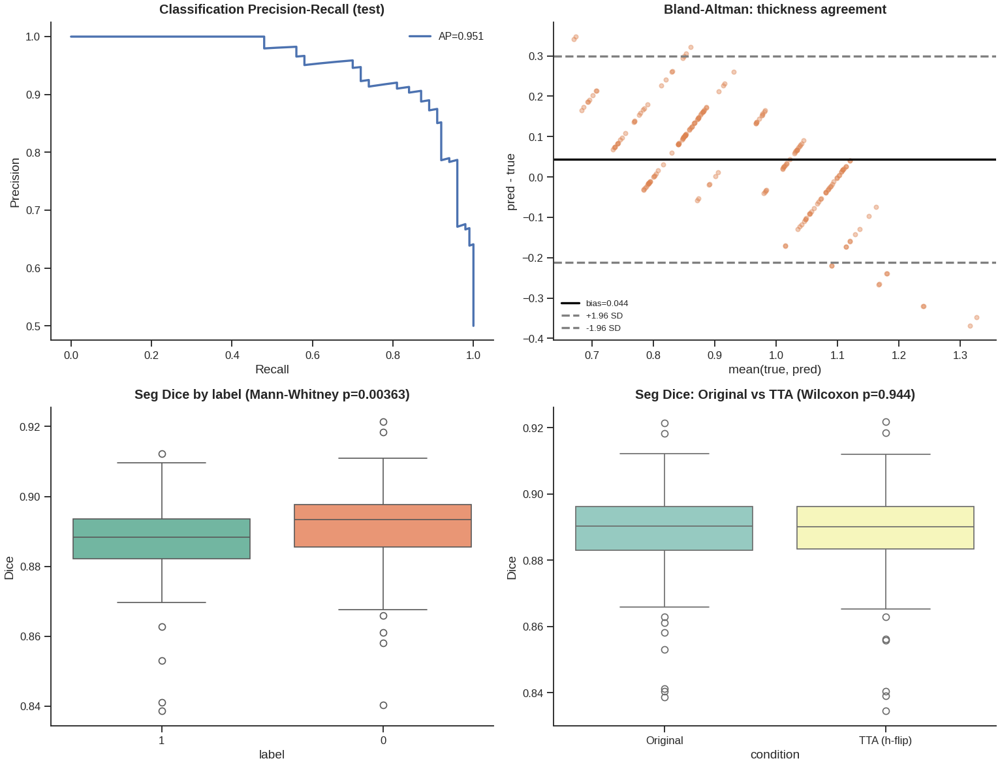

In [40]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

# --- Precision-Recall curve (classification) ---
prec, rec, _ = precision_recall_curve(cls_true, cls_probs)
ap = average_precision_score(cls_true, cls_probs)
axes[0, 0].plot(rec, prec, color="#4C72B0", label=f"AP={ap:.3f}")
axes[0, 0].set_title("Classification Precision-Recall (test)")
axes[0, 0].set_xlabel("Recall"); axes[0, 0].set_ylabel("Precision"); axes[0, 0].legend()

# --- Bland-Altman plot (thickness regression agreement) ---
mean_vals = (reg_true + reg_pred) / 2
diff_vals = reg_pred - reg_true
md_, sd_ = diff_vals.mean(), diff_vals.std()
axes[0, 1].scatter(mean_vals, diff_vals, alpha=0.4, s=15, color="#DD8452")
axes[0, 1].axhline(md_, color="black", linestyle="-", label=f"bias={md_:.3f}")
axes[0, 1].axhline(md_ + 1.96 * sd_, color="gray", linestyle="--", label="+1.96 SD")
axes[0, 1].axhline(md_ - 1.96 * sd_, color="gray", linestyle="--", label="-1.96 SD")
axes[0, 1].set_title("Bland-Altman: thickness agreement")
axes[0, 1].set_xlabel("mean(true, pred)"); axes[0, 1].set_ylabel("pred - true")
axes[0, 1].legend(fontsize=8)

# --- Dice by classification-label subgroup (Test 2) ---
sub_df = pd.DataFrame({"label": labels_arr.astype(str), "Dice": dice_orig})
sns.boxplot(x="label", y="Dice", data=sub_df, ax=axes[1, 0], palette="Set2")
axes[1, 0].set_title(f"Seg Dice by label (Mann-Whitney p={u_p:.3g})")

# --- Original vs TTA Dice (Test 1) ---
box_df = pd.DataFrame({
    "Dice": np.concatenate([dice_orig, dice_tta]),
    "condition": ["Original"] * len(dice_orig) + ["TTA (h-flip)"] * len(dice_tta),
})
sns.boxplot(x="condition", y="Dice", data=box_df, ax=axes[1, 1], palette="Set3")
axes[1, 1].set_title(f"Seg Dice: Original vs TTA (Wilcoxon p={w_p:.3g})")

plt.tight_layout()
plt.savefig(os.path.join(CFG2["out_dir"], "q1_statistical_analysis.png"), dpi=300)
plt.show()


## 17. Extra Imports (Q1 viz + XAI suite)

In [41]:
import math, itertools
from sklearn.manifold import TSNE
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss


## 18. Feature-Space Visualization (t-SNE of bottleneck features)

Bottleneck feature matrix: (200, 256)


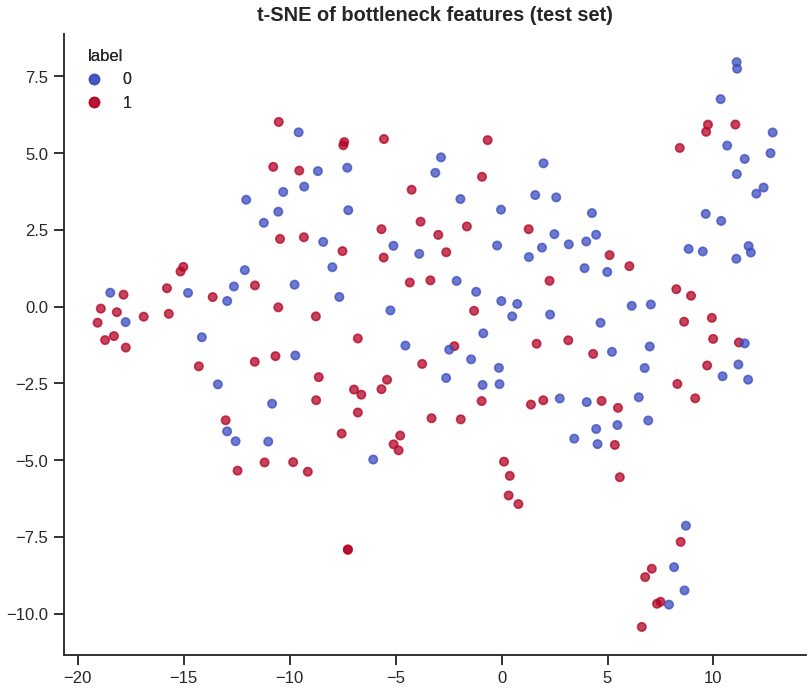

In [42]:
feat_store = {}
def _gap_hook(module, inp, out):
    feat_store["pooled"] = out.detach().flatten(1)
gap_handle = mt_model.gap.register_forward_hook(_gap_hook)

@torch.no_grad()
def collect_bottleneck_features(model, loader, device):
    model.eval()
    feats = []
    for imgs, masks, clin, labels, thick in loader:
        imgs, clin = imgs.to(device), clin.to(device)
        _ = model(imgs, clin)
        feats.append(feat_store["pooled"].cpu().numpy())
    return np.concatenate(feats, axis=0)

bottleneck_feats = collect_bottleneck_features(mt_model, mt_test_loader, device)
gap_handle.remove()
print("Bottleneck feature matrix:", bottleneck_feats.shape)

tsne = TSNE(n_components=2, random_state=42,
            perplexity=min(30, max(5, len(bottleneck_feats) // 3)))
feats_2d = tsne.fit_transform(bottleneck_feats)

fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(feats_2d[:, 0], feats_2d[:, 1], c=labels_arr, cmap="coolwarm", alpha=0.75, s=25)
legend1 = ax.legend(*sc.legend_elements(), title="label")
ax.add_artist(legend1)
ax.set_title("t-SNE of bottleneck features (test set)")
plt.tight_layout()
plt.savefig(os.path.join(CFG2["out_dir"], "tsne_bottleneck_features.png"), dpi=300)
plt.show()


## 19. Calibration Curve (Reliability Diagram)

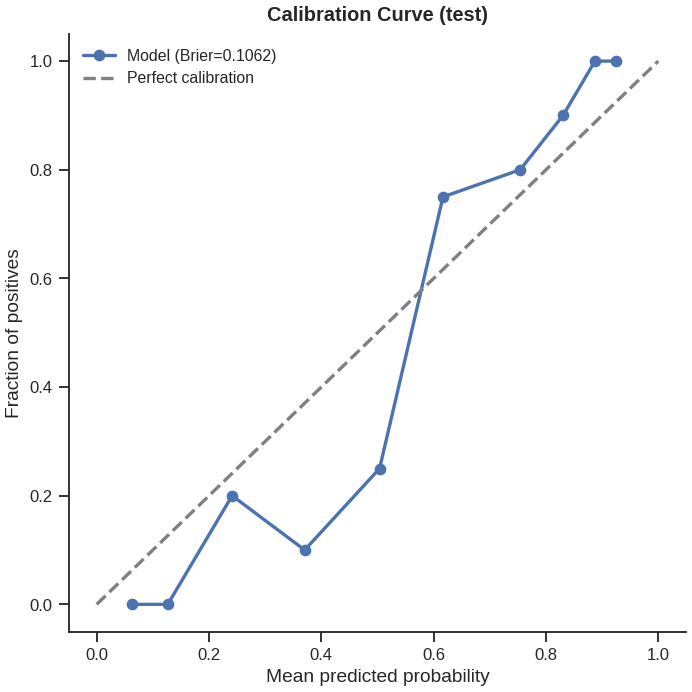

In [43]:
frac_pos, mean_pred = calibration_curve(cls_true, cls_probs, n_bins=10, strategy="quantile")
brier = brier_score_loss(cls_true, cls_probs)

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(mean_pred, frac_pos, marker="o", color="#4C72B0", label=f"Model (Brier={brier:.4f})")
ax.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Fraction of positives")
ax.set_title("Calibration Curve (test)")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(CFG2["out_dir"], "calibration_curve.png"), dpi=300)
plt.show()


## 20. Regression Residual Diagnostics

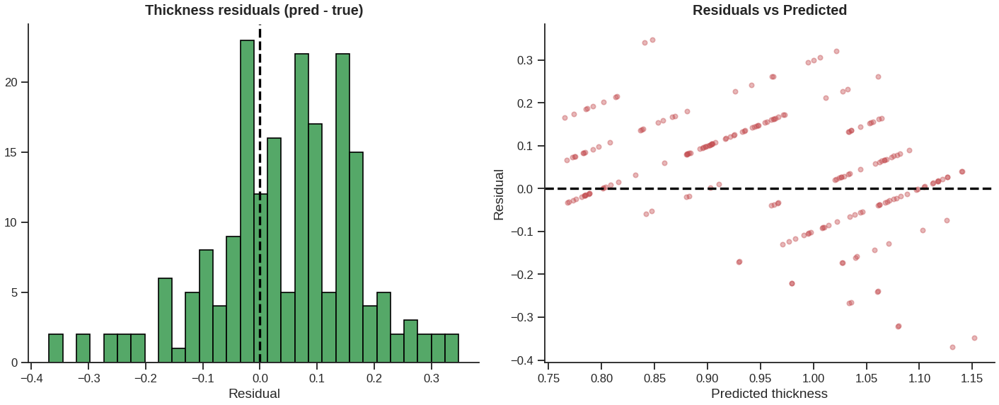

In [44]:
residuals = reg_pred - reg_true

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].hist(residuals, bins=30, color="#55A868", edgecolor="black")
axes[0].axvline(0, color="black", linestyle="--")
axes[0].set_title("Thickness residuals (pred - true)")
axes[0].set_xlabel("Residual")

axes[1].scatter(reg_pred, residuals, alpha=0.4, s=15, color="#C44E52")
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_xlabel("Predicted thickness"); axes[1].set_ylabel("Residual")
axes[1].set_title("Residuals vs Predicted")

plt.tight_layout()
plt.savefig(os.path.join(CFG2["out_dir"], "regression_residuals.png"), dpi=300)
plt.show()


## 21. Subgroup Fairness ROC (by gender)

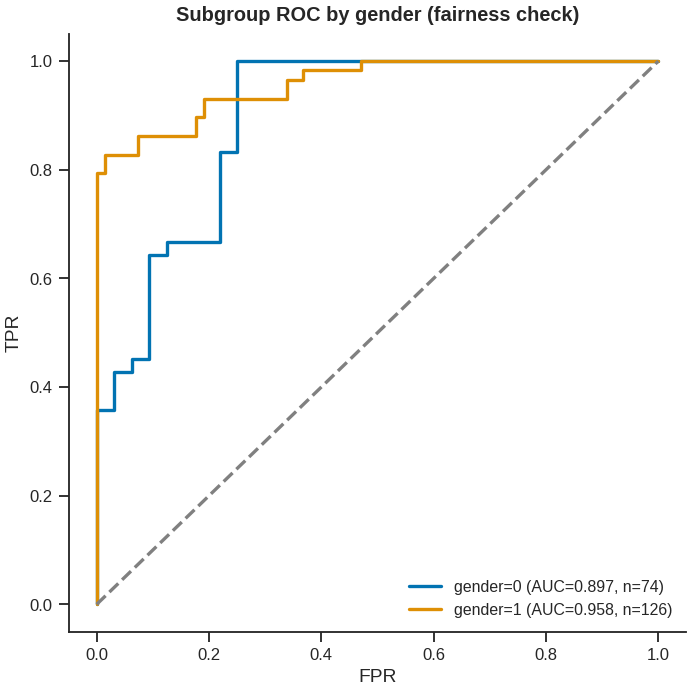

In [45]:
gender_arr = mt_test_df["gender"].values

fig, ax = plt.subplots(figsize=(6, 6))
for g in np.unique(gender_arr):
    m = gender_arr == g
    if len(np.unique(cls_true[m])) < 2:
        continue
    fpr_g, tpr_g, _ = roc_curve(cls_true[m], cls_probs[m])
    auc_g = roc_auc_score(cls_true[m], cls_probs[m])
    ax.plot(fpr_g, tpr_g, label=f"gender={g} (AUC={auc_g:.3f}, n={m.sum()})")
ax.plot([0, 1], [0, 1], "--", color="gray")
ax.set_title("Subgroup ROC by gender (fairness check)")
ax.set_xlabel("FPR"); ax.set_ylabel("TPR"); ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(CFG2["out_dir"], "fairness_roc_gender.png"), dpi=300)
plt.show()


## 22. Qualitative Segmentation: Best / Median / Worst Cases

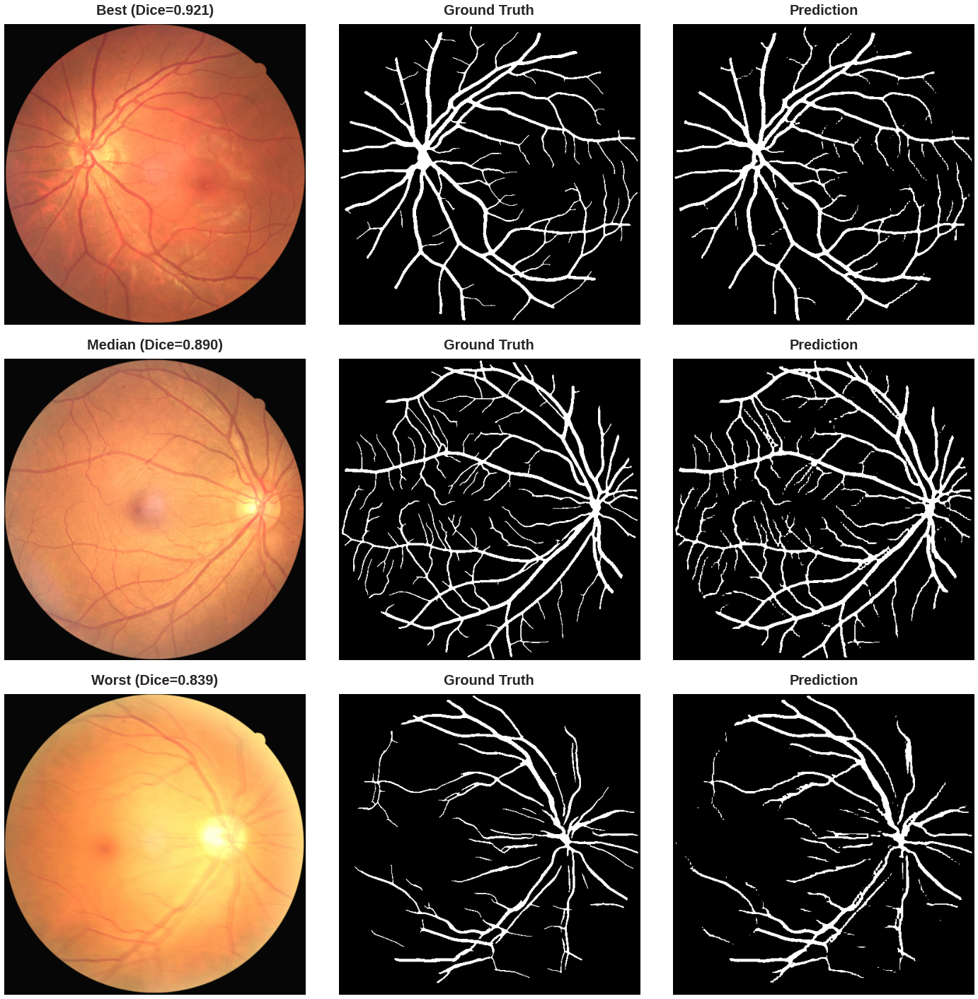

In [46]:
dice_order = np.argsort(dice_orig)
sample_idxs = [dice_order[-1], dice_order[len(dice_order) // 2], dice_order[0]]  # best, median, worst
sample_labels = ["Best", "Median", "Worst"]

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
for row, idx in enumerate(sample_idxs):
    row_data = mt_test_df.iloc[idx]
    base = os.path.splitext(row_data["image_name"])[0]
    img = Image.open(os.path.join(CFG2["images_dir"], base + ".png")).convert("RGB").resize(
        (CFG2["img_size"], CFG2["img_size"]))
    mask = Image.open(os.path.join(CFG2["masks_dir"], base + "_mask.png")).convert("L").resize(
        (CFG2["img_size"], CFG2["img_size"]))
    img_np = np.array(img).astype(np.float32) / 255.0
    img_t = torch.from_numpy(img_np).permute(2, 0, 1).unsqueeze(0).float().to(device)
    clin_t = torch.tensor([[row_data["age"], row_data["gender"]]], dtype=torch.float32).to(device)

    with torch.no_grad():
        seg_logits, _, _ = mt_model(img_t, clin_t)
        pred_mask = (torch.sigmoid(seg_logits) > 0.5).float().cpu().squeeze().numpy()

    axes[row, 0].imshow(img_np); axes[row, 0].set_title(f"{sample_labels[row]} (Dice={dice_orig[idx]:.3f})")
    axes[row, 1].imshow(mask, cmap="gray"); axes[row, 1].set_title("Ground Truth")
    axes[row, 2].imshow(pred_mask, cmap="gray"); axes[row, 2].set_title("Prediction")
    for a in axes[row]:
        a.axis("off")

plt.tight_layout()
plt.savefig(os.path.join(CFG2["out_dir"], "qualitative_best_median_worst.png"), dpi=300)
plt.show()


## 23. Bootstrap CI Bar Chart

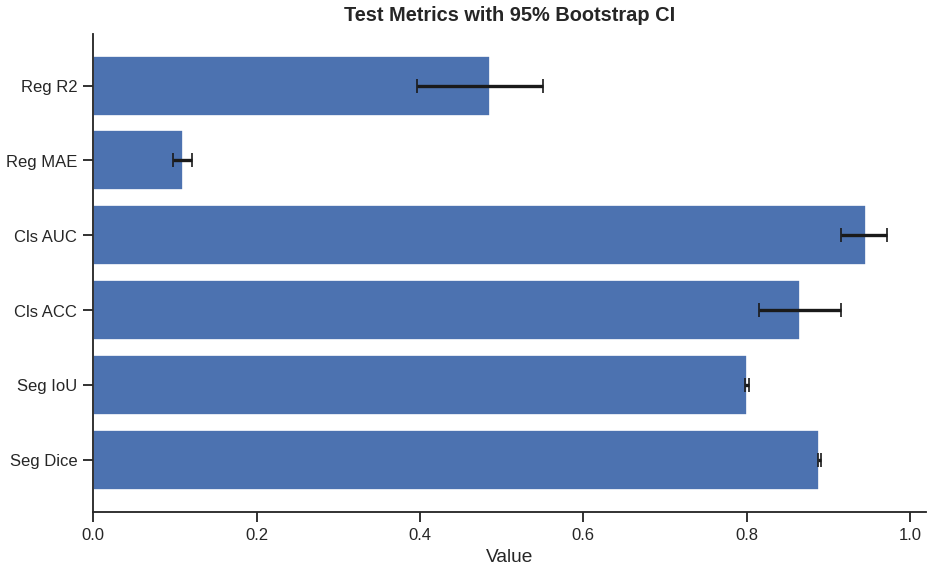

In [47]:
fig, ax = plt.subplots(figsize=(8, 5))
y_pos = np.arange(len(ci_df))
ax.barh(y_pos, ci_df["value"],
        xerr=[ci_df["value"] - ci_df["ci_low"], ci_df["ci_high"] - ci_df["value"]],
        color="#4C72B0", capsize=4)
ax.set_yticks(y_pos); ax.set_yticklabels(ci_df["metric"])
ax.set_xlabel("Value"); ax.set_title("Test Metrics with 95% Bootstrap CI")
plt.tight_layout()
plt.savefig(os.path.join(CFG2["out_dir"], "bootstrap_ci_barchart.png"), dpi=300)
plt.show()


## 24. Explainable AI — Grad-CAM (Classification & Regression Heads)

Target layer: `mt_model.spp.fuse` (final conv feeding the shared bottleneck feature `b`, used by both the GAP branch and the segmentation decoder).

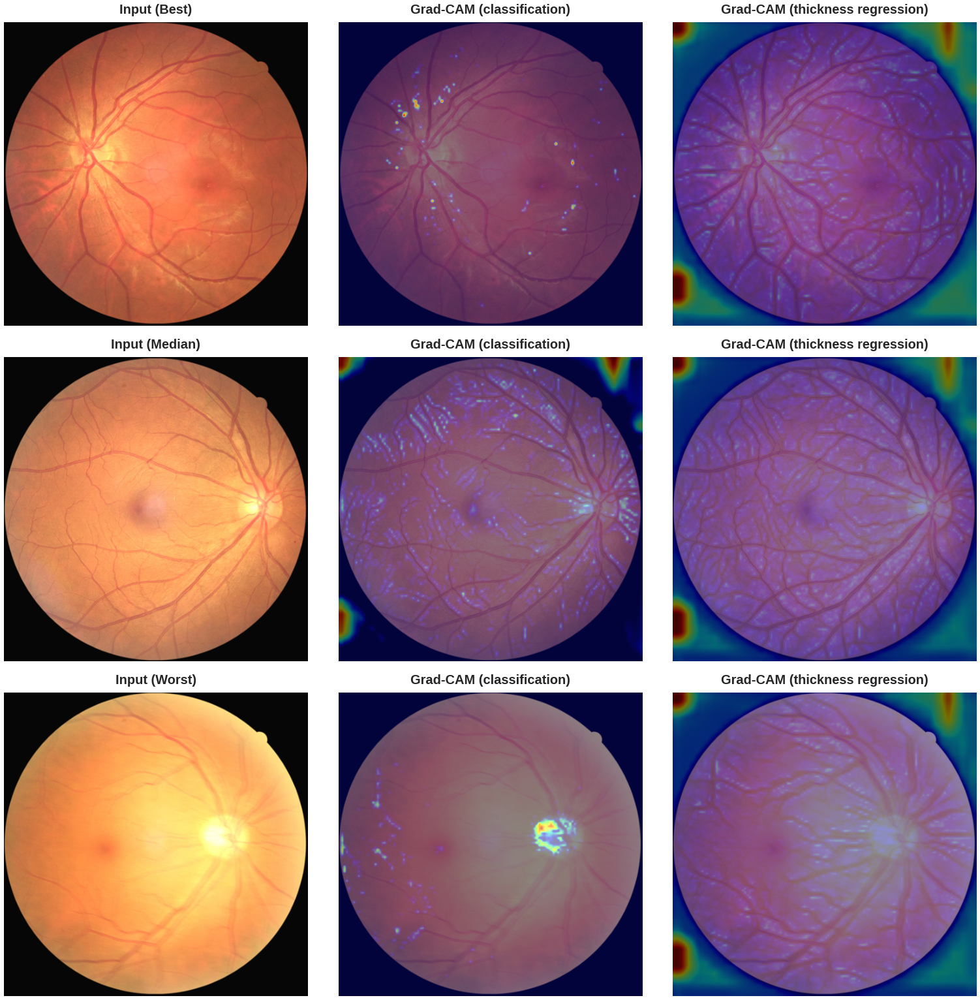

In [48]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.gradients = None
        self.activations = None
        target_layer.register_forward_hook(self._fwd)
        target_layer.register_full_backward_hook(self._bwd)

    def _fwd(self, module, inp, out):
        self.activations = out

    def _bwd(self, module, grad_in, grad_out):
        self.gradients = grad_out[0]

    def generate(self, img_t, clin_t, target="cls"):
        self.model.zero_grad()
        seg_logits, cls_logit, reg_pred = self.model(img_t, clin_t)
        score = cls_logit.sum() if target == "cls" else reg_pred.sum()
        score.backward()
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((weights * self.activations).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=img_t.shape[-2:], mode="bilinear", align_corners=False)
        cam = cam.squeeze().detach().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam


gradcam = GradCAM(mt_model, mt_model.fuse)

fig, axes = plt.subplots(3, 3, figsize=(13, 13))
for row, idx in enumerate(sample_idxs):
    row_data = mt_test_df.iloc[idx]
    base = os.path.splitext(row_data["image_name"])[0]
    img = Image.open(os.path.join(CFG2["images_dir"], base + ".png")).convert("RGB").resize(
        (CFG2["img_size"], CFG2["img_size"]))
    img_np = np.array(img).astype(np.float32) / 255.0
    img_t = torch.from_numpy(img_np).permute(2, 0, 1).unsqueeze(0).float().to(device)
    clin_t = torch.tensor([[row_data["age"], row_data["gender"]]], dtype=torch.float32).to(device)

    cam_cls = gradcam.generate(img_t, clin_t, target="cls")
    cam_reg = gradcam.generate(img_t, clin_t, target="reg")

    axes[row, 0].imshow(img_np); axes[row, 0].set_title(f"Input ({sample_labels[row]})"); axes[row, 0].axis("off")
    axes[row, 1].imshow(img_np); axes[row, 1].imshow(cam_cls, cmap="jet", alpha=0.45)
    axes[row, 1].set_title("Grad-CAM (classification)"); axes[row, 1].axis("off")
    axes[row, 2].imshow(img_np); axes[row, 2].imshow(cam_reg, cmap="jet", alpha=0.45)
    axes[row, 2].set_title("Grad-CAM (thickness regression)"); axes[row, 2].axis("off")

plt.tight_layout()
plt.savefig(os.path.join(CFG2["out_dir"], "gradcam_overlays.png"), dpi=300)
plt.show()


## 25. Explainable AI — Integrated Gradients

Pixel-level attribution vs a black-image baseline (30 interpolation steps — slow, ~30 forward+backward passes per image).

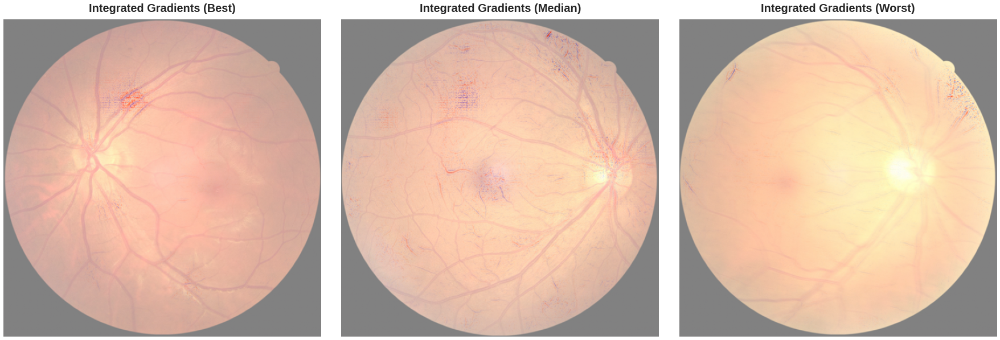

In [49]:
def integrated_gradients(model, img_t, clin_t, target="cls", steps=30, baseline=None):
    if baseline is None:
        baseline = torch.zeros_like(img_t)
    grads = []
    for i in range(steps + 1):
        alpha = i / steps
        s = (baseline + alpha * (img_t - baseline)).clone().requires_grad_(True)
        seg_logits, cls_logit, reg_pred = model(s, clin_t)
        score = cls_logit.sum() if target == "cls" else reg_pred.sum()
        model.zero_grad()
        grad = torch.autograd.grad(score, s)[0]
        grads.append(grad.detach())
    avg_grad = torch.stack(grads).mean(dim=0)
    ig = ((img_t - baseline) * avg_grad).sum(dim=1, keepdim=True)
    return ig.squeeze().cpu().numpy()


fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for col, idx in enumerate(sample_idxs):
    row_data = mt_test_df.iloc[idx]
    base = os.path.splitext(row_data["image_name"])[0]
    img = Image.open(os.path.join(CFG2["images_dir"], base + ".png")).convert("RGB").resize(
        (CFG2["img_size"], CFG2["img_size"]))
    img_np = np.array(img).astype(np.float32) / 255.0
    img_t = torch.from_numpy(img_np).permute(2, 0, 1).unsqueeze(0).float().to(device)
    clin_t = torch.tensor([[row_data["age"], row_data["gender"]]], dtype=torch.float32).to(device)

    ig_map = integrated_gradients(mt_model, img_t, clin_t, target="cls", steps=30)
    vmax = np.abs(ig_map).max() + 1e-8

    axes[col].imshow(img_np)
    axes[col].imshow(ig_map, cmap="bwr", alpha=0.5, vmin=-vmax, vmax=vmax)
    axes[col].set_title(f"Integrated Gradients ({sample_labels[col]})")
    axes[col].axis("off")

plt.tight_layout()
plt.savefig(os.path.join(CFG2["out_dir"], "integrated_gradients.png"), dpi=300)
plt.show()


## 26. Explainable AI — Occlusion Sensitivity

Patch-based perturbation: slides a 64x64 zeroed patch, measures score drop (64 forward passes/image at stride=64).

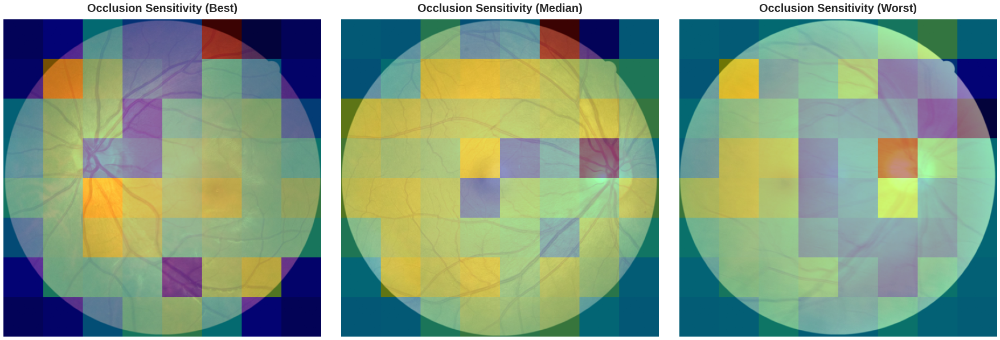

In [50]:
@torch.no_grad()
def occlusion_sensitivity(model, img_t, clin_t, target="cls", patch=64, stride=64):
    model.eval()
    _, base_cls, base_reg = model(img_t, clin_t)
    base_score = base_cls.item() if target == "cls" else base_reg.item()
    H, W = img_t.shape[-2:]
    heat = np.zeros((H, W)); counts = np.zeros((H, W))
    for y in range(0, H - patch + 1, stride):
        for x in range(0, W - patch + 1, stride):
            occ = img_t.clone()
            occ[:, :, y:y + patch, x:x + patch] = 0.0
            _, cls_o, reg_o = model(occ, clin_t)
            score = cls_o.item() if target == "cls" else reg_o.item()
            heat[y:y + patch, x:x + patch] += (base_score - score)
            counts[y:y + patch, x:x + patch] += 1
    return heat / np.maximum(counts, 1)


fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for col, idx in enumerate(sample_idxs):
    row_data = mt_test_df.iloc[idx]
    base = os.path.splitext(row_data["image_name"])[0]
    img = Image.open(os.path.join(CFG2["images_dir"], base + ".png")).convert("RGB").resize(
        (CFG2["img_size"], CFG2["img_size"]))
    img_np = np.array(img).astype(np.float32) / 255.0
    img_t = torch.from_numpy(img_np).permute(2, 0, 1).unsqueeze(0).float().to(device)
    clin_t = torch.tensor([[row_data["age"], row_data["gender"]]], dtype=torch.float32).to(device)

    occ_map = occlusion_sensitivity(mt_model, img_t, clin_t, target="cls")

    axes[col].imshow(img_np)
    axes[col].imshow(occ_map, cmap="jet", alpha=0.45)
    axes[col].set_title(f"Occlusion Sensitivity ({sample_labels[col]})")
    axes[col].axis("off")

plt.tight_layout()
plt.savefig(os.path.join(CFG2["out_dir"], "occlusion_sensitivity.png"), dpi=300)
plt.show()


## 27. Explainable AI — Exact Shapley Values for Clinical Features (age, gender)

Only 2 clinical features -> exact Shapley (all coalitions), no approximation needed. Baseline = train-set mean age/gender.

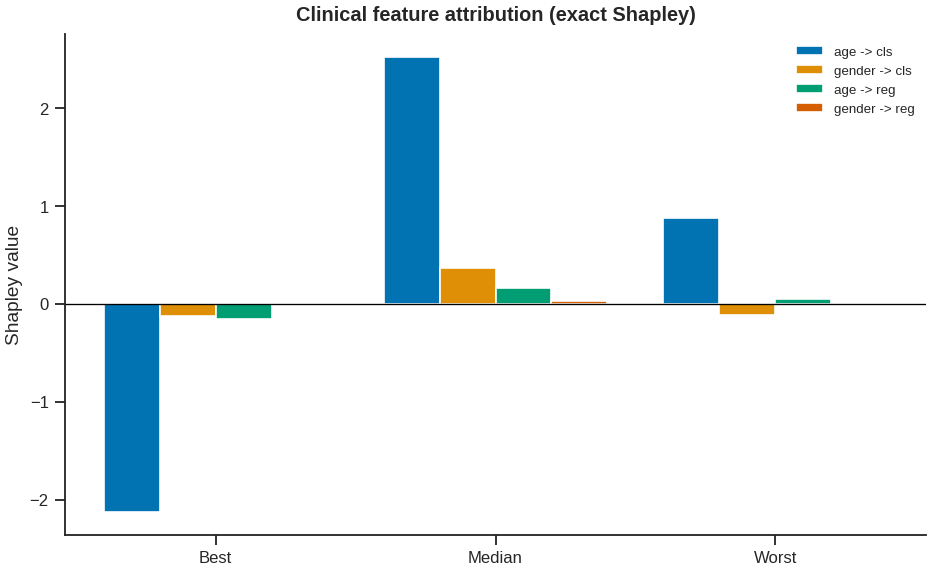

,case,image,age_shap_cls,gender_shap_cls,age_shap_reg,gender_shap_reg
0,Best,362566003_L.png,-2.131649,-0.122930,-0.155048,-0.014431
1,Median,152071010_R.png,2.527931,0.364770,0.166039,0.029565
2,Worst,180082004_R.png,0.874519,-0.114657,0.053920,-0.004086


In [51]:
def exact_shapley_clinical(model, img_t, clin_instance, clin_baseline, target="cls"):
    feats = list(range(clin_instance.shape[0]))
    n = len(feats)

    @torch.no_grad()
    def value_fn(subset):
        clin = clin_baseline.clone()
        for i in subset:
            clin[i] = clin_instance[i]
        _, cls_o, reg_o = model(img_t, clin.unsqueeze(0))
        return cls_o.item() if target == "cls" else reg_o.item()

    shapley = np.zeros(n)
    for i in feats:
        others = [f for f in feats if f != i]
        for r in range(len(others) + 1):
            for subset in itertools.combinations(others, r):
                subset = list(subset)
                w = (math.factorial(len(subset)) * math.factorial(n - len(subset) - 1)) / math.factorial(n)
                shapley[i] += w * (value_fn(subset + [i]) - value_fn(subset))
    return shapley


clin_baseline = torch.tensor([mt_train_df["age"].mean(), mt_train_df["gender"].mean()],
                              dtype=torch.float32).to(device)

shap_rows = []
for idx, label in zip(sample_idxs, sample_labels):
    row_data = mt_test_df.iloc[idx]
    base = os.path.splitext(row_data["image_name"])[0]
    img = Image.open(os.path.join(CFG2["images_dir"], base + ".png")).convert("RGB").resize(
        (CFG2["img_size"], CFG2["img_size"]))
    img_np = np.array(img).astype(np.float32) / 255.0
    img_t = torch.from_numpy(img_np).permute(2, 0, 1).unsqueeze(0).float().to(device)
    clin_instance = torch.tensor([row_data["age"], row_data["gender"]], dtype=torch.float32).to(device)

    sv_cls = exact_shapley_clinical(mt_model, img_t, clin_instance, clin_baseline, target="cls")
    sv_reg = exact_shapley_clinical(mt_model, img_t, clin_instance, clin_baseline, target="reg")
    shap_rows.append({"case": label, "image": row_data["image_name"],
                       "age_shap_cls": sv_cls[0], "gender_shap_cls": sv_cls[1],
                       "age_shap_reg": sv_reg[0], "gender_shap_reg": sv_reg[1]})

shap_df = pd.DataFrame(shap_rows)
shap_df.to_csv(os.path.join(CFG2["out_dir"], "clinical_shapley_values.csv"), index=False)

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(shap_df))
width = 0.2
ax.bar(x - 1.5 * width, shap_df["age_shap_cls"], width, label="age -> cls")
ax.bar(x - 0.5 * width, shap_df["gender_shap_cls"], width, label="gender -> cls")
ax.bar(x + 0.5 * width, shap_df["age_shap_reg"], width, label="age -> reg")
ax.bar(x + 1.5 * width, shap_df["gender_shap_reg"], width, label="gender -> reg")
ax.set_xticks(x); ax.set_xticklabels(shap_df["case"])
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Shapley value"); ax.set_title("Clinical feature attribution (exact Shapley)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(CFG2["out_dir"], "clinical_shapley_barplot.png"), dpi=300)
plt.show()
shap_df


## 28. Explainable AI — Monte Carlo Dropout Uncertainty (Segmentation)

20 stochastic forward passes with dropout kept active at inference -> per-pixel mean (prediction) and std (epistemic uncertainty).

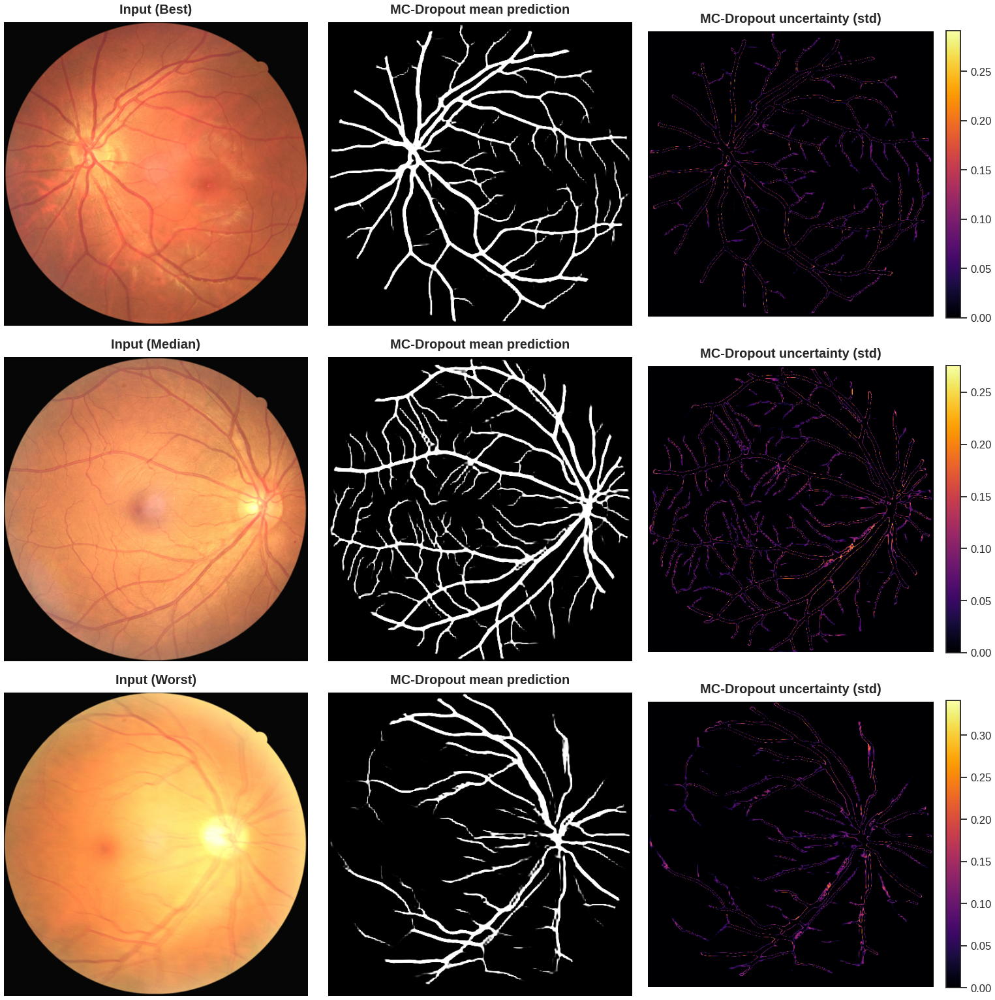

In [52]:
def enable_mc_dropout(model):
    for m in model.modules():
        if isinstance(m, (nn.Dropout, nn.Dropout2d)):
            m.train()


@torch.no_grad()
def mc_dropout_uncertainty(model, img_t, clin_t, n_samples=20):
    model.eval()
    enable_mc_dropout(model)
    preds = []
    for _ in range(n_samples):
        seg_logits, _, _ = model(img_t, clin_t)
        preds.append(torch.sigmoid(seg_logits).cpu().numpy())
    preds = np.stack(preds, axis=0)
    mean_map = preds.mean(axis=0).squeeze()
    std_map = preds.std(axis=0).squeeze()
    model.eval()
    return mean_map, std_map


fig, axes = plt.subplots(3, 3, figsize=(13, 13))
for row, idx in enumerate(sample_idxs):
    row_data = mt_test_df.iloc[idx]
    base = os.path.splitext(row_data["image_name"])[0]
    img = Image.open(os.path.join(CFG2["images_dir"], base + ".png")).convert("RGB").resize(
        (CFG2["img_size"], CFG2["img_size"]))
    img_np = np.array(img).astype(np.float32) / 255.0
    img_t = torch.from_numpy(img_np).permute(2, 0, 1).unsqueeze(0).float().to(device)
    clin_t = torch.tensor([[row_data["age"], row_data["gender"]]], dtype=torch.float32).to(device)

    mean_map, std_map = mc_dropout_uncertainty(mt_model, img_t, clin_t, n_samples=20)

    axes[row, 0].imshow(img_np); axes[row, 0].set_title(f"Input ({sample_labels[row]})"); axes[row, 0].axis("off")
    axes[row, 1].imshow(mean_map, cmap="gray"); axes[row, 1].set_title("MC-Dropout mean prediction"); axes[row, 1].axis("off")
    im = axes[row, 2].imshow(std_map, cmap="inferno"); axes[row, 2].set_title("MC-Dropout uncertainty (std)"); axes[row, 2].axis("off")
    fig.colorbar(im, ax=axes[row, 2], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.savefig(os.path.join(CFG2["out_dir"], "mc_dropout_uncertainty.png"), dpi=300)
plt.show()


# Part II — Additional Tables & Figures for Journal (Q1) Submission

Sections 29–41 add the evidence a Q1 reviewer normally expects on top of Sections 1–28:
dataset description, implementation details, model complexity, ablation, baseline comparison,
full metric tables with confidence intervals, clinical-utility analysis, robustness, subgroup
analysis and a reproducibility package.

**Run order:** Sections 1–28 first (they create `mt_model`, `mt_test_df`, `cls_probs`, ...), then 29–41.

| Item | Section | Output file |
|---|---|---|
| Table 1 – Dataset & cohort characteristics | 29 | `table1_dataset_characteristics.csv` |
| Fig. A – Cohort distributions | 29 | `figA_cohort_distributions.png` |
| Table 2 – Implementation details / hyper-parameters | 30 | `table2_hyperparameters.csv` |
| Table 3 – Model complexity & inference cost | 30 | `table3_model_complexity.csv` |
| Table 4 – Segmentation: full metrics + 95% CI | 31 | `table4_segmentation_full.csv` |
| Fig. B – Segmentation threshold sensitivity | 31 | `figB_seg_threshold_sensitivity.png` |
| Table 5 – Classification: full metrics + 95% CI | 32 | `table5_classification_full.csv` |
| Fig. C – Decision-curve, threshold analysis | 32 | `figC_classification_clinical_utility.png` |
| Table 6 – Regression: full agreement metrics + 95% CI | 33 | `table6_regression_full.csv` |
| Fig. D – Regression error analysis | 33 | `figD_regression_error_analysis.png` |
| Table 7 / Fig. E – Ablation (architecture + multi-task) | 34 | `table7_ablation.csv`, `figE_ablation.png` |
| Table 8 / Fig. F – Baseline comparison (seg / cls / reg) | 35 | `table8_*.csv`, `figF_*.png` |
| Table 9 / Fig. G – Robustness to image degradation | 36 | `table9_robustness.csv`, `figG_robustness.png` |
| Table 10 / Fig. H – Subgroup analysis (gender, age) | 37 | `table10_subgroups.csv`, `figH_subgroups.png` |
| Fig. I – Vessel biomarkers vs. clinical outcome | 38 | `figI_vessel_biomarkers.png`, `table11_*.csv` |
| Fig. J – Loss components / training dynamics | 39 | `figJ_training_dynamics.png` |
| Reproducibility package (xlsx / LaTeX / zip) | 40 | `q1_all_tables.xlsx`, `q1_all_tables.tex` |
| Limitations & conclusion | 41 | — |

## 29. Dataset & Cohort Characteristics (Table 1, Fig. A)

Cohort description per split (train / validation / test): number of images, patients,
class balance, age, gender, thickness. Between-split differences are tested
(χ² for categorical, Kruskal–Wallis for continuous) to demonstrate that the patient-level
split did not introduce a distribution shift.

In [53]:
import warnings
warnings.filterwarnings("ignore")
from scipy.stats import chi2_contingency, kruskal

Q1_DIR = os.path.join(CFG2["out_dir"], "q1_outputs")
os.makedirs(Q1_DIR, exist_ok=True)
TABLES = {}          # name -> DataFrame, exported in Section 40

def save_table(df, name, index=True):
    TABLES[name] = df.copy()
    df.to_csv(os.path.join(Q1_DIR, name + ".csv"), index=index)
    return df

def save_fig(fig, name, dpi=300):
    """Save a publication-ready figure: PNG (preview), PDF (vector, embedded fonts), TIFF (LZW, for journals that require it)."""
    base = os.path.join(Q1_DIR, name)
    fig.savefig(base + ".png", dpi=dpi, bbox_inches="tight", facecolor="white")
    fig.savefig(base + ".pdf", bbox_inches="tight", facecolor="white")
    try:
        fig.savefig(base + ".tiff", dpi=dpi, bbox_inches="tight", facecolor="white", pil_kwargs={"compression": "tiff_lzw"})
    except Exception as e:
        print("TIFF export skipped:", e)

pid_fn = lambda name: get_patient_id(os.path.splitext(name)[0])
splits = {"Train": mt_train_df, "Validation": mt_val_df, "Test": mt_test_df}

rows = []
for sname, d in splits.items():
    n_pat = d["image_name"].map(pid_fn).nunique()
    rows.append({
        "Split": sname,
        "Images": len(d),
        "Patients": n_pat,
        "Label 1 (n, %)": f"{int((d['label']==1).sum())} ({100*(d['label']==1).mean():.1f}%)",
        "Label 0 (n, %)": f"{int((d['label']==0).sum())} ({100*(d['label']==0).mean():.1f}%)",
        "Age (mean ± SD)": f"{d['age'].mean():.1f} ± {d['age'].std():.1f}",
        "Gender=1 (n, %)": f"{int((d['gender']==1).sum())} ({100*(d['gender']==1).mean():.1f}%)",
        "Thickness (mean ± SD)": f"{d['thickness'].mean():.3f} ± {d['thickness'].std():.3f}",
        "Thickness (median [IQR])": f"{d['thickness'].median():.3f} [{d['thickness'].quantile(.25):.3f}, {d['thickness'].quantile(.75):.3f}]",
    })
table1 = pd.DataFrame(rows).set_index("Split")

# between-split tests
all_df = pd.concat([d.assign(split=s) for s, d in splits.items()])
p_label  = chi2_contingency(pd.crosstab(all_df["split"], all_df["label"]))[1]
p_gender = chi2_contingency(pd.crosstab(all_df["split"], all_df["gender"]))[1]
p_age    = kruskal(*[d["age"].values for d in splits.values()])[1]
p_thick  = kruskal(*[d["thickness"].values for d in splits.values()])[1]
table1.loc["p-value (between splits)"] = ["", "", f"{p_label:.3g}", "", f"{p_age:.3g}", f"{p_gender:.3g}", f"{p_thick:.3g}", ""]
save_table(table1, "table1_dataset_characteristics")
print("Total images:", sum(len(d) for d in splits.values()),
      "| segmentation GT masks: ", len(file_list), "matched pairs")
table1

Total images: 5806 | segmentation GT masks:  5806 matched pairs


,Images,Patients,"Label 1 (n, %)","Label 0 (n, %)",Age (mean ± SD),"Gender=1 (n, %)",Thickness (mean ± SD),Thickness (median [IQR])
Split,,,,,,,,
Train,5206,2603,3808 (73.1%),1398 (26.9%),0.5 ± 0.2,3374 (64.8%),0.995 ± 0.184,"1.100 [0.800, 1.100]"
Validation,400,200,200 (50.0%),200 (50.0%),0.5 ± 0.2,224 (56.0%),0.924 ± 0.214,"0.850 [0.800, 1.100]"
Test,200,100,100 (50.0%),100 (50.0%),0.5 ± 0.2,126 (63.0%),0.914 ± 0.192,"0.850 [0.800, 1.100]"
p-value (between splits),,,5.66e-31,,0.0798,0.00179,7.78e-19,


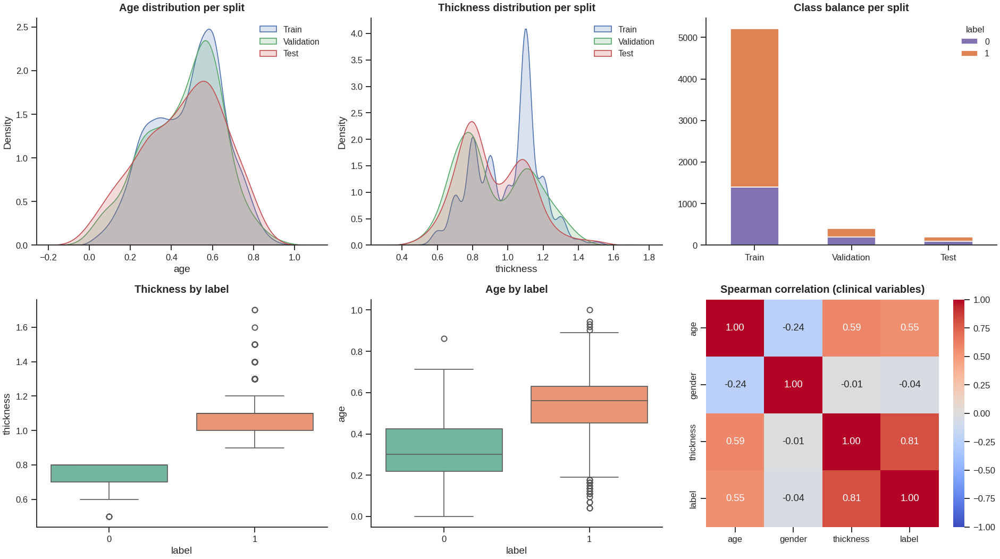

In [54]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
colors = {"Train": "#4C72B0", "Validation": "#55A868", "Test": "#C44E52"}

for sname, d in splits.items():
    sns.kdeplot(d["age"], ax=axes[0, 0], label=sname, color=colors[sname], fill=True, alpha=0.2)
    sns.kdeplot(d["thickness"], ax=axes[0, 1], label=sname, color=colors[sname], fill=True, alpha=0.2)
axes[0, 0].set_title("Age distribution per split"); axes[0, 0].legend()
axes[0, 1].set_title("Thickness distribution per split"); axes[0, 1].legend()

lab = all_df.groupby(["split", "label"]).size().unstack(fill_value=0).loc[["Train", "Validation", "Test"]]
lab.plot(kind="bar", stacked=True, ax=axes[0, 2], color=["#8172B2", "#DD8452"])
axes[0, 2].set_title("Class balance per split"); axes[0, 2].set_xlabel(""); axes[0, 2].tick_params(axis="x", rotation=0)

sns.boxplot(x="label", y="thickness", data=all_df, ax=axes[1, 0], palette="Set2")
axes[1, 0].set_title("Thickness by label")
sns.boxplot(x="label", y="age", data=all_df, ax=axes[1, 1], palette="Set2")
axes[1, 1].set_title("Age by label")

corr = all_df[["age", "gender", "thickness", "label"]].corr(method="spearman")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1, 2], vmin=-1, vmax=1)
axes[1, 2].set_title("Spearman correlation (clinical variables)")

plt.tight_layout()
save_fig(fig, "figA_cohort_distributions")
plt.show()

## 30. Implementation Details & Model Complexity (Tables 2 and 3)

Table 2 lists every hyper-parameter (needed for reproducibility). Table 3 reports trainable
parameters, FLOPs (MACs via forward-hook counting, deformable conv counted analytically),
peak GPU memory and latency, for the segmentation-only and multi-task networks.

In [55]:
import platform, sklearn
hp = {
    "Framework": f"PyTorch {torch.__version__}, torchvision {__import__('torchvision').__version__}",
    "Python": platform.python_version(),
    "Hardware": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
    "Input size": f"{CFG2['img_size']}×{CFG2['img_size']}×3 (RGB, scaled to [0,1], no mean/std normalisation)",
    "Base channels / depth": "16 / 4 down-sampling stages + SPP bottleneck (256 ch)",
    "Activation": "LeakyReLU (slope 0.01)",
    "Normalisation": "BatchNorm2d",
    "Dropout (enc/dec/bottleneck)": "0.1–0.2 / 0.1–0.2 / 0.3 (Dropout2d); 0.3 in shared FC",
    "Optimizer": "Adam (β=(0.9, 0.999), no weight decay)",
    "Learning rate": f"{CFG2['lr']} (ReduceLROnPlateau, factor 0.5, patience 5)",
    "Batch size": CFG2["batch_size"],
    "Epochs (seg only / multi-task)": f"{CFG['epochs']} / {CFG2['epochs']}",
    "Segmentation loss": f"Dice + {CFG2['lam']}·Focal (α=0.8, γ=2)",
    "Classification loss": "BCEWithLogits, pos_weight = n_neg/n_pos",
    "Regression loss": "SmoothL1",
    "Task weights (seg/cls/reg)": f"{CFG2['w_seg']} / {CFG2['w_cls']} / {CFG2['w_reg']}",
    "Model selection": "val seg_ACC + cls_ACC − reg_MAE (multi-task); val ACC (seg only)",
    "Augmentation": "h-flip (p=0.5), rotation ±15°, Gaussian noise σ=0.02 (train only)",
    "Data split": "Patient-level, CSV `group` column (1=train, 2=val, 3=test); leakage asserted",
    "Random seed": CFG2["seed"],
}
table2 = pd.DataFrame({"Value": pd.Series(hp)})
save_table(table2, "table2_hyperparameters")
table2

,Value
Framework,"PyTorch 2.11.0+cu128, torchvision 0.26.0+cu128"
Python,3.13.15
Hardware,Tesla T4
Input size,"512×512×3 (RGB, scaled to [0,1], no mean/std n..."
Base channels / depth,16 / 4 down-sampling stages + SPP bottleneck (...
Activation,LeakyReLU (slope 0.01)
Normalisation,BatchNorm2d
Dropout (enc/dec/bottleneck),0.1–0.2 / 0.1–0.2 / 0.3 (Dropout2d); 0.3 in sh...
Optimizer,"Adam (β=(0.9, 0.999), no weight decay)"
Learning rate,"0.0001 (ReduceLROnPlateau, factor 0.5, patienc..."


In [56]:
# ---- FLOPs (MACs) counter ----
def count_macs(model, inputs):
    macs = [0]
    hooks = []
    def conv_hook(m, i, o):
        k = m.kernel_size[0] * m.kernel_size[1]
        macs[0] += o.numel() * (m.in_channels // m.groups) * k
    def deform_hook(m, i, o):
        k = m.kernel_size[0] * m.kernel_size[1]
        # sampling + weighted conv: same MACs as conv, ×4 for bilinear interpolation of each sampled value
        macs[0] += o.numel() * m.in_channels * k + 4 * o.shape[2] * o.shape[3] * m.in_channels * k
    def lin_hook(m, i, o):
        macs[0] += o.numel() * m.in_features
    def attn_hook(m, i, o):
        B_, N_, D_ = i[0].shape
        macs[0] += 2 * B_ * N_ * m._nkv * D_   # QK^T + AV (keys reduced by sr_ratio)
    from torchvision.ops import DeformConv2d as _DC
    for m in model.modules():
        if isinstance(m, _DC): hooks.append(m.register_forward_hook(deform_hook))
        elif isinstance(m, nn.Conv2d): hooks.append(m.register_forward_hook(conv_hook))
        elif isinstance(m, nn.Linear): hooks.append(m.register_forward_hook(lin_hook))
        if "EfficientSelfAttention" in globals() and isinstance(m, EfficientSelfAttention): hooks.append(m.register_forward_hook(attn_hook))
    model.eval()
    with torch.no_grad():
        model(*inputs)
    for h in hooks: h.remove()
    return macs[0]

@torch.no_grad()
def measure_latency(model, inputs, n_warm=3, n_runs=10):
    model.eval()
    for _ in range(n_warm): model(*inputs)
    if device.type == "cuda": torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    for _ in range(n_runs): model(*inputs)
    if device.type == "cuda": torch.cuda.synchronize()
    lat = (time.time() - t0) / n_runs * 1000
    mem = torch.cuda.max_memory_allocated() / 1024**2 if device.type == "cuda" else float("nan")
    return lat, mem

S = CFG2["img_size"]
x1  = torch.randn(1, 3, S, S).to(device)
c1_ = torch.randn(1, 2).to(device)
seg_net = SegFormer(3, 1).to(device)

cx_rows = []
for name, net, inp in [("SegFormer (segmentation only)", seg_net, (x1,)),
                       ("SegFormer Multi-Task", mt_model, (x1, c1_))]:
    macs = count_macs(net, inp)
    lat, mem = measure_latency(net, inp)
    cx_rows.append({"Model": name,
                    "Params (M)": sum(p.numel() for p in net.parameters()) / 1e6,
                    "GFLOPs (2×MACs)": 2 * macs / 1e9,
                    "Latency (ms/img, bs=1)": lat,
                    "Peak GPU mem (MB)": mem,
                    "Model size (MB, fp32)": sum(p.numel() for p in net.parameters()) * 4 / 1024**2})
table3 = pd.DataFrame(cx_rows).set_index("Model").round(3)
save_table(table3, "table3_model_complexity")
del seg_net
table3

,Params (M),GFLOPs (2×MACs),"Latency (ms/img, bs=1)",Peak GPU mem (MB),"Model size (MB, fp32)"
Model,,,,,
SegFormer (segmentation only),24.722,50.109,29.053,1019.323,94.308
SegFormer Multi-Task,24.761,50.109,29.549,1019.323,94.455


## 31. Segmentation — Full Metric Table with 95% CI (Table 4) & Threshold Sensitivity (Fig. B)

Per-image test metrics for the multi-task model: ACC, SE, SP, precision, Dice, IoU, MCC,
**clDice** (centre-line Dice, topology-aware metric for thin tubular structures) and
**HD95** (95th-percentile Hausdorff distance, pixels). Mean and percentile-bootstrap CI over images.

In [57]:
from scipy import ndimage as ndi
from skimage.morphology import skeletonize

def _hd95(pred, gt):
    if pred.sum() == 0 or gt.sum() == 0:
        return np.nan
    dt_gt = ndi.distance_transform_edt(~gt)
    dt_pr = ndi.distance_transform_edt(~pred)
    d1 = dt_gt[pred]; d2 = dt_pr[gt]
    return float(np.percentile(np.concatenate([d1, d2]), 95))

def _cldice(pred, gt):
    if pred.sum() == 0 or gt.sum() == 0:
        return 0.0
    sp, sg = skeletonize(pred), skeletonize(gt)
    tprec = (sp & gt).sum() / max(sp.sum(), 1)
    tsens = (sg & pred).sum() / max(sg.sum(), 1)
    return float(2 * tprec * tsens / (tprec + tsens + 1e-8))

def full_seg_metrics(prob, gt, thr=0.5, with_topology=True):
    pred = prob > thr; gt = gt > 0.5
    tp = (pred & gt).sum(); tn = (~pred & ~gt).sum(); fp = (pred & ~gt).sum(); fn = (~pred & gt).sum()
    eps = 1e-8
    mcc_den = np.sqrt(float(tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)) + eps
    out = {"ACC": (tp + tn) / (tp + tn + fp + fn), "SE": tp / (tp + fn + eps), "SP": tn / (tn + fp + eps),
           "Precision": tp / (tp + fp + eps), "Dice": 2 * tp / (2 * tp + fp + fn + eps),
           "IoU": tp / (tp + fp + fn + eps), "MCC": (float(tp) * tn - float(fp) * fn) / mcc_den}
    if with_topology:
        out["clDice"] = _cldice(pred, gt); out["HD95 (px)"] = _hd95(pred, gt)
    return out

@torch.no_grad()
def predict_probs(model, df, images_dir, masks_dir, img_size, tta=False, perturb=None, seg_only=False):
    # returns list of (prob[H,W], gt[H,W]) ; model may be multi-task (needs clinical) or seg-only
    model.eval(); out = []
    for idx in range(len(df)):
        row = df.iloc[idx]; base = os.path.splitext(row["image_name"])[0]
        img = Image.open(os.path.join(images_dir, base + ".png")).convert("RGB").resize((img_size, img_size), Image.BILINEAR)
        gt = Image.open(os.path.join(masks_dir, base + "_mask.png")).convert("L").resize((img_size, img_size), Image.NEAREST)
        img_np = np.array(img).astype(np.float32) / 255.0
        if perturb is not None: img_np = perturb(img_np)
        gt_np = (np.array(gt).astype(np.float32) / 255.0 > 0.5)
        x = torch.from_numpy(img_np).permute(2, 0, 1).unsqueeze(0).float().to(device)
        clin = torch.tensor([[row["age"], row["gender"]]], dtype=torch.float32).to(device)
        def fwd(t):
            o = model(t) if seg_only else model(t, clin)[0]
            return torch.sigmoid(o)
        p = fwd(x)
        if tta: p = 0.5 * (p + torch.flip(fwd(torch.flip(x, dims=[3])), dims=[3]))
        out.append((p.squeeze().cpu().numpy().astype(np.float16), gt_np))
    return out

mt_model.eval()
test_pred_cache = predict_probs(mt_model, mt_test_df, CFG2["images_dir"], CFG2["masks_dir"], CFG2["img_size"])
seg_full = pd.DataFrame([full_seg_metrics(p, g) for p, g in test_pred_cache])
print("Per-image metrics:", seg_full.shape)

rows = []
for col in seg_full.columns:
    v = seg_full[col].dropna().values
    m, lo, hi = bootstrap_mean_ci(v)
    rows.append({"Metric": col, "Mean": m, "SD": v.std(), "Median": np.median(v),
                 "95% CI low": lo, "95% CI high": hi, "n": len(v)})
table4 = pd.DataFrame(rows).set_index("Metric").round(4)
save_table(table4, "table4_segmentation_full")
table4

Per-image metrics: (200, 9)


,Mean,SD,Median,95% CI low,95% CI high,n
Metric,,,,,,
ACC,0.9775,0.0029,0.9771,0.9771,0.9779,200
SE,0.9247,0.0147,0.9266,0.9228,0.9266,200
SP,0.9832,0.0030,0.9828,0.9828,0.9836,200
Precision,0.8566,0.0195,0.8563,0.8541,0.8593,200
Dice,0.8892,0.0120,0.8903,0.8875,0.8908,200
IoU,0.8007,0.0193,0.8023,0.7980,0.8033,200
MCC,0.8776,0.0122,0.8777,0.8759,0.8792,200
clDice,0.9147,0.0131,0.9160,0.9128,0.9164,200
HD95 (px),1.0121,0.1439,1.0000,1.0000,1.0341,200


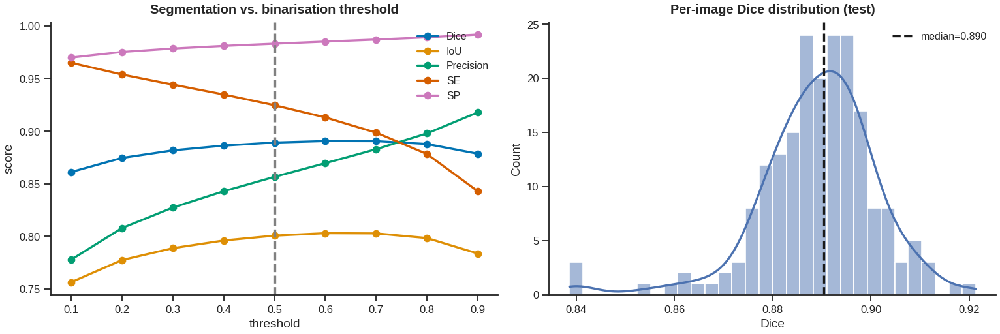

,Dice,IoU,SE,SP,Precision
threshold,,,,,
0.1,0.8612,0.7565,0.9651,0.9700,0.7779
0.2,0.8746,0.7775,0.9539,0.9753,0.8079
0.3,0.8818,0.7888,0.9443,0.9786,0.8274
0.4,0.8863,0.7961,0.9349,0.9811,0.8429
0.5,0.8892,0.8007,0.9247,0.9832,0.8566
0.6,0.8906,0.8030,0.9131,0.9852,0.8696
0.7,0.8905,0.8028,0.8986,0.9871,0.8829
0.8,0.8878,0.7984,0.8783,0.9892,0.8979
0.9,0.8786,0.7837,0.8429,0.9919,0.9179


In [58]:
# ---- Fig. B: Dice / SE / SP vs. binarisation threshold ----
thr_grid = np.round(np.arange(0.1, 0.91, 0.1), 2)
sub = test_pred_cache[: min(len(test_pred_cache), 300)]
thr_rows = []
for t in thr_grid:
    ms = [full_seg_metrics(p, g, thr=t, with_topology=False) for p, g in sub]
    thr_rows.append({"threshold": t, **{k: np.mean([m[k] for m in ms]) for k in ["Dice", "IoU", "SE", "SP", "Precision"]}})
thr_df = pd.DataFrame(thr_rows).set_index("threshold").round(4)
save_table(thr_df, "tableB_threshold_sensitivity")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
thr_df[["Dice", "IoU", "Precision", "SE", "SP"]].plot(marker="o", ax=axes[0])
axes[0].set_title("Segmentation vs. binarisation threshold"); axes[0].set_ylabel("score"); axes[0].axvline(0.5, ls="--", c="gray")
sns.histplot(seg_full["Dice"], bins=30, kde=True, ax=axes[1], color="#4C72B0")
axes[1].axvline(seg_full["Dice"].median(), ls="--", c="k", label=f"median={seg_full['Dice'].median():.3f}")
axes[1].set_title("Per-image Dice distribution (test)"); axes[1].legend()
plt.tight_layout(); save_fig(fig, "figB_seg_threshold_sensitivity"); plt.show()
thr_df

## 32. Classification — Full Metric Table with 95% CI (Table 5) & Clinical Utility (Fig. C)

Accuracy, balanced accuracy, sensitivity, specificity, PPV, NPV, F1, MCC, Cohen's κ, AUROC, AUPRC,
Brier score and ECE with bootstrap CI, evaluated at (a) the default 0.5 threshold and (b) the
Youden-optimal threshold. **The Youden threshold is chosen on the validation set**, not on test, to avoid optimistic bias.
Decision-curve analysis (net benefit) is included.

In [59]:
from sklearn.metrics import (balanced_accuracy_score, f1_score, matthews_corrcoef, cohen_kappa_score,
                             precision_score, recall_score)

@torch.no_grad()
def get_cls_reg_outputs(model, loader):
    model.eval(); P, Y, R, T = [], [], [], []
    for imgs, masks, clin, labels, thick in loader:
        _, c, r = model(imgs.to(device), clin.to(device))
        P.append(torch.sigmoid(c).cpu().numpy()); Y.append(labels.numpy()); R.append(r.cpu().numpy()); T.append(thick.numpy())
    return np.concatenate(Y), np.concatenate(P), np.concatenate(T), np.concatenate(R)

val_y, val_p, val_t, val_r = get_cls_reg_outputs(mt_model, mt_val_loader)
fv, tv, thv = roc_curve(val_y, val_p)
youden_thr = float(thv[np.argmax(tv - fv)])
print(f"Youden-optimal threshold (from VALIDATION set): {youden_thr:.3f}")

def expected_calibration_error(y, p, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1); ece = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (p > lo) & (p <= hi)
        if m.any(): ece += m.mean() * abs(y[m].mean() - p[m].mean())
    return ece

def cls_metric_dict(y, p, thr):
    y = np.asarray(y).astype(int); p = np.asarray(p)
    yhat = (p > thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
    return {"Accuracy": (tp + tn) / len(y), "Balanced acc.": balanced_accuracy_score(y, yhat),
            "Sensitivity": tp / max(tp + fn, 1), "Specificity": tn / max(tn + fp, 1),
            "PPV": tp / max(tp + fp, 1), "NPV": tn / max(tn + fn, 1),
            "F1": f1_score(y, yhat, zero_division=0), "MCC": matthews_corrcoef(y, yhat),
            "Cohen kappa": cohen_kappa_score(y, yhat),
            "AUROC": roc_auc_score(y, p), "AUPRC": average_precision_score(y, p),
            "Brier": brier_score_loss(y, p), "ECE": expected_calibration_error(y, p)}

def bootstrap_dict_ci(y, p, thr, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed); n = len(y); recs = []
    for _ in range(n_boot):
        i = rng.integers(0, n, n)
        if len(np.unique(y[i])) < 2: continue
        recs.append(cls_metric_dict(y[i], p[i], thr))
    return pd.DataFrame(recs)

rows = {}
for tag, thr in [("thr=0.5", 0.5), (f"thr=Youden({youden_thr:.2f})", youden_thr)]:
    pt = cls_metric_dict(cls_true, cls_probs, thr); bs = bootstrap_dict_ci(cls_true, cls_probs, thr)
    rows[tag] = {k: f"{pt[k]:.3f} [{bs[k].quantile(.025):.3f}, {bs[k].quantile(.975):.3f}]" for k in pt}
table5 = pd.DataFrame(rows)
save_table(table5, "table5_classification_full")
table5

Youden-optimal threshold (from VALIDATION set): 0.594


,thr=0.5,thr=Youden(0.59)
Accuracy,"0.865 [0.815, 0.915]","0.880 [0.835, 0.925]"
Balanced acc.,"0.865 [0.815, 0.911]","0.880 [0.834, 0.922]"
Sensitivity,"0.920 [0.863, 0.969]","0.840 [0.765, 0.908]"
Specificity,"0.810 [0.729, 0.888]","0.920 [0.864, 0.970]"
PPV,"0.829 [0.750, 0.902]","0.913 [0.847, 0.967]"
NPV,"0.910 [0.844, 0.964]","0.852 [0.784, 0.913]"
F1,"0.872 [0.820, 0.918]","0.875 [0.822, 0.920]"
MCC,"0.734 [0.633, 0.828]","0.762 [0.671, 0.848]"
Cohen kappa,"0.730 [0.626, 0.825]","0.760 [0.666, 0.845]"
AUROC,"0.947 [0.915, 0.972]","0.947 [0.915, 0.972]"


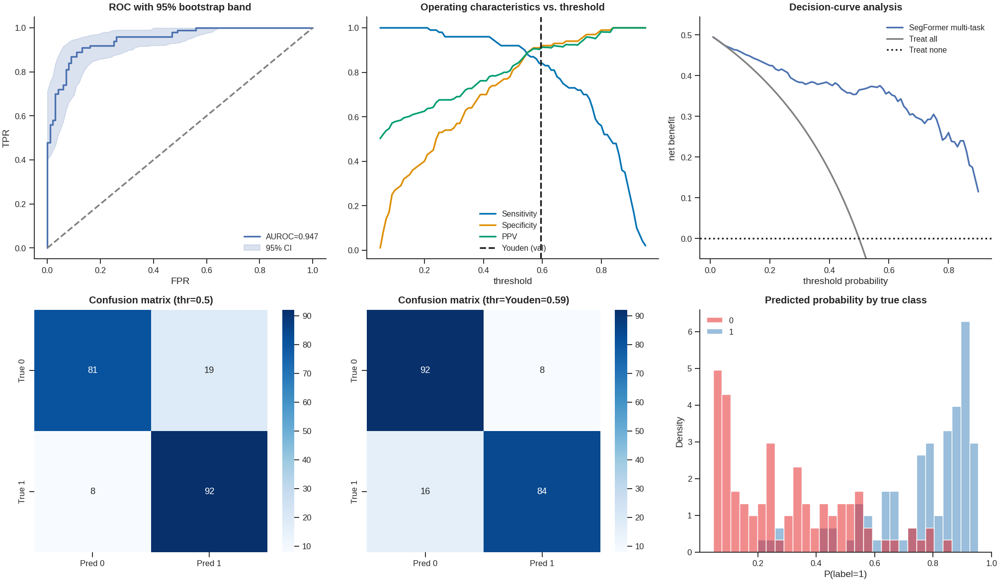

In [60]:
# ---- Fig. C: ROC with CI band, threshold curves, decision-curve analysis, confusion matrices ----
fig, axes = plt.subplots(2, 3, figsize=(17, 10))

# ROC with bootstrap band
base_fpr = np.linspace(0, 1, 101); tprs = []; rng = np.random.default_rng(42)
for _ in range(500):
    i = rng.integers(0, len(cls_true), len(cls_true))
    if len(np.unique(cls_true[i])) < 2: continue
    f_, t_, _ = roc_curve(cls_true[i], cls_probs[i]); tprs.append(np.interp(base_fpr, f_, t_))
tprs = np.array(tprs); f0, t0, _ = roc_curve(cls_true, cls_probs)
axes[0, 0].plot(f0, t0, c="#4C72B0", label=f"AUROC={roc_auc_score(cls_true, cls_probs):.3f}")
axes[0, 0].fill_between(base_fpr, np.percentile(tprs, 2.5, 0), np.percentile(tprs, 97.5, 0), color="#4C72B0", alpha=0.2, label="95% CI")
axes[0, 0].plot([0, 1], [0, 1], "--", c="gray"); axes[0, 0].set_title("ROC with 95% bootstrap band"); axes[0, 0].legend()
axes[0, 0].set_xlabel("FPR"); axes[0, 0].set_ylabel("TPR")

# sensitivity / specificity / PPV vs threshold
tg = np.linspace(0.05, 0.95, 91)
sens = [cls_metric_dict(cls_true, cls_probs, t)["Sensitivity"] for t in tg]
spec = [cls_metric_dict(cls_true, cls_probs, t)["Specificity"] for t in tg]
ppv  = [cls_metric_dict(cls_true, cls_probs, t)["PPV"] for t in tg]
axes[0, 1].plot(tg, sens, label="Sensitivity"); axes[0, 1].plot(tg, spec, label="Specificity"); axes[0, 1].plot(tg, ppv, label="PPV")
axes[0, 1].axvline(youden_thr, ls="--", c="k", label="Youden (val)"); axes[0, 1].set_title("Operating characteristics vs. threshold")
axes[0, 1].set_xlabel("threshold"); axes[0, 1].legend()

# decision curve analysis
prev = cls_true.mean(); nb_model, nb_all = [], []
dca_t = np.linspace(0.01, 0.9, 90)
for t in dca_t:
    yhat = cls_probs > t; tp = ((yhat) & (cls_true == 1)).sum(); fp = ((yhat) & (cls_true == 0)).sum(); n = len(cls_true)
    nb_model.append(tp / n - fp / n * t / (1 - t)); nb_all.append(prev - (1 - prev) * t / (1 - t))
axes[0, 2].plot(dca_t, nb_model, label="SegFormer multi-task", c="#4C72B0")
axes[0, 2].plot(dca_t, nb_all, label="Treat all", c="gray"); axes[0, 2].axhline(0, c="k", ls=":", label="Treat none")
axes[0, 2].set_ylim(-0.05, max(nb_model + nb_all) * 1.1); axes[0, 2].set_title("Decision-curve analysis"); axes[0, 2].set_xlabel("threshold probability"); axes[0, 2].set_ylabel("net benefit"); axes[0, 2].legend()

# confusion matrices at 0.5 and Youden
for ax, (tag, thr) in zip(axes[1, :2], [("0.5", 0.5), (f"Youden={youden_thr:.2f}", youden_thr)]):
    cmx = confusion_matrix(cls_true, (cls_probs > thr).astype(int))
    sns.heatmap(cmx, annot=True, fmt="d", cmap="Blues", ax=ax, xticklabels=["Pred 0", "Pred 1"], yticklabels=["True 0", "True 1"])
    ax.set_title(f"Confusion matrix (thr={tag})")

# predicted-probability distribution
sns.histplot(x=cls_probs, hue=cls_true.astype(int), bins=30, stat="density", common_norm=False, ax=axes[1, 2], palette="Set1")
axes[1, 2].set_title("Predicted probability by true class"); axes[1, 2].set_xlabel("P(label=1)")
plt.tight_layout(); save_fig(fig, "figC_classification_clinical_utility"); plt.show()

## 33. Regression — Full Agreement Metrics with 95% CI (Table 6) & Error Analysis (Fig. D)

Beyond MAE / RMSE / R²: MAPE, median absolute error, **Lin's concordance correlation coefficient (CCC)**,
ICC(3,1), Bland–Altman bias with limits of agreement, and the fraction of predictions within ±5/10/20%.

In [61]:
def lin_ccc(x, y):
    mx, my = x.mean(), y.mean(); vx, vy = x.var(), y.var(); cov = ((x - mx) * (y - my)).mean()
    return 2 * cov / (vx + vy + (mx - my) ** 2 + 1e-12)

def icc_3_1(x, y):
    d = np.stack([x, y], 1); n, k = d.shape
    gm = d.mean(); ms_r = k * ((d.mean(1) - gm) ** 2).sum() / (n - 1)
    ss_tot = ((d - gm) ** 2).sum(); ss_r = k * ((d.mean(1) - gm) ** 2).sum(); ss_c = n * ((d.mean(0) - gm) ** 2).sum()
    ms_e = (ss_tot - ss_r - ss_c) / ((n - 1) * (k - 1))
    return (ms_r - ms_e) / (ms_r + (k - 1) * ms_e + 1e-12)

def reg_metric_dict(t, p):
    err = p - t
    return {"MAE": np.abs(err).mean(), "RMSE": np.sqrt((err ** 2).mean()), "Median AE": np.median(np.abs(err)),
            "MAPE (%)": 100 * np.mean(np.abs(err) / np.maximum(np.abs(t), 1e-6)), "R2": r2_score(t, p),
            "Pearson r": np.corrcoef(t, p)[0, 1], "Lin CCC": lin_ccc(t, p), "ICC(3,1)": icc_3_1(t, p),
            "Bias (mean err)": err.mean(), "Within 10%": np.mean(np.abs(err) <= 0.10 * np.abs(t)),
            "Within 20%": np.mean(np.abs(err) <= 0.20 * np.abs(t))}

rng = np.random.default_rng(42); n = len(reg_true); recs = []
for _ in range(1000):
    i = rng.integers(0, n, n); recs.append(reg_metric_dict(reg_true[i], reg_pred[i]))
bs_reg = pd.DataFrame(recs); pt_reg = reg_metric_dict(reg_true, reg_pred)
table6 = pd.DataFrame({k: {"Estimate": pt_reg[k], "95% CI low": bs_reg[k].quantile(.025), "95% CI high": bs_reg[k].quantile(.975)}
                       for k in pt_reg}).T.round(4)
save_table(table6, "table6_regression_full")
table6

,Estimate,95% CI low,95% CI high
MAE,0.1094,0.0975,0.1214
RMSE,0.1375,0.1239,0.1512
Median AE,0.0965,0.0823,0.1076
MAPE (%),13.0248,11.4821,14.8140
R2,0.4864,0.3960,0.5508
Pearson r,0.7593,0.7140,0.8016
Lin CCC,0.6260,0.5709,0.6767
"ICC(3,1)",0.6511,0.5997,0.7041
Bias (mean err),0.0441,0.0269,0.0625
Within 10%,0.4450,0.3800,0.5150


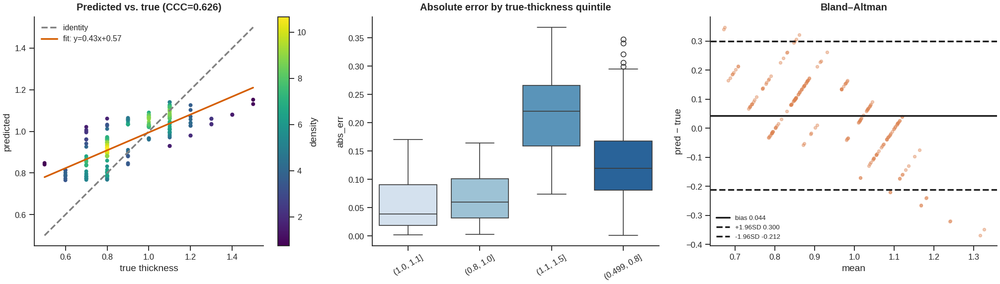

In [62]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# density scatter with regression line
from scipy.stats import gaussian_kde
xy = np.vstack([reg_true, reg_pred]); z = gaussian_kde(xy)(xy) if len(reg_true) > 5 else np.ones(len(reg_true))
sc = axes[0].scatter(reg_true, reg_pred, c=z, s=14, cmap="viridis")
lims = [min(reg_true.min(), reg_pred.min()), max(reg_true.max(), reg_pred.max())]
axes[0].plot(lims, lims, "--", c="gray", label="identity")
slope, intercept = np.polyfit(reg_true, reg_pred, 1); axes[0].plot(lims, np.polyval([slope, intercept], lims), c="r", label=f"fit: y={slope:.2f}x+{intercept:.2f}")
axes[0].set_title(f"Predicted vs. true (CCC={pt_reg['Lin CCC']:.3f})"); axes[0].set_xlabel("true thickness"); axes[0].set_ylabel("predicted"); axes[0].legend()
plt.colorbar(sc, ax=axes[0], label="density")

# error by thickness quintile
q = pd.qcut(pd.Series(reg_true), 5, duplicates="drop")
err_df = pd.DataFrame({"bin": q.astype(str), "abs_err": np.abs(reg_pred - reg_true)})
sns.boxplot(x="bin", y="abs_err", data=err_df, ax=axes[1], palette="Blues"); axes[1].tick_params(axis="x", rotation=30)
axes[1].set_title("Absolute error by true-thickness quintile"); axes[1].set_xlabel("")

# Bland-Altman with CI of limits
d = reg_pred - reg_true; m_ = (reg_pred + reg_true) / 2; md_, sd_ = d.mean(), d.std(ddof=1)
axes[2].scatter(m_, d, s=12, alpha=0.4, c="#DD8452")
for yv, ls, lab in [(md_, "-", f"bias {md_:.3f}"), (md_ + 1.96 * sd_, "--", f"+1.96SD {md_ + 1.96 * sd_:.3f}"), (md_ - 1.96 * sd_, "--", f"-1.96SD {md_ - 1.96 * sd_:.3f}")]:
    axes[2].axhline(yv, ls=ls, c="k", label=lab)
axes[2].set_title("Bland–Altman"); axes[2].set_xlabel("mean"); axes[2].set_ylabel("pred − true"); axes[2].legend(fontsize=8)
plt.tight_layout(); save_fig(fig, "figD_regression_error_analysis"); plt.show()

## 34. Ablation Study (Table 7, Fig. E)

Reviewers need to see that **each** proposed component contributes. Two ablations are run under an
identical, reduced training budget (`EXP`, below), with the *same* train/val/test CSV split:

* **7a – Architecture (cumulative):** plain U-Net → + LeakyReLU → + deformable conv → + SPP → + hybrid loss (= DCNU-Net).
* **7b – Multi-task:** seg-only, cls-only, reg-only, seg+cls, seg+reg, full multi-task, and full multi-task *without* the clinical (age/gender) input.

Significance: paired Wilcoxon on per-image Dice (full model vs. each variant), Holm-corrected.

> **Compute note.** Each run trains on a random subset (`n_train` images at `img_size`) so that all ~15 runs finish in a
> few hours on a Kaggle GPU. Absolute numbers are therefore lower than the full-budget model of Section 12 — the table
> compares *variants against each other*, and the full-budget model is shown as a separate reference row.
> Raise `epochs` / `n_train` / `seeds` for the final paper (3 seeds → mean ± SD). Set `RUN_EXPERIMENTS = False` to skip Sections 34–35 training.

In [63]:
import copy, io
from torchvision.ops import DeformConv2d

RUN_EXPERIMENTS = True          # set False to skip all re-training (Sections 34-35 training cells)
RUN_LEAVE_ONE_OUT = False       # optional extra ablation (4 more runs)
EXP = dict(img_size=256, n_train=1000, n_val=250, epochs=10, batch_size=16,
           lr=1e-4, seeds=[42], num_workers=CFG2["num_workers"])
print(EXP)

# ---------------- helper: per-image segmentation metrics on tensors (vectorised) ----------------
def seg_batch_metrics(logits, masks, thr=0.5):
    p = (torch.sigmoid(logits) > thr).float(); g = masks.float(); d = (1, 2, 3); eps = 1e-8
    tp = (p * g).sum(d); tn = ((1 - p) * (1 - g)).sum(d); fp = (p * (1 - g)).sum(d); fn = ((1 - p) * g).sum(d)
    out = {"Dice": 2 * tp / (2 * tp + fp + fn + eps), "IoU": tp / (tp + fp + fn + eps),
           "SE": tp / (tp + fn + eps), "SP": tn / (tn + fp + eps), "ACC": (tp + tn) / (tp + tn + fp + fn)}
    return {k: v.cpu().numpy() for k, v in out.items()}

def holm_correct(pvals):
    p = np.asarray(pvals, float); order = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
    return adj

# ---------------- configurable architectures (all components switchable) ----------------
def _act(kind):
    return nn.LeakyReLU(0.01, inplace=True) if kind == "leaky" else nn.ReLU(inplace=True)

class FBlock(nn.Module):
    def __init__(self, i, o, act, p=0.0, residual=False):
        super().__init__()
        self.conv1 = nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), _act(act))
        self.conv2 = nn.Sequential(nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o))
        self.act = _act(act)
        self.residual = residual
        self.skip = (nn.Conv2d(i, o, 1) if i != o else nn.Identity()) if residual else None
        self.drop = nn.Dropout2d(p) if p > 0 else nn.Identity()
    def forward(self, x):
        y = self.conv2(self.conv1(x))
        if self.residual: y = y + self.skip(x)
        return self.drop(self.act(y))

class FDeform(nn.Module):
    def __init__(self, ch, act):
        super().__init__()
        self.offset = nn.Conv2d(ch, 18, 3, padding=1)
        nn.init.constant_(self.offset.weight, 0.0); nn.init.constant_(self.offset.bias, 0.0)
        self.dc = DeformConv2d(ch, ch, 3, padding=1)
        self.bn = nn.BatchNorm2d(ch); self.act = _act(act)
    def forward(self, x):
        return self.act(self.bn(self.dc(x, self.offset(x))))

class FSPP(nn.Module):
    def __init__(self, ch, act, branch=16):
        super().__init__()
        self.b1 = nn.Conv2d(ch, branch, 1); self.b3 = nn.Conv2d(ch, branch, 3, padding=1); self.b5 = nn.Conv2d(ch, branch, 5, padding=2)
        self.fuse = nn.Sequential(nn.Conv2d(3 * branch + ch, ch, 1), nn.BatchNorm2d(ch), _act(act))
    def forward(self, x):
        return self.fuse(torch.cat([x, self.b1(x), self.b3(x), self.b5(x)], 1))

class AttGate(nn.Module):
    def __init__(self, g_ch, x_ch, inter):
        super().__init__()
        self.wg = nn.Sequential(nn.Conv2d(g_ch, inter, 1), nn.BatchNorm2d(inter))
        self.wx = nn.Sequential(nn.Conv2d(x_ch, inter, 1), nn.BatchNorm2d(inter))
        self.psi = nn.Sequential(nn.Conv2d(inter, 1, 1), nn.BatchNorm2d(1), nn.Sigmoid())
    def forward(self, g, x):
        return x * self.psi(F.relu(self.wg(g) + self.wx(x)))

class FDec(nn.Module):
    def __init__(self, in_ch, skip_ch, out_ch, act, p, attention, residual):
        super().__init__()
        self.up = nn.Upsample(scale_factor=2, mode="nearest")
        self.att = AttGate(in_ch, skip_ch, max(skip_ch // 2, 8)) if attention else None
        self.conv = FBlock(in_ch + skip_ch, out_ch, act, p, residual)
    def forward(self, x, skip):
        x = self.up(x)
        if x.shape[-2:] != skip.shape[-2:]: x = F.interpolate(x, size=skip.shape[-2:], mode="nearest")
        if self.att is not None: skip = self.att(x, skip)
        return self.conv(torch.cat([x, skip], 1))

class FlexUNet(nn.Module):
    """U-Net family with switchable components. Defaults reproduce a plain U-Net;
    act='leaky', use_dcn=True, use_spp=True reproduces DCNU-Net (seg) / DCNU-Net multi-task (multitask=True)."""
    def __init__(self, base_ch=16, act="relu", use_dcn=False, use_spp=False, attention=False,
                 residual=False, multitask=False, clinical_dim=2):
        super().__init__()
        c = [base_ch * 2 ** i for i in range(5)]
        drop = [0.1, 0.1, 0.2, 0.2]
        self.enc = nn.ModuleList(); in_c = 3
        for i in range(4):
            layers = [FBlock(in_c, c[i], act, drop[i], residual)]
            if use_dcn: layers.append(FDeform(c[i], act))
            self.enc.append(nn.Sequential(*layers)); in_c = c[i]
        self.pool = nn.MaxPool2d(2)
        self.bott = FBlock(c[3], c[4], act, 0.3, residual)
        self.spp = FSPP(c[4], act) if use_spp else nn.Identity()
        self.dec = nn.ModuleList([FDec(c[i + 1], c[i], c[i], act, drop[i], attention, residual) for i in range(3, -1, -1)])
        self.seg_out = nn.Sequential(nn.Conv2d(c[0], c[0], 1), _act(act), nn.Conv2d(c[0], 1, 1))
        self.multitask = multitask
        if multitask:
            self.gap = nn.AdaptiveAvgPool2d(1)
            self.clinical_mlp = ClinicalMLP(clinical_dim, 32)
            self.shared_fc = nn.Sequential(nn.Linear(c[4] + 32, 128), nn.LeakyReLU(0.01, inplace=True), nn.Dropout(0.3))
            self.cls_head = nn.Linear(128, 1); self.reg_head = nn.Linear(128, 1)
    def forward(self, x, clin=None):
        skips = []
        for e in self.enc:
            x = e(x); skips.append(x); x = self.pool(x)
        b = self.spp(self.bott(x)); d = b
        for dec, s in zip(self.dec, reversed(skips)): d = dec(d, s)
        seg = self.seg_out(d)
        if not self.multitask: return seg
        fused = torch.cat([self.gap(b).flatten(1), self.clinical_mlp(clin)], 1)
        h = self.shared_fc(fused)
        return seg, self.cls_head(h).squeeze(1), self.reg_head(h).squeeze(1)

# sanity: the configurable "full" model has the same parameter count as the original DCNU-Net
_chk_a = sum(p.numel() for p in FlexUNet(act="leaky", use_dcn=True, use_spp=True).parameters())
_chk_b = sum(p.numel() for p in DCNUNet(3, 1, 16).parameters())
_chk_c = sum(p.numel() for p in FlexUNet(act="leaky", use_dcn=True, use_spp=True, multitask=True).parameters())
_chk_d = sum(p.numel() for p in DCNUNetMultiTask(3, 1, 16).parameters())
print(f"FlexUNet(full)={_chk_a:,} vs DCNUNet={_chk_b:,} | FlexUNet(MT)={_chk_c:,} vs DCNUNetMultiTask={_chk_d:,}")
if not (_chk_a == _chk_b and _chk_c == _chk_d):
    print("WARNING: parameter count of FlexUNet differs from the original model - check the architecture before trusting Table 7.")

{'img_size': 256, 'n_train': 1000, 'n_val': 250, 'epochs': 10, 'batch_size': 16, 'lr': 0.0001, 'seeds': [42], 'num_workers': 2}
FlexUNet(full)=2,423,353 vs DCNUNet=2,423,353 | FlexUNet(MT)=2,461,755 vs DCNUNetMultiTask=2,461,755


In [64]:
# ---------------- generic trainer / evaluator ----------------
EXP_STORE = {}       # (name, seed) -> dict with per-image arrays
EXP_ROWS = []        # list of result dicts
BUILDERS = {}        # name -> builder (for qualitative figure)
_loader_cache = {}

def make_exp_loaders(seed):
    if seed in _loader_cache: return _loader_cache[seed]
    tr = mt_train_df.sample(n=min(EXP["n_train"], len(mt_train_df)), random_state=seed)
    va = mt_val_df.sample(n=min(EXP["n_val"], len(mt_val_df)), random_state=seed)
    mk = lambda d, aug: MultiTaskRetinalDataset(CFG2["images_dir"], CFG2["masks_dir"], d, EXP["img_size"], augment=aug)
    kw = dict(batch_size=EXP["batch_size"], num_workers=EXP["num_workers"])
    L = (DataLoader(mk(tr, True), shuffle=True, drop_last=True, **kw),
         DataLoader(mk(va, False), shuffle=False, **kw),
         DataLoader(mk(mt_test_df, False), shuffle=False, **kw))
    _loader_cache[seed] = L
    return L

_bce_cls = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
_reg_crit = nn.SmoothL1Loss()

def _fwd(model, imgs, clin, is_mt, use_clin):
    if is_mt:
        if not use_clin: clin = torch.zeros_like(clin)
        return model(imgs, clin)
    return model(imgs), None, None

def _total_loss(outs, masks, labels, thick, seg_crit, w):
    seg, cl, rg = outs; tot = 0.0
    if w[0] > 0: tot = tot + w[0] * seg_crit(seg, masks)
    if w[1] > 0: tot = tot + w[1] * _bce_cls(cl, labels)
    if w[2] > 0: tot = tot + w[2] * _reg_crit(rg, thick)
    return tot

@torch.no_grad()
def _eval_loader(model, loader, is_mt, use_clin, seg_crit, w):
    model.eval(); tot, n = 0.0, 0
    M = {k: [] for k in ["Dice", "IoU", "SE", "SP", "ACC"]}; P, Y, R, T = [], [], [], []
    for imgs, masks, clin, labels, thick in loader:
        imgs, masks, clin, labels, thick = imgs.to(device), masks.to(device), clin.to(device), labels.to(device), thick.to(device)
        outs = _fwd(model, imgs, clin, is_mt, use_clin)
        tot += _total_loss(outs, masks, labels, thick, seg_crit, w).item() * imgs.size(0); n += imgs.size(0)
        for k, v in seg_batch_metrics(outs[0], masks).items(): M[k].append(v)
        if outs[1] is not None:
            P.append(torch.sigmoid(outs[1]).cpu().numpy()); R.append(outs[2].cpu().numpy())
        Y.append(labels.cpu().numpy()); T.append(thick.cpu().numpy())
    out = {"loss": tot / max(n, 1), **{k: np.concatenate(v) for k, v in M.items()},
           "y": np.concatenate(Y).astype(int), "t": np.concatenate(T)}
    if P: out["p"] = np.concatenate(P); out["r"] = np.concatenate(R)
    return out

def run_variant(name, group, builder, seg_loss="hybrid", w=(1., 0., 0.), is_mt=False, use_clin=True, seed=42):
    key = (name, seed)
    if key in EXP_STORE:
        print(f"[skip] {name} seed={seed} already done"); return
    set_seed(seed)
    tr_loader, va_loader, te_loader = make_exp_loaders(seed)
    model = builder().to(device); BUILDERS[name] = builder
    seg_crit = HybridLoss(lam=CFG2["lam"]) if seg_loss == "hybrid" else nn.BCEWithLogitsLoss()
    opt = torch.optim.Adam(model.parameters(), lr=EXP["lr"])
    sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=3)
    best, best_state, best_ep = float("inf"), None, 0; t0 = time.time()
    for ep in range(1, EXP["epochs"] + 1):
        model.train()
        for imgs, masks, clin, labels, thick in tr_loader:
            imgs, masks, clin, labels, thick = imgs.to(device), masks.to(device), clin.to(device), labels.to(device), thick.to(device)
            opt.zero_grad()
            loss = _total_loss(_fwd(model, imgs, clin, is_mt, use_clin), masks, labels, thick, seg_crit, w)
            loss.backward(); opt.step()
        v = _eval_loader(model, va_loader, is_mt, use_clin, seg_crit, w)
        sch.step(v["loss"])
        if v["loss"] < best:
            best, best_ep = v["loss"], ep
            best_state = {k: t.detach().cpu().clone() for k, t in model.state_dict().items()}
    model.load_state_dict(best_state)
    ckpt = os.path.join(Q1_DIR, "ckpt_" + re.sub(r"[^A-Za-z0-9]+", "_", name) + f"_s{seed}.pth")
    torch.save(best_state, ckpt)
    te = _eval_loader(model, te_loader, is_mt, use_clin, seg_crit, w)
    row = {"name": name, "group": group, "seed": seed, "params_M": sum(p.numel() for p in model.parameters()) / 1e6,
           "best_epoch": best_ep, "train_min": (time.time() - t0) / 60, "ckpt": ckpt,
           **{k: float(te[k].mean()) for k in ["Dice", "IoU", "SE", "SP", "ACC"]}}
    if w[0] == 0: row.update({k: np.nan for k in ["Dice", "IoU", "SE", "SP", "ACC"]})
    if "p" in te and w[1] > 0 and len(np.unique(te["y"])) > 1:
        row["cls_AUC"] = roc_auc_score(te["y"], te["p"]); row["cls_ACC"] = accuracy_score(te["y"], (te["p"] > 0.5).astype(int))
    if "r" in te and w[2] > 0:
        row["reg_MAE"] = mean_absolute_error(te["t"], te["r"]); row["reg_R2"] = r2_score(te["t"], te["r"])
    EXP_ROWS.append(row); EXP_STORE[key] = te
    pd.DataFrame(EXP_ROWS).drop(columns=["ckpt"]).to_csv(os.path.join(Q1_DIR, "experiments_partial.csv"), index=False)
    print(f"[done] {name:38s} seed={seed} Dice={row['Dice']:.4f} params={row['params_M']:.2f}M "
          f"best_ep={best_ep} ({row['train_min']:.1f} min)")
    del model, opt; torch.cuda.empty_cache() if device.type == "cuda" else None

# ---------------- experiment definitions ----------------
FULL_KW = dict(act="leaky", use_dcn=True, use_spp=True)
ABL_ARCH = [
    ("U-Net baseline (ReLU, BCE)",     dict(act="relu"),                        "bce"),
    ("+ LeakyReLU",                    dict(act="leaky"),                       "bce"),
    ("+ Deformable conv",              dict(act="leaky", use_dcn=True),         "bce"),
    ("+ SPP bottleneck",               dict(**FULL_KW),                         "bce"),
    ("+ Hybrid loss (= DCNU-Net)",     dict(**FULL_KW),                         "hybrid"),
]
if RUN_LEAVE_ONE_OUT:
    ABL_ARCH += [
        ("DCNU-Net w/o deformable conv", dict(act="leaky", use_spp=True),       "hybrid"),
        ("DCNU-Net w/o SPP",             dict(act="leaky", use_dcn=True),       "hybrid"),
        ("DCNU-Net w/o LeakyReLU",       dict(act="relu", use_dcn=True, use_spp=True), "hybrid"),
        ("DCNU-Net w/o hybrid loss",     dict(**FULL_KW),                       "bce"),
    ]
BASELINES = [
    ("U-Net (hybrid loss)",   dict(act="relu"),                  "hybrid"),
    ("Attention U-Net",       dict(act="relu", attention=True),  "hybrid"),
    ("Residual U-Net",        dict(act="relu", residual=True),   "hybrid"),
]
ABL_MT = [   # name, task weights, use_clinical
    ("MT: seg only",                   (1., 0., 0.), True),
    ("MT: cls only",                   (0., 1., 0.), True),
    ("MT: reg only",                   (0., 0., 1.), True),
    ("MT: seg + cls",                  (1., 1., 0.), True),
    ("MT: seg + reg",                  (1., 0., 1.), True),
    ("MT: seg + cls + reg (full)",     (1., 1., 1.), True),
    ("MT: full, no clinical input",    (1., 1., 1.), False),
]
n_runs = (len(ABL_ARCH) + len(BASELINES) + len(ABL_MT)) * len(EXP["seeds"])
print(f"Planned training runs: {n_runs}")

Planned training runs: 15


In [65]:
if RUN_EXPERIMENTS:
    t_all = time.time()
    for seed in EXP["seeds"]:
        for name, kw, sl in ABL_ARCH:
            run_variant(name, "arch_ablation", lambda kw=kw: FlexUNet(**kw), seg_loss=sl, w=(1., 0., 0.), is_mt=False, seed=seed)
        for name, kw, sl in BASELINES:
            run_variant(name, "baseline", lambda kw=kw: FlexUNet(**kw), seg_loss=sl, w=(1., 0., 0.), is_mt=False, seed=seed)
        for name, w, uc in ABL_MT:
            run_variant(name, "mt_ablation", lambda: FlexUNet(**FULL_KW, multitask=True), seg_loss="hybrid", w=w, is_mt=True, use_clin=uc, seed=seed)
    print(f"All experiments finished in {(time.time() - t_all) / 60:.1f} min")
else:
    print("RUN_EXPERIMENTS=False -> skipping training of ablation / baseline variants.")
HAVE_EXP = len(EXP_ROWS) > 0

[done] U-Net baseline (ReLU, BCE)             seed=42 Dice=0.3996 params=1.97M best_ep=10 (2.7 min)
[done] + LeakyReLU                            seed=42 Dice=0.6258 params=1.97M best_ep=10 (2.6 min)
[done] + Deformable conv                      seed=42 Dice=0.5021 params=2.20M best_ep=10 (4.4 min)
[done] + SPP bottleneck                       seed=42 Dice=0.6536 params=2.42M best_ep=10 (4.4 min)
[done] + Hybrid loss (= DCNU-Net)             seed=42 Dice=0.7143 params=2.42M best_ep=10 (4.4 min)
[done] U-Net (hybrid loss)                    seed=42 Dice=0.7073 params=1.97M best_ep=10 (2.6 min)
[done] Attention U-Net                        seed=42 Dice=0.7281 params=2.00M best_ep=10 (2.7 min)
[done] Residual U-Net                         seed=42 Dice=0.7874 params=2.08M best_ep=10 (2.7 min)
[done] MT: seg only                           seed=42 Dice=0.7303 params=2.46M best_ep=10 (4.4 min)
[done] MT: cls only                           seed=42 Dice=nan params=2.46M best_ep=4 (3.6 min)
[don

In [66]:
# ---------------- Table 7a / 7b ----------------
def _fmt(df, col):
    g = df.groupby("name", sort=False)[col]
    m, s = g.mean(), g.std(ddof=1)
    return m.map(lambda v: f"{v:.4f}") if len(EXP["seeds"]) == 1 else (m.map(lambda v: f"{v:.4f}") + " ± " + s.fillna(0).map(lambda v: f"{v:.4f}"))

def dice_ci_first_seed(name):
    arr = EXP_STORE[(name, EXP["seeds"][0])]["Dice"]; m, lo, hi = bootstrap_mean_ci(arr)
    return f"[{lo:.4f}, {hi:.4f}]"

def paired_vs(ref_name, names):
    ref = EXP_STORE[(ref_name, EXP["seeds"][0])]["Dice"]; ps = []
    for nme in names:
        other = EXP_STORE[(nme, EXP["seeds"][0])]["Dice"]
        try: ps.append(stats.wilcoxon(ref, other)[1] if nme != ref_name else np.nan)
        except ValueError: ps.append(1.0)
    ok = [i for i, p in enumerate(ps) if not np.isnan(p)]
    adj = [np.nan] * len(ps)
    if ok:
        for i, a in zip(ok, holm_correct([ps[i] for i in ok])): adj[i] = a
    return adj

if HAVE_EXP:
    E = pd.DataFrame(EXP_ROWS)
    a = E[E["group"] == "arch_ablation"]; names_a = list(dict.fromkeys(a["name"]))
    t7a = pd.DataFrame({"Params (M)": a.groupby("name", sort=False)["params_M"].mean().round(2),
                        **{c: _fmt(a, c) for c in ["ACC", "SE", "SP", "Dice", "IoU"]}}).loc[names_a]
    t7a["Dice 95% CI (images)"] = [dice_ci_first_seed(n) for n in names_a]
    base_d = a[a["name"] == names_a[0]]["Dice"].mean()
    t7a["Δ Dice vs baseline"] = [a[a["name"] == n]["Dice"].mean() - base_d for n in names_a]
    t7a["Δ Dice vs baseline"] = t7a["Δ Dice vs baseline"].map(lambda v: f"{v:+.4f}")
    full_name = "+ Hybrid loss (= DCNU-Net)"
    t7a["p (Wilcoxon vs full, Holm)"] = [("—" if np.isnan(p) else f"{p:.3g}") for p in paired_vs(full_name, names_a)]
    save_table(t7a, "table7a_ablation_architecture"); display(t7a)

    m_ = E[E["group"] == "mt_ablation"]; names_m = list(dict.fromkeys(m_["name"]))
    cols = [c for c in ["Dice", "IoU", "cls_AUC", "cls_ACC", "reg_MAE", "reg_R2"] if c in m_.columns]
    t7b = pd.DataFrame({c: _fmt(m_, c) for c in cols}).loc[names_m].replace({"nan": "—", "nan ± 0.0000": "—"})
    t7b.loc["Reference: full-budget model (Sec. 12)"] = [
        f"{dice_orig.mean():.4f}", f"{iou_orig.mean():.4f}", f"{test_metrics['cls_AUC']:.4f}", f"{test_metrics['cls_ACC']:.4f}",
        f"{test_metrics['reg_MAE']:.4f}", f"{test_metrics['reg_R2']:.4f}"][: len(cols)] if cols == ["Dice", "IoU", "cls_AUC", "cls_ACC", "reg_MAE", "reg_R2"] else ["—"] * len(cols)
    save_table(t7b, "table7b_ablation_multitask"); display(t7b)
else:
    print("No experiment results available.")

,Params (M),ACC,SE,SP,Dice,IoU,Dice 95% CI (images),Δ Dice vs baseline,"p (Wilcoxon vs full, Holm)"
name,,,,,,,,,
"U-Net baseline (ReLU, BCE)",1.97,0.9257,0.2581,0.9978,0.3996,0.2529,"[0.3883, 0.4103]",+0.0000,5.74e-34
+ LeakyReLU,1.97,0.9431,0.4942,0.9914,0.6258,0.4578,"[0.6178, 0.6337]",+0.2262,5.74e-34
+ Deformable conv,2.20,0.9322,0.3548,0.9944,0.5021,0.3380,"[0.4924, 0.5114]",+0.1024,5.74e-34
+ SPP bottleneck,2.42,0.9467,0.5197,0.9928,0.6536,0.4870,"[0.6472, 0.6592]",+0.2539,3.64e-33
+ Hybrid loss (= DCNU-Net),2.42,0.9270,0.9415,0.9254,0.7143,0.5565,"[0.7099, 0.7186]",+0.3147,—


,Dice,IoU,cls_AUC,cls_ACC,reg_MAE,reg_R2
name,,,,,,
MT: seg only,0.7303,0.5757,—,—,—,—
MT: cls only,—,—,0.7833,0.7400,—,—
MT: reg only,—,—,—,—,0.1303,0.3041
MT: seg + cls,0.5903,0.4208,0.8133,0.7450,—,—
MT: seg + reg,0.6795,0.5160,—,—,0.1264,0.3167
MT: seg + cls + reg (full),0.5589,0.3897,0.8102,0.7400,0.1235,0.3083
"MT: full, no clinical input",0.6014,0.4318,0.8197,0.7350,0.1227,0.3422
Reference: full-budget model (Sec. 12),0.8892,0.8007,0.9467,0.8650,0.1094,0.4864


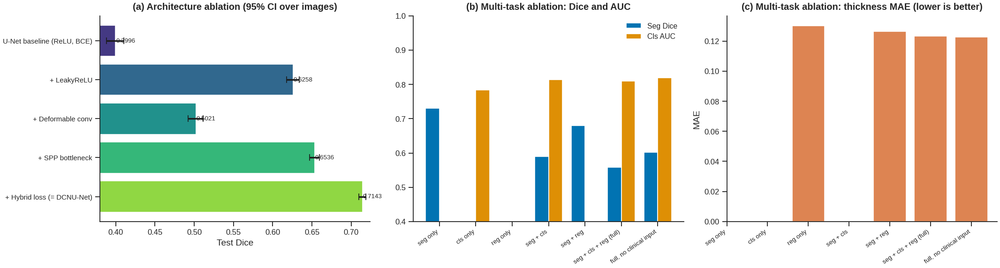

In [67]:
# ---------------- Fig. E ----------------
if HAVE_EXP:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    a = E[E["group"] == "arch_ablation"]; names_a = list(dict.fromkeys(a["name"]))
    means = [a[a["name"] == n]["Dice"].mean() for n in names_a]
    cis = [bootstrap_mean_ci(EXP_STORE[(n, EXP["seeds"][0])]["Dice"])[1:] for n in names_a]
    err = np.array([[m - c[0], c[1] - m] for m, c in zip(means, cis)]).T
    axes[0].barh(range(len(names_a)), means, xerr=err, color=sns.color_palette("viridis", len(names_a)), capsize=4)
    axes[0].set_yticks(range(len(names_a))); axes[0].set_yticklabels(names_a, fontsize=9); axes[0].invert_yaxis()
    axes[0].set_xlim(min(means) - 0.02, max(means) + 0.01); axes[0].set_xlabel("Test Dice"); axes[0].set_title("(a) Architecture ablation (95% CI over images)")
    for i, mv in enumerate(means): axes[0].text(mv + 0.0005, i, f"{mv:.4f}", va="center", fontsize=8)

    m_ = E[E["group"] == "mt_ablation"]; names_m = list(dict.fromkeys(m_["name"]))
    gm = m_.groupby("name", sort=False)[["Dice", "cls_AUC"]].mean().loc[names_m]
    x = np.arange(len(names_m)); w_ = 0.38
    axes[1].bar(x - w_ / 2, gm["Dice"], w_, label="Seg Dice"); axes[1].bar(x + w_ / 2, gm["cls_AUC"], w_, label="Cls AUC")
    axes[1].set_xticks(x); axes[1].set_xticklabels([n.replace("MT: ", "") for n in names_m], rotation=35, ha="right", fontsize=8)
    axes[1].set_ylim(0.4, 1.0); axes[1].set_title("(b) Multi-task ablation: Dice and AUC"); axes[1].legend()

    gr = m_.groupby("name", sort=False)["reg_MAE"].mean().loc[names_m]
    axes[2].bar(x, gr.values, color="#DD8452"); axes[2].set_xticks(x)
    axes[2].set_xticklabels([n.replace("MT: ", "") for n in names_m], rotation=35, ha="right", fontsize=8)
    axes[2].set_title("(c) Multi-task ablation: thickness MAE (lower is better)"); axes[2].set_ylabel("MAE")
    plt.tight_layout(); save_fig(fig, "figE_ablation"); plt.show()

## 35. Baseline Comparison (Table 8, Fig. F)

**Segmentation (8a):** U-Net, Attention U-Net, Residual U-Net — all trained with the *same* hybrid loss, data, epochs and
budget as the DCNU-Net rows, so differences are due to architecture only.

**Classification / thickness regression (8b):** non-deep and "frozen-feature" baselines, to show that the image
branch carries information beyond age/gender:

1. Clinical only (age, gender) — logistic regression / gradient boosting
2. Clinical + vessel biomarkers extracted from the *predicted* vessel mask — gradient boosting
3. Clinical + frozen DCNU-Net bottleneck embedding — logistic / ridge regression
4. **DCNU-Net multi-task (ours, end-to-end)**

Paired bootstrap tests give ΔAUC / ΔMAE vs. our model with 95% CI.

In [68]:
# ---------------- Table 8a: segmentation baselines ----------------
if HAVE_EXP:
    seg_names = ["U-Net (hybrid loss)", "Attention U-Net", "Residual U-Net", "+ Hybrid loss (= DCNU-Net)", "MT: seg + cls + reg (full)"]
    seg_names = [n for n in seg_names if n in set(E["name"])]
    sub = E[E["name"].isin(seg_names)]
    t8a = pd.DataFrame({"Params (M)": sub.groupby("name", sort=False)["params_M"].mean().round(2),
                        **{c: _fmt(sub, c) for c in ["ACC", "SE", "SP", "Dice", "IoU"]}}).loc[seg_names]
    t8a["Dice 95% CI (images)"] = [dice_ci_first_seed(n) for n in seg_names]
    ref = "MT: seg + cls + reg (full)" if "MT: seg + cls + reg (full)" in seg_names else seg_names[-1]
    t8a["p (Wilcoxon vs ref, Holm)"] = [("—" if np.isnan(p) else f"{p:.3g}") for p in paired_vs(ref, seg_names)]
    t8a = t8a.rename(index={"+ Hybrid loss (= DCNU-Net)": "DCNU-Net (seg only)", "MT: seg + cls + reg (full)": "DCNU-Net multi-task (ours)"})
    save_table(t8a, "table8a_segmentation_baselines"); display(t8a)

,Params (M),ACC,SE,SP,Dice,IoU,Dice 95% CI (images),"p (Wilcoxon vs ref, Holm)"
name,,,,,,,,
U-Net (hybrid loss),1.97,0.9264,0.9171,0.9275,0.7073,0.5482,"[0.7024, 0.7118]",5.74e-34
Attention U-Net,2.00,0.9344,0.9052,0.9376,0.7281,0.5734,"[0.7238, 0.7323]",5.74e-34
Residual U-Net,2.08,0.9548,0.8598,0.9651,0.7874,0.6499,"[0.7843, 0.7905]",5.74e-34
DCNU-Net (seg only),2.42,0.9270,0.9415,0.9254,0.7143,0.5565,"[0.7099, 0.7186]",5.74e-34
DCNU-Net multi-task (ours),2.46,0.8718,0.8282,0.8763,0.5589,0.3897,"[0.5512, 0.5663]",—


In [69]:
# ---------------- vessel biomarkers (also used in Section 38) ----------------
def vessel_biomarkers(mask):
    mask = np.asarray(mask).astype(bool); H, W = mask.shape
    keys = ["vessel_density", "skeleton_density", "mean_width_px", "width_sd_px", "branch_points", "end_points", "n_components", "largest_comp_frac"]
    if mask.sum() < 10: return {k: 0.0 for k in keys}
    sk = skeletonize(mask); dt = ndi.distance_transform_edt(mask); widths = 2 * dt[sk] if sk.any() else np.array([0.0])
    nb = ndi.convolve(sk.astype(np.uint8), np.ones((3, 3), np.uint8), mode="constant")
    lab, ncomp = ndi.label(mask); sizes = np.bincount(lab.ravel())[1:]
    return {"vessel_density": mask.mean(), "skeleton_density": sk.sum() / (H * W), "mean_width_px": widths.mean(),
            "width_sd_px": widths.std(), "branch_points": int(((nb >= 4) & sk).sum()), "end_points": int(((nb == 2) & sk).sum()),
            "n_components": int(ncomp), "largest_comp_frac": sizes.max() / mask.sum()}

@torch.no_grad()
def biomarkers_from_model(model, df, tag=""):
    model.eval(); rows = []
    for idx in range(len(df)):
        row = df.iloc[idx]; base = os.path.splitext(row["image_name"])[0]
        img = Image.open(os.path.join(CFG2["images_dir"], base + ".png")).convert("RGB").resize((CFG2["img_size"],) * 2, Image.BILINEAR)
        x = torch.from_numpy(np.array(img).astype(np.float32) / 255.0).permute(2, 0, 1).unsqueeze(0).to(device)
        clin = torch.tensor([[row["age"], row["gender"]]], dtype=torch.float32).to(device)
        pm = (torch.sigmoid(model(x, clin)[0]) > 0.5).squeeze().cpu().numpy()
        rows.append(vessel_biomarkers(pm))
    return pd.DataFrame(rows)

@torch.no_grad()
def embeddings_from_model(model, df):
    store = {}
    h = model.gap.register_forward_hook(lambda m, i, o: store.__setitem__("f", o.detach().flatten(1).cpu().numpy()))
    ds = MultiTaskRetinalDataset(CFG2["images_dir"], CFG2["masks_dir"], df, CFG2["img_size"], augment=False)
    ld = DataLoader(ds, batch_size=CFG2["batch_size"], shuffle=False, num_workers=CFG2["num_workers"]); feats = []
    model.eval()
    for imgs, masks, clin, labels, thick in ld:
        model(imgs.to(device), clin.to(device)); feats.append(store["f"])
    h.remove(); return np.concatenate(feats)

from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

N_TRAIN_FEAT = min(1500, len(mt_train_df))
fe_train_df = mt_train_df.sample(n=N_TRAIN_FEAT, random_state=42).reset_index(drop=True)
t0 = time.time()
bm_train = biomarkers_from_model(mt_model, fe_train_df)
bm_test  = biomarkers_from_model(mt_model, mt_test_df.reset_index(drop=True))
emb_train = embeddings_from_model(mt_model, fe_train_df)
emb_test  = embeddings_from_model(mt_model, mt_test_df.reset_index(drop=True))
print(f"Feature extraction done in {(time.time() - t0) / 60:.1f} min | train feats: {bm_train.shape}, {emb_train.shape}")

Feature extraction done in 2.9 min | train feats: (1500, 8), (1500, 256)


In [70]:
# ---------------- Table 8b: classification & regression baselines ----------------
clin_tr = fe_train_df[["age", "gender"]].values; clin_te = mt_test_df[["age", "gender"]].values
y_tr = fe_train_df["label"].values.astype(int); t_tr = fe_train_df["thickness"].values
y_te = mt_test_df["label"].values.astype(int);   t_te = mt_test_df["thickness"].values

FS = {"Clinical only (age, gender)":            (clin_tr, clin_te),
      "Clinical + vessel biomarkers":            (np.hstack([clin_tr, bm_train.values]), np.hstack([clin_te, bm_test.values])),
      "Clinical + frozen SegFormer embedding":    (np.hstack([clin_tr, emb_train]), np.hstack([clin_te, emb_test]))}

base_preds = {}   # name -> (prob, reg_pred)
for fs_name, (Xtr, Xte) in FS.items():
    for mdl_tag, clf, reg in [("LR/Ridge", make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000, class_weight="balanced")),
                                           make_pipeline(StandardScaler(), Ridge(alpha=10.0))),
                              ("GBM", HistGradientBoostingClassifier(max_iter=150, learning_rate=0.05, random_state=42),
                                      HistGradientBoostingRegressor(max_iter=150, learning_rate=0.05, random_state=42))]:
        if fs_name.endswith("embedding") and mdl_tag == "GBM": continue          # 258-d: keep linear only
        clf.fit(Xtr, y_tr); reg.fit(Xtr, t_tr)
        base_preds[f"{fs_name} [{mdl_tag}]"] = (clf.predict_proba(Xte)[:, 1], reg.predict(Xte))
base_preds["SegFormer multi-task (ours, end-to-end)"] = (cls_probs, reg_pred)

def paired_boot_delta(y, p_ref, p_oth, metric, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed); n = len(y); d = []
    for _ in range(n_boot):
        i = rng.integers(0, n, n)
        if metric is roc_auc_score and len(np.unique(y[i])) < 2: continue
        d.append(metric(y[i], p_ref[i]) - metric(y[i], p_oth[i]))
    d = np.array(d); pval = 2 * min((d <= 0).mean(), (d >= 0).mean())
    return d.mean(), np.percentile(d, 2.5), np.percentile(d, 97.5), min(1.0, pval)

ours = "SegFormer multi-task (ours, end-to-end)"; rows = []
for nme, (pp, rp) in base_preds.items():
    auc_m, auc_lo, auc_hi = bootstrap_metric_ci(y_te, pp, roc_auc_score)
    mae_m, mae_lo, mae_hi = bootstrap_metric_ci(t_te, rp, mean_absolute_error)
    r = {"Method": nme, "AUC [95% CI]": f"{auc_m:.3f} [{auc_lo:.3f}, {auc_hi:.3f}]",
         "Acc@0.5": f"{accuracy_score(y_te, (pp > 0.5).astype(int)):.3f}",
         "MAE [95% CI]": f"{mae_m:.3f} [{mae_lo:.3f}, {mae_hi:.3f}]", "R²": f"{r2_score(t_te, rp):.3f}"}
    if nme != ours:
        d, lo, hi, p = paired_boot_delta(y_te, base_preds[ours][0], pp, roc_auc_score)
        r["ΔAUC (ours − this) [95% CI]"] = f"{d:+.3f} [{lo:+.3f}, {hi:+.3f}]"; r["p (ΔAUC)"] = f"{p:.3g}"
        d2, lo2, hi2, p2 = paired_boot_delta(t_te, base_preds[ours][1], rp, mean_absolute_error)
        r["ΔMAE (ours − this) [95% CI]"] = f"{d2:+.3f} [{lo2:+.3f}, {hi2:+.3f}]"; r["p (ΔMAE)"] = f"{p2:.3g}"
    rows.append(r)
t8b = pd.DataFrame(rows).set_index("Method").fillna("—")
save_table(t8b, "table8b_cls_reg_baselines"); t8b

,AUC [95% CI],Acc@0.5,MAE [95% CI],R²,ΔAUC (ours − this) [95% CI],p (ΔAUC),ΔMAE (ours − this) [95% CI],p (ΔMAE)
Method,,,,,,,,
"Clinical only (age, gender) [LR/Ridge]","0.945 [0.911, 0.973]",0.840,"0.115 [0.103, 0.127]",0.454,"+0.002 [-0.005, +0.009]",0.606,"-0.005 [-0.010, -0.001]",0.032
"Clinical only (age, gender) [GBM]","0.920 [0.880, 0.953]",0.740,"0.120 [0.108, 0.133]",0.393,"+0.027 [+0.008, +0.049]",0.008,"-0.011 [-0.017, -0.005]",0
Clinical + vessel biomarkers [LR/Ridge],"0.940 [0.906, 0.967]",0.840,"0.116 [0.104, 0.128]",0.449,"+0.007 [-0.002, +0.017]",0.128,"-0.007 [-0.012, -0.002]",0.008
Clinical + vessel biomarkers [GBM],"0.895 [0.851, 0.937]",0.725,"0.122 [0.109, 0.135]",0.361,"+0.052 [+0.018, +0.089]",0.004,"-0.013 [-0.020, -0.006]",0
Clinical + frozen SegFormer embedding [LR/Ridge],"0.912 [0.874, 0.946]",0.770,"0.116 [0.105, 0.129]",0.434,"+0.035 [+0.009, +0.061]",0.006,"-0.007 [-0.013, -0.001]",0.022
"SegFormer multi-task (ours, end-to-end)","0.947 [0.915, 0.972]",0.865,"0.109 [0.097, 0.121]",0.486,—,—,—,—


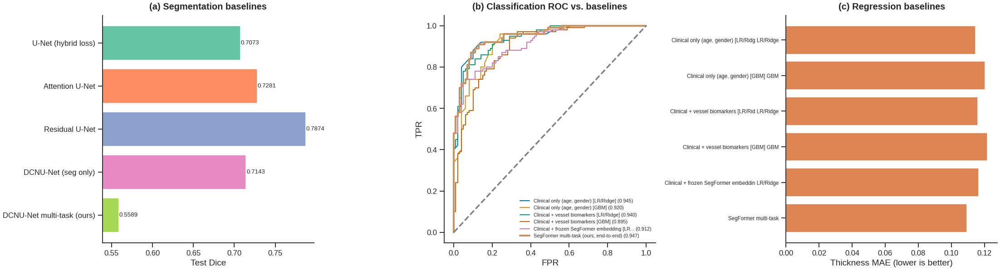

In [71]:
# ---------------- Fig. F ----------------
n_panels = 3 if HAVE_EXP else 2
fig, axes = plt.subplots(1, n_panels, figsize=(6.2 * n_panels, 5.2)); k = 0
if HAVE_EXP:
    names_f = list(t8a.index); ds_ = [E[E["name"] == {"DCNU-Net (seg only)": "+ Hybrid loss (= DCNU-Net)", "DCNU-Net multi-task (ours)": "MT: seg + cls + reg (full)"}.get(n, n)]["Dice"].mean() for n in names_f]
    axes[k].barh(names_f, ds_, color=sns.color_palette("Set2", len(names_f))); axes[k].invert_yaxis()
    axes[k].set_xlim(min(ds_) - 0.02, max(ds_) + 0.01); axes[k].set_xlabel("Test Dice"); axes[k].set_title("(a) Segmentation baselines")
    for i, v in enumerate(ds_): axes[k].text(v + 0.0005, i, f"{v:.4f}", va="center", fontsize=8)
    k += 1
for nme, (pp, rp) in base_preds.items():
    f_, t_, _ = roc_curve(y_te, pp)
    lbl = nme if len(nme) <= 44 else nme[:41] + "..."
    axes[k].plot(f_, t_, lw=2.5 if nme == ours else 1.2, label=f"{lbl} ({roc_auc_score(y_te, pp):.3f})")
axes[k].plot([0, 1], [0, 1], "--", c="gray"); axes[k].set_title("(b) Classification ROC vs. baselines"); axes[k].legend(fontsize=6.5, loc="lower right")
axes[k].set_xlabel("FPR"); axes[k].set_ylabel("TPR"); k += 1
maes = {n.split(" (ours")[0][:36] + (" " + n.split(" [")[1].rstrip("]") if " [" in n else ""): mean_absolute_error(t_te, rp) for n, (pp, rp) in base_preds.items()}
axes[k].barh(list(maes.keys()), list(maes.values()), color="#DD8452"); axes[k].invert_yaxis(); axes[k].tick_params(axis="y", labelsize=7)
axes[k].set_xlabel("Thickness MAE (lower is better)"); axes[k].set_title("(c) Regression baselines")
plt.tight_layout(); save_fig(fig, "figF_baseline_comparison"); plt.show()

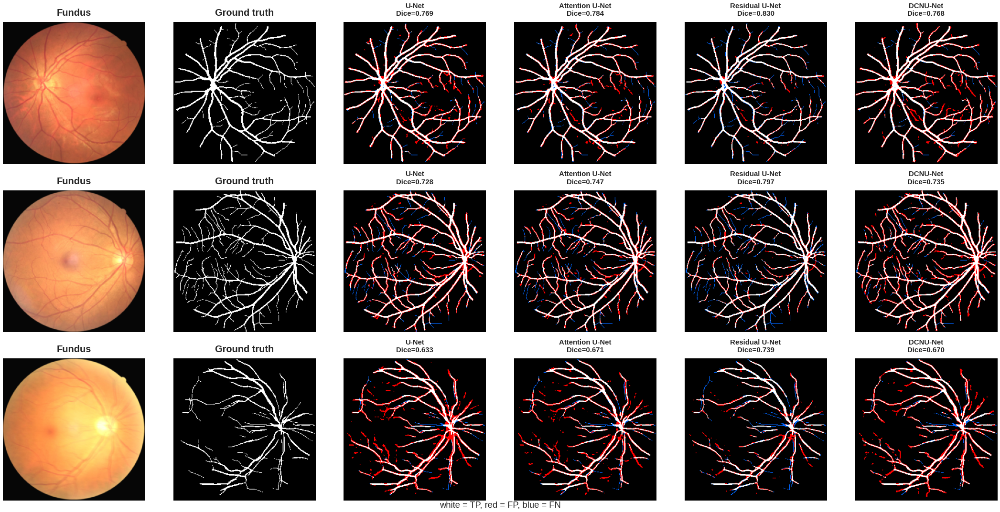

In [72]:
# ---------------- Fig. F2: qualitative model comparison ----------------
if HAVE_EXP:
    cmp_names = ["U-Net (hybrid loss)", "Attention U-Net", "Residual U-Net", "+ Hybrid loss (= DCNU-Net)"]
    cmp_names = [n for n in cmp_names if (n, EXP["seeds"][0]) in EXP_STORE]
    S_ = EXP["img_size"]; idxs = [int(np.argsort(dice_orig)[i]) for i in [len(dice_orig) - 1, len(dice_orig) // 2, 0]]
    fig, axes = plt.subplots(len(idxs), 2 + len(cmp_names), figsize=(3 * (2 + len(cmp_names)), 3 * len(idxs)))
    loaded = {}
    for n in cmp_names:
        r_ = [r for r in EXP_ROWS if r["name"] == n and r["seed"] == EXP["seeds"][0]][0]
        mdl = BUILDERS[n]().to(device); mdl.load_state_dict(torch.load(r_["ckpt"], map_location=device)); mdl.eval(); loaded[n] = mdl
    for ri, idx in enumerate(idxs):
        row = mt_test_df.iloc[idx]; base = os.path.splitext(row["image_name"])[0]
        img = Image.open(os.path.join(CFG2["images_dir"], base + ".png")).convert("RGB").resize((S_, S_), Image.BILINEAR)
        gt = (np.array(Image.open(os.path.join(CFG2["masks_dir"], base + "_mask.png")).convert("L").resize((S_, S_), Image.NEAREST)) > 127)
        x = torch.from_numpy(np.array(img).astype(np.float32) / 255.0).permute(2, 0, 1).unsqueeze(0).to(device)
        axes[ri, 0].imshow(img); axes[ri, 0].set_title("Fundus"); axes[ri, 1].imshow(gt, cmap="gray"); axes[ri, 1].set_title("Ground truth")
        for ci, n in enumerate(cmp_names):
            with torch.no_grad(): pm = (torch.sigmoid(loaded[n](x)) > 0.5).squeeze().cpu().numpy()
            err = np.zeros((S_, S_, 3)); err[pm & gt] = [1, 1, 1]; err[pm & ~gt] = [1, 0, 0]; err[~pm & gt] = [0, 0.4, 1]
            dsc = 2 * (pm & gt).sum() / (pm.sum() + gt.sum() + 1e-8)
            axes[ri, 2 + ci].imshow(err); axes[ri, 2 + ci].set_title(f"{n.replace(' (hybrid loss)', '').replace('+ Hybrid loss (= DCNU-Net)', 'DCNU-Net')}\nDice={dsc:.3f}", fontsize=9)
        for a_ in axes[ri]: a_.axis("off")
    fig.text(0.5, 0.005, "white = TP, red = FP, blue = FN", ha="center"); plt.tight_layout()
    save_fig(fig, "figF2_qualitative_model_comparison"); plt.show()
    del loaded

## 36. Robustness to Image Degradation (Table 9, Fig. G)

Fundus images in the clinic differ in noise, focus, illumination and compression. The trained multi-task model
(Section 12 checkpoint) is evaluated on a fixed 300-image random test subset under graded synthetic degradations;
segmentation Dice, classification AUC and thickness MAE are reported for every severity.

In [73]:
rob_df = mt_test_df.sample(n=min(300, len(mt_test_df)), random_state=0).reset_index(drop=True)
S_ = CFG2["img_size"]
R_imgs = np.stack([np.array(Image.open(os.path.join(CFG2["images_dir"], os.path.splitext(n)[0] + ".png")).convert("RGB").resize((S_, S_), Image.BILINEAR)) for n in rob_df["image_name"]])
R_gts  = np.stack([(np.array(Image.open(os.path.join(CFG2["masks_dir"], os.path.splitext(n)[0] + "_mask.png")).convert("L").resize((S_, S_), Image.NEAREST)) > 127) for n in rob_df["image_name"]])
R_clin = torch.tensor(rob_df[["age", "gender"]].values, dtype=torch.float32)
R_y, R_t = rob_df["label"].values.astype(int), rob_df["thickness"].values
rng_p = np.random.default_rng(0)

def p_noise(s):  return lambda im: np.clip(im + rng_p.normal(0, s, im.shape).astype(np.float32), 0, 1)
def p_blur(s):   return lambda im: ndi.gaussian_filter(im, sigma=(s, s, 0))
def p_bright(f): return lambda im: np.clip(im * f, 0, 1)
def p_contrast(f): return lambda im: np.clip((im - im.mean()) * f + im.mean(), 0, 1)
def p_jpeg(q):
    def f(im):
        buf = io.BytesIO(); Image.fromarray((im * 255).astype(np.uint8)).save(buf, format="JPEG", quality=q); buf.seek(0)
        return np.array(Image.open(buf)).astype(np.float32) / 255.0
    return f

FAMILIES = {"Gaussian noise (σ)":  [(0.02, p_noise(0.02)), (0.05, p_noise(0.05)), (0.10, p_noise(0.10)), (0.20, p_noise(0.20))],
            "Gaussian blur (σ, px)": [(1, p_blur(1)), (2, p_blur(2)), (3, p_blur(3)), (5, p_blur(5))],
            "Brightness (×)":      [(0.6, p_bright(0.6)), (0.8, p_bright(0.8)), (1.2, p_bright(1.2)), (1.5, p_bright(1.5))],
            "Contrast (×)":        [(0.5, p_contrast(0.5)), (0.75, p_contrast(0.75)), (1.25, p_contrast(1.25)), (1.5, p_contrast(1.5))],
            "JPEG quality":        [(70, p_jpeg(70)), (50, p_jpeg(50)), (30, p_jpeg(30)), (10, p_jpeg(10))]}

@torch.no_grad()
def eval_perturbed(fn, bs=16):
    mt_model.eval(); dices, P, Rg = [], [], []
    for s in range(0, len(R_imgs), bs):
        x = np.stack([(fn(im.astype(np.float32) / 255.0) if fn else im.astype(np.float32) / 255.0) for im in R_imgs[s:s + bs]]).astype(np.float32)
        xt = torch.from_numpy(x).permute(0, 3, 1, 2).to(device)
        seg, cl, rg = mt_model(xt, R_clin[s:s + bs].to(device))
        dices.append(seg_batch_metrics(seg, torch.from_numpy(R_gts[s:s + bs]).float().unsqueeze(1).to(device))["Dice"])
        P.append(torch.sigmoid(cl).cpu().numpy()); Rg.append(rg.cpu().numpy())
    P, Rg = np.concatenate(P), np.concatenate(Rg)
    return {"Dice": np.concatenate(dices).mean(), "cls_AUC": roc_auc_score(R_y, P), "reg_MAE": mean_absolute_error(R_t, Rg)}

clean = eval_perturbed(None); rob_rows = [{"Family": "Clean", "Level": "—", **clean}]
for fam, levels in FAMILIES.items():
    for lvl, fn in levels:
        rob_rows.append({"Family": fam, "Level": lvl, **eval_perturbed(fn)})
table9 = pd.DataFrame(rob_rows); table9["Δ Dice vs clean"] = table9["Dice"] - clean["Dice"]
table9["Δ AUC vs clean"] = table9["cls_AUC"] - clean["cls_AUC"]; table9["Δ MAE vs clean"] = table9["reg_MAE"] - clean["reg_MAE"]
table9 = table9.round(4); save_table(table9, "table9_robustness", index=False); table9

,Family,Level,Dice,cls_AUC,reg_MAE,Δ Dice vs clean,Δ AUC vs clean,Δ MAE vs clean
0,Clean,—,0.8892,0.9467,0.1094,0.0000,0.0000,0.0000
1,Gaussian noise (σ),0.02,0.8732,0.9464,0.1081,-0.0160,-0.0003,-0.0013
2,Gaussian noise (σ),0.05,0.8117,0.9475,0.1067,-0.0775,0.0008,-0.0026
3,Gaussian noise (σ),0.1,0.6693,0.9470,0.1029,-0.2199,0.0003,-0.0065
4,Gaussian noise (σ),0.2,0.3776,0.9463,0.1022,-0.5116,-0.0004,-0.0072
5,"Gaussian blur (σ, px)",1,0.8751,0.9472,0.1092,-0.0141,0.0005,-0.0001
6,"Gaussian blur (σ, px)",2,0.7851,0.9475,0.1063,-0.1041,0.0008,-0.0031
7,"Gaussian blur (σ, px)",3,0.6068,0.9489,0.1065,-0.2824,0.0022,-0.0029
8,"Gaussian blur (σ, px)",5,0.0998,0.9491,0.1104,-0.7893,0.0024,0.0010
9,Brightness (×),0.6,0.8846,0.9428,0.1146,-0.0046,-0.0039,0.0052


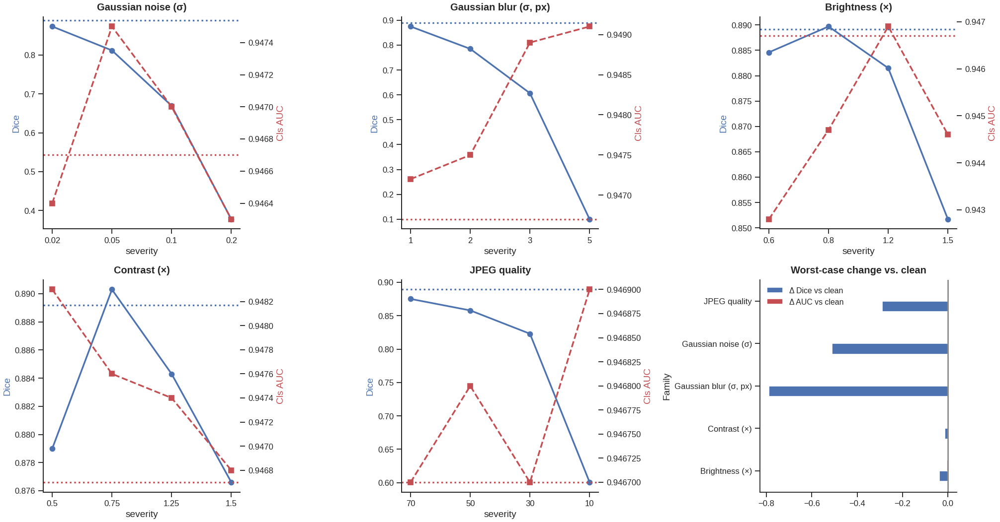

In [74]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9)); axes = axes.ravel()
for ax, fam in zip(axes[:5], FAMILIES):
    d = table9[table9["Family"] == fam]; xs = [str(v) for v in d["Level"]]
    ax.plot(xs, d["Dice"], "o-", c="#4C72B0", label="Dice"); ax.axhline(clean["Dice"], ls=":", c="#4C72B0")
    ax.set_ylabel("Dice", color="#4C72B0"); ax.set_title(fam); ax.set_xlabel("severity")
    ax2 = ax.twinx(); ax2.plot(xs, d["cls_AUC"], "s--", c="#C44E52"); ax2.axhline(clean["cls_AUC"], ls=":", c="#C44E52"); ax2.set_ylabel("Cls AUC", color="#C44E52")
worst = table9[table9["Family"] != "Clean"].groupby("Family")[["Δ Dice vs clean", "Δ AUC vs clean"]].min()
worst.plot(kind="barh", ax=axes[5], color=["#4C72B0", "#C44E52"]); axes[5].set_title("Worst-case change vs. clean"); axes[5].axvline(0, c="k", lw=0.8)
plt.tight_layout(); save_fig(fig, "figG_robustness"); plt.show()

## 37. Subgroup Analysis (Table 10, Fig. H)

Performance stratified by gender, age tertile and class label (fairness / generalisability evidence).
Heterogeneity across subgroups is tested (Kruskal–Wallis on per-image Dice; bootstrap difference for AUC).

In [75]:
age_tert = pd.qcut(mt_test_df["age"], 3, duplicates="drop").astype(str).values
groups = {}
for g in np.unique(mt_test_df["gender"].values): groups[f"Gender = {g}"] = (mt_test_df["gender"].values == g)
for a_ in np.unique(age_tert): groups[f"Age {a_}"] = (age_tert == a_)
for l_ in [0, 1]: groups[f"Label = {l_}"] = (cls_true.astype(int) == l_)
groups["All test"] = np.ones(len(mt_test_df), bool)

def boot_auc_ci(y, p, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed); y = np.asarray(y).astype(int); p = np.asarray(p); n = len(y); v = []
    for _ in range(n_boot):
        i = rng.integers(0, n, n)
        if len(np.unique(y[i])) == 2: v.append(roc_auc_score(y[i], p[i]))
    return roc_auc_score(y, p), np.percentile(v, 2.5), np.percentile(v, 97.5)

rows = []
for gname, m in groups.items():
    r = {"Subgroup": gname, "n": int(m.sum())}
    dm, dlo, dhi = bootstrap_mean_ci(seg_full["Dice"].values[m]); r["Dice [95% CI]"] = f"{dm:.4f} [{dlo:.4f}, {dhi:.4f}]"
    yy, pp = cls_true[m].astype(int), cls_probs[m]
    if len(np.unique(yy)) > 1:
        am, alo, ahi = boot_auc_ci(yy, pp); r["AUC [95% CI]"] = f"{am:.3f} [{alo:.3f}, {ahi:.3f}]"
    else: r["AUC [95% CI]"] = "—"
    r["Cls ACC"] = f"{accuracy_score(yy, (pp > 0.5).astype(int)):.3f}"
    r["Thickness MAE"] = f"{mean_absolute_error(reg_true[m], reg_pred[m]):.3f}"
    r["Thickness R²"] = f"{r2_score(reg_true[m], reg_pred[m]):.3f}" if m.sum() > 2 else "—"
    rows.append(r)
table10 = pd.DataFrame(rows).set_index("Subgroup")
save_table(table10, "table10_subgroups")

het = []
g_masks = [groups[k] for k in groups if k.startswith("Gender")]
if len(g_masks) >= 2: het.append(("Dice across gender (Kruskal-Wallis)", stats.kruskal(*[seg_full["Dice"].values[m] for m in g_masks])[1]))
a_masks = [groups[k] for k in groups if k.startswith("Age")]
if len(a_masks) >= 2: het.append(("Dice across age tertiles (Kruskal-Wallis)", stats.kruskal(*[seg_full["Dice"].values[m] for m in a_masks])[1]))
for t_, p_ in het: print(f"{t_}: p = {p_:.4g}")
table10

Dice across gender (Kruskal-Wallis): p = 0.8953
Dice across age tertiles (Kruskal-Wallis): p = 0.07406


,n,Dice [95% CI],AUC [95% CI],Cls ACC,Thickness MAE,Thickness R²
Subgroup,,,,,,
Gender = 0,74,"0.8888 [0.8855, 0.8919]","0.897 [0.810, 0.960]",0.892,0.117,0.363
Gender = 1,126,"0.8894 [0.8875, 0.8912]","0.958 [0.924, 0.985]",0.849,0.105,0.546
"Age (0.0127, 0.37]",68,"0.8912 [0.8881, 0.8940]","0.785 [0.674, 0.892]",0.941,0.095,-0.864
"Age (0.37, 0.562]",68,"0.8900 [0.8876, 0.8924]","0.850 [0.748, 0.931]",0.721,0.133,-0.002
"Age (0.562, 0.822]",64,"0.8861 [0.8827, 0.8891]","0.817 [0.680, 0.952]",0.938,0.099,0.109
Label = 0,100,"0.8913 [0.8889, 0.8937]",—,0.810,0.128,-3.329
Label = 1,100,"0.8871 [0.8846, 0.8892]",—,0.920,0.091,0.060
All test,200,"0.8892 [0.8875, 0.8908]","0.947 [0.915, 0.972]",0.865,0.109,0.486


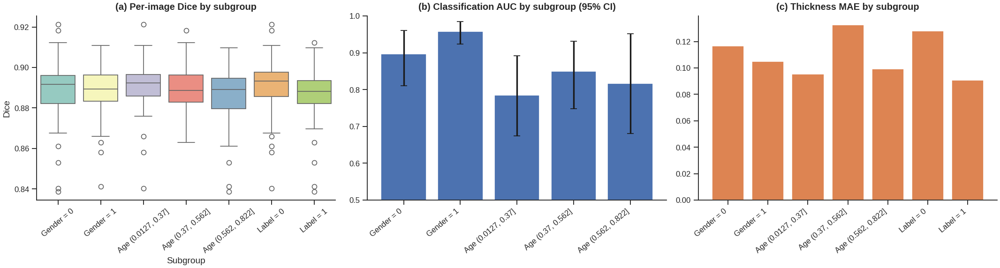

In [76]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plot_groups = [k for k in groups if k != "All test"]
box_df = pd.concat([pd.DataFrame({"Subgroup": k, "Dice": seg_full["Dice"].values[groups[k]]}) for k in plot_groups])
sns.boxplot(x="Subgroup", y="Dice", data=box_df, ax=axes[0], palette="Set3"); axes[0].tick_params(axis="x", rotation=40); axes[0].set_title("(a) Per-image Dice by subgroup")
auc_pts, auc_err, auc_lbl = [], [[], []], []
for k in plot_groups:
    m = groups[k]; yy = cls_true[m].astype(int)
    if len(np.unique(yy)) < 2: continue
    am, alo, ahi = boot_auc_ci(yy, cls_probs[m]); auc_pts.append(am); auc_err[0].append(am - alo); auc_err[1].append(ahi - am); auc_lbl.append(k)
axes[1].bar(range(len(auc_pts)), auc_pts, yerr=auc_err, capsize=4, color="#4C72B0"); axes[1].set_xticks(range(len(auc_pts))); axes[1].set_xticklabels(auc_lbl, rotation=40, ha="right")
axes[1].set_ylim(0.5, 1.0); axes[1].set_title("(b) Classification AUC by subgroup (95% CI)")
maes = [mean_absolute_error(reg_true[groups[k]], reg_pred[groups[k]]) for k in plot_groups]
axes[2].bar(range(len(plot_groups)), maes, color="#DD8452"); axes[2].set_xticks(range(len(plot_groups))); axes[2].set_xticklabels(plot_groups, rotation=40, ha="right")
axes[2].set_title("(c) Thickness MAE by subgroup")
plt.tight_layout(); save_fig(fig, "figH_subgroups"); plt.show()

## 38. Segmentation-Derived Vessel Biomarkers vs. Clinical Outcome (Table 11, Fig. I)

Clinical-relevance evidence: (i) are biomarkers measured on the **predicted** mask (vessel density, skeleton density,
mean calibre, branch points, ...) in agreement with those from the **ground-truth** mask, and (ii) do they associate with
thickness / age / label? Associations use Spearman (continuous) and Mann–Whitney with rank-biserial effect size (label), Holm-corrected.

In [77]:
bm_pred = pd.DataFrame([vessel_biomarkers(p > 0.5) for p, g in test_pred_cache])
bm_gt   = pd.DataFrame([vessel_biomarkers(g) for p, g in test_pred_cache])

rows = []
for c in bm_pred.columns:
    a_, b_ = bm_gt[c].values.astype(float), bm_pred[c].values.astype(float)
    rows.append({"Biomarker": c, "Pearson r": np.corrcoef(a_, b_)[0, 1] if a_.std() > 0 and b_.std() > 0 else np.nan,
                 "Lin CCC": lin_ccc(a_, b_), "ICC(3,1)": icc_3_1(a_, b_), "Bias (pred−GT)": (b_ - a_).mean(),
                 "MAPE (%)": 100 * np.mean(np.abs(b_ - a_) / np.maximum(np.abs(a_), 1e-6))})
table11a = pd.DataFrame(rows).set_index("Biomarker").round(4); save_table(table11a, "table11a_biomarker_agreement")
display(table11a)

assoc = []
for c in bm_pred.columns:
    v = bm_pred[c].values.astype(float)
    rt, pt_ = stats.spearmanr(v, mt_test_df["thickness"].values); ra, pa_ = stats.spearmanr(v, mt_test_df["age"].values)
    x1, x0 = v[cls_true == 1], v[cls_true == 0]; u, pu = stats.mannwhitneyu(x1, x0, alternative="two-sided")
    assoc.append({"Biomarker": c, "ρ vs thickness": rt, "p (thickness)": pt_, "ρ vs age": ra, "p (age)": pa_,
                  "rank-biserial (label 1 vs 0)": 2 * u / (len(x1) * len(x0)) - 1, "p (label)": pu})
table11b = pd.DataFrame(assoc).set_index("Biomarker")
for pc in ["p (thickness)", "p (age)", "p (label)"]: table11b[pc + " Holm"] = holm_correct(table11b[pc].values)
table11b = table11b.round(4); save_table(table11b, "table11b_biomarker_associations"); table11b

,Pearson r,Lin CCC,"ICC(3,1)",Bias (pred−GT),MAPE (%)
Biomarker,,,,,
vessel_density,0.9780,0.8411,0.9759,0.0078,8.0375
skeleton_density,0.9869,0.9592,0.9858,-0.0009,3.4605
mean_width_px,0.9226,0.3283,0.9209,0.3854,10.0741
width_sd_px,0.8695,0.8104,0.8642,0.0625,4.8150
branch_points,0.9326,0.8258,0.9241,-43.7050,11.4429
end_points,0.8165,0.0965,0.6293,104.8700,111.8361
n_components,0.0547,0.0008,0.0156,88.0750,1640.4126
largest_comp_frac,0.6283,0.5247,0.6283,-0.0480,6.2328


,ρ vs thickness,p (thickness),ρ vs age,p (age),rank-biserial (label 1 vs 0),p (label),p (thickness) Holm,p (age) Holm,p (label) Holm
Biomarker,,,,,,,,,
vessel_density,-0.2813,0.0001,-0.3844,0.0000,-0.3216,0.0001,0.0004,0.0000,0.0006
skeleton_density,-0.1154,0.1036,-0.2874,0.0000,-0.1559,0.0570,0.5182,0.0002,0.2849
mean_width_px,-0.3726,0.0000,-0.2557,0.0003,-0.4128,0.0000,0.0000,0.0013,0.0000
width_sd_px,-0.0961,0.1757,0.0533,0.4537,-0.1098,0.1802,0.7026,0.9074,0.7207
branch_points,-0.1564,0.0270,-0.2964,0.0000,-0.1641,0.0451,0.1620,0.0001,0.2706
end_points,-0.0208,0.7704,-0.2124,0.0025,-0.0434,0.5968,0.7814,0.0101,1.0000
n_components,0.0718,0.3122,-0.1046,0.1405,0.0602,0.4627,0.7814,0.4215,1.0000
largest_comp_frac,-0.0799,0.2605,-0.0036,0.9597,-0.0302,0.7131,0.7814,0.9597,1.0000


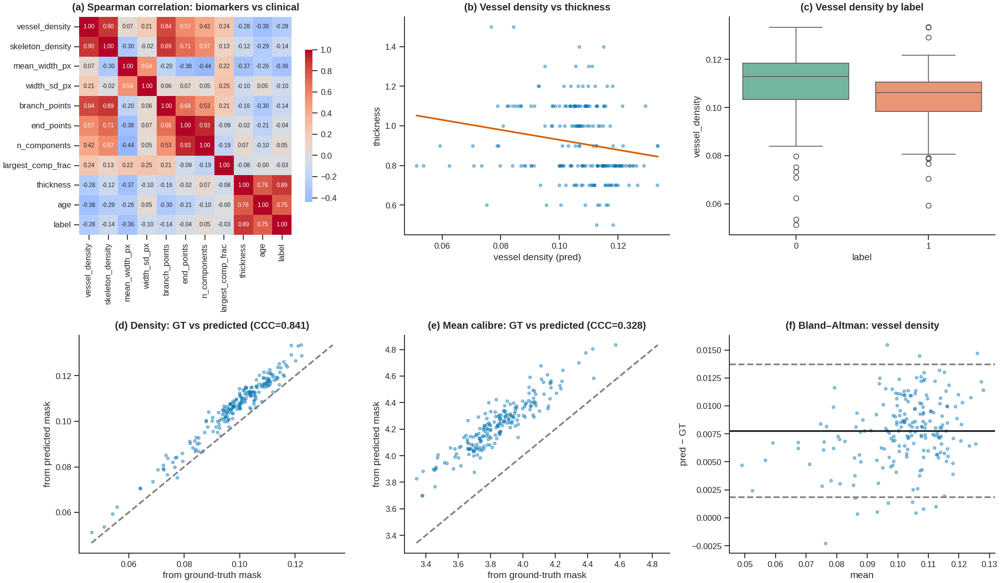

In [78]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
corr_df = bm_pred.copy(); corr_df["thickness"] = mt_test_df["thickness"].values; corr_df["age"] = mt_test_df["age"].values; corr_df["label"] = cls_true
sns.heatmap(corr_df.corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0, 0], annot_kws={"size": 7}, cbar_kws={"shrink": .7})
axes[0, 0].set_title("(a) Spearman correlation: biomarkers vs clinical")
axes[0, 1].scatter(bm_pred["vessel_density"], mt_test_df["thickness"], s=12, alpha=0.4)
sl, ic = np.polyfit(bm_pred["vessel_density"], mt_test_df["thickness"], 1); xs_ = np.linspace(bm_pred["vessel_density"].min(), bm_pred["vessel_density"].max(), 50)
axes[0, 1].plot(xs_, sl * xs_ + ic, c="r"); axes[0, 1].set_xlabel("vessel density (pred)"); axes[0, 1].set_ylabel("thickness"); axes[0, 1].set_title("(b) Vessel density vs thickness")
bx = pd.DataFrame({"label": cls_true.astype(int), "vessel_density": bm_pred["vessel_density"], "mean_width_px": bm_pred["mean_width_px"]})
sns.boxplot(x="label", y="vessel_density", data=bx, ax=axes[0, 2], palette="Set2"); axes[0, 2].set_title("(c) Vessel density by label")
for ax, c, t in [(axes[1, 0], "vessel_density", "(d) Density: GT vs predicted"), (axes[1, 1], "mean_width_px", "(e) Mean calibre: GT vs predicted")]:
    ax.scatter(bm_gt[c], bm_pred[c], s=12, alpha=0.4); lim = [min(bm_gt[c].min(), bm_pred[c].min()), max(bm_gt[c].max(), bm_pred[c].max())]
    ax.plot(lim, lim, "--", c="gray"); ax.set_xlabel("from ground-truth mask"); ax.set_ylabel("from predicted mask"); ax.set_title(f"{t} (CCC={lin_ccc(bm_gt[c].values, bm_pred[c].values):.3f})")
d_ = bm_pred["vessel_density"].values - bm_gt["vessel_density"].values; m_ = (bm_pred["vessel_density"].values + bm_gt["vessel_density"].values) / 2
axes[1, 2].scatter(m_, d_, s=12, alpha=0.4); axes[1, 2].axhline(d_.mean(), c="k"); axes[1, 2].axhline(d_.mean() + 1.96 * d_.std(), ls="--", c="gray"); axes[1, 2].axhline(d_.mean() - 1.96 * d_.std(), ls="--", c="gray")
axes[1, 2].set_title("(f) Bland–Altman: vessel density"); axes[1, 2].set_xlabel("mean"); axes[1, 2].set_ylabel("pred − GT")
plt.tight_layout(); save_fig(fig, "figI_vessel_biomarkers"); plt.show()

## 39. Training Dynamics (Fig. J)

Per-task loss components, generalisation gap and convergence of the segmentation-only and multi-task runs.

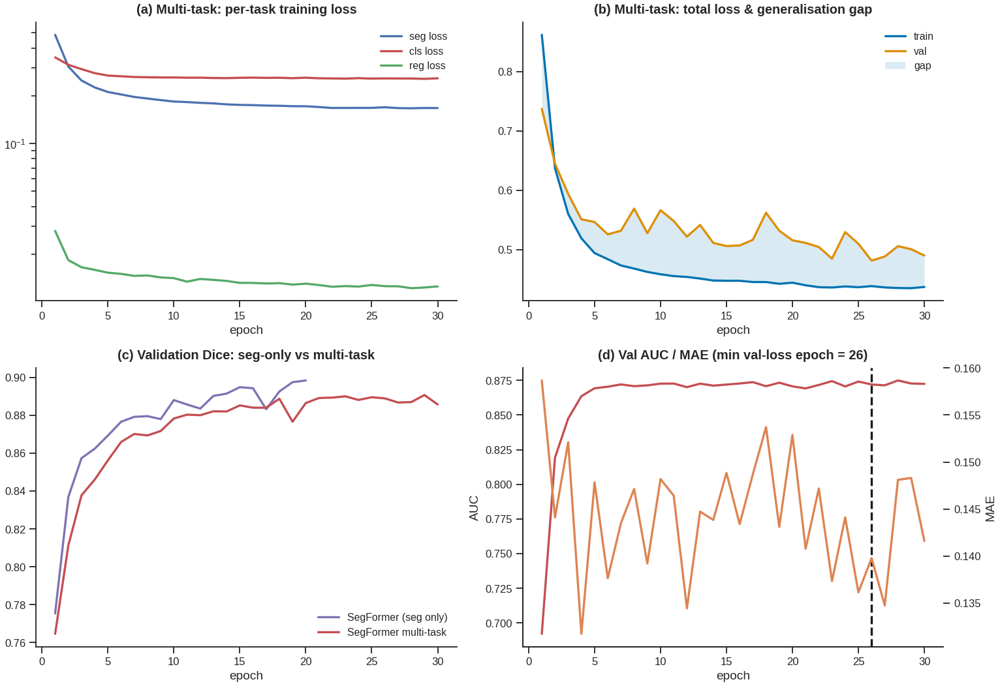

,Epochs,Best epoch (min val loss),Final train loss,Final val loss
Run,,,,
Multi-task,30,26,0.4373,0.4903
Seg only,20,19,0.1512,0.1275


In [79]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for c_, col in [("train_seg", "#4C72B0"), ("train_cls", "#C44E52"), ("train_reg", "#55A868")]:
    axes[0, 0].plot(mt_hist_df["epoch"], mt_hist_df[c_], label=c_.replace("train_", "") + " loss", c=col)
axes[0, 0].set_yscale("log"); axes[0, 0].set_title("(a) Multi-task: per-task training loss"); axes[0, 0].legend(); axes[0, 0].set_xlabel("epoch")

axes[0, 1].plot(mt_hist_df["epoch"], mt_hist_df["train_loss"], label="train"); axes[0, 1].plot(mt_hist_df["epoch"], mt_hist_df["val_loss"], label="val")
axes[0, 1].fill_between(mt_hist_df["epoch"], mt_hist_df["train_loss"], mt_hist_df["val_loss"], alpha=0.15, label="gap")
axes[0, 1].set_title("(b) Multi-task: total loss & generalisation gap"); axes[0, 1].legend(); axes[0, 1].set_xlabel("epoch")

if "hist_df" in globals():
    axes[1, 0].plot(hist_df["epoch"], hist_df["Dice"], label="SegFormer (seg only)", c="#8172B2")
axes[1, 0].plot(mt_hist_df["epoch"], mt_hist_df["seg_Dice"], label="SegFormer multi-task", c="#C44E52")
axes[1, 0].set_title("(c) Validation Dice: seg-only vs multi-task"); axes[1, 0].legend(); axes[1, 0].set_xlabel("epoch")

best_ep = int(mt_hist_df["val_loss"].idxmin()) + 1
axes[1, 1].plot(mt_hist_df["epoch"], mt_hist_df["cls_AUC"], c="#C44E52", label="cls AUC")
ax2 = axes[1, 1].twinx(); ax2.plot(mt_hist_df["epoch"], mt_hist_df["reg_MAE"], c="#DD8452", label="reg MAE"); ax2.set_ylabel("MAE")
axes[1, 1].axvline(best_ep, ls="--", c="k"); axes[1, 1].set_title(f"(d) Val AUC / MAE (min val-loss epoch = {best_ep})"); axes[1, 1].set_xlabel("epoch"); axes[1, 1].set_ylabel("AUC")
plt.tight_layout(); save_fig(fig, "figJ_training_dynamics"); plt.show()

conv = pd.DataFrame({"Run": ["Multi-task"] + (["Seg only"] if "hist_df" in globals() else []),
                     "Epochs": [len(mt_hist_df)] + ([len(hist_df)] if "hist_df" in globals() else []),
                     "Best epoch (min val loss)": [best_ep] + ([int(hist_df["val_loss"].idxmin()) + 1] if "hist_df" in globals() else []),
                     "Final train loss": [mt_hist_df["train_loss"].iloc[-1]] + ([hist_df["train_loss"].iloc[-1]] if "hist_df" in globals() else []),
                     "Final val loss": [mt_hist_df["val_loss"].iloc[-1]] + ([hist_df["val_loss"].iloc[-1]] if "hist_df" in globals() else [])}).round(4).set_index("Run")
save_table(conv, "table12_convergence_summary"); conv

## 40. Reproducibility Package — consolidated tables, LaTeX, environment, checksums

Collects every table into one Excel workbook (one sheet per table) and a LaTeX file, records the software/hardware
environment and SHA-256 checksums of the trained checkpoints, and zips all figures (PNG + vector PDF).

In [80]:
import zipfile, hashlib, sys
# bring earlier notebook tables into the same package
for nm, obj in [("q1_bootstrap_ci", "ci_df"), ("q1_statistical_tests", "stats_summary"), ("results_summary_seg", "summary_df"), ("multitask_test_summary", "mt_summary")]:
    if obj in globals(): save_table(globals()[obj], nm, index=(nm != "q1_bootstrap_ci" and nm != "q1_statistical_tests"))

env = {"python": sys.version.split()[0], "torch": torch.__version__, "torchvision": __import__("torchvision").__version__,
       "numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
       "scipy": __import__("scipy").__version__, "device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
       "seed": CFG2["seed"], "experiment_seeds": str(EXP["seeds"])}
for nm, pth in [("seg_ckpt_sha256", os.path.join(CFG["out_dir"], "segformer_best.pth")), ("mt_ckpt_sha256", mt_best_ckpt_path)]:
    env[nm] = hashlib.sha256(open(pth, "rb").read()).hexdigest()[:16] if os.path.exists(pth) else "n/a"
save_table(pd.DataFrame({"Value": pd.Series(env)}), "table13_environment")

xlsx_path = os.path.join(Q1_DIR, "q1_all_tables.xlsx")
with pd.ExcelWriter(xlsx_path, engine="openpyxl") as xw:
    for nm, df in TABLES.items(): df.to_excel(xw, sheet_name=nm[:31])
tex_path = os.path.join(Q1_DIR, "q1_all_tables.tex")
with open(tex_path, "w") as f:
    for nm, df in TABLES.items():
        try: f.write(df.to_latex(float_format="%.4f", caption=nm.replace("_", " "), label="tab:" + nm, escape=True) + "\n\n")
        except Exception as e: f.write(f"% {nm}: LaTeX export failed ({e})\n\n")

zip_path = os.path.join(CFG2["out_dir"], "q1_figures_tables.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for fn in sorted(os.listdir(Q1_DIR)):
        if fn.endswith((".png", ".pdf", ".tiff", ".csv", ".xlsx", ".tex")): zf.write(os.path.join(Q1_DIR, fn), fn)
print(f"{len(TABLES)} tables -> {xlsx_path}\nLaTeX -> {tex_path}\nZIP -> {zip_path}")
print("\nFigure files:", sorted(f for f in os.listdir(Q1_DIR) if f.endswith('.pdf')))
pd.DataFrame({"Value": pd.Series(env)})

21 tables -> /kaggle/working/q1_outputs/q1_all_tables.xlsx
LaTeX -> /kaggle/working/q1_outputs/q1_all_tables.tex
ZIP -> /kaggle/working/q1_figures_tables.zip

Figure files: ['figA_cohort_distributions.pdf', 'figB_seg_threshold_sensitivity.pdf', 'figC_classification_clinical_utility.pdf', 'figD_regression_error_analysis.pdf', 'figE_ablation.pdf', 'figF2_qualitative_model_comparison.pdf', 'figF_baseline_comparison.pdf', 'figG_robustness.pdf', 'figH_subgroups.pdf', 'figI_vessel_biomarkers.pdf', 'figJ_training_dynamics.pdf']


,Value
python,3.13.15
torch,2.11.0+cu128
torchvision,0.26.0+cu128
numpy,2.1.3
pandas,2.3.3
scikit-learn,1.6.1
scipy,1.16.3
device,Tesla T4
seed,42
experiment_seeds,[42]


## 41. Limitations & Reporting Notes

**Limitations to state explicitly in the manuscript**

1. **Single-source dataset, no external validation.** All results come from one cohort with a patient-level split.
   External validation on an independent site / device (and on a public benchmark such as DRIVE / STARE / CHASE_DB1 for the
   segmentation task) would substantially strengthen the claims.
2. **Origin of the vessel masks.** Describe how `fundusmask5806` was produced (manual vs. semi-automatic vs. model-generated).
   If masks are automatic, Dice measures agreement with that pipeline rather than with expert annotation; add an
   inter-observer study or expert re-annotation on a subset.
3. **Segmentation-only experiment (Sections 1–10)** selects the best checkpoint on the *same* validation split on which it
   reports metrics. The multi-task evaluation (Sections 11–40) uses a separate held-out test split and is the one to quote.
4. **Ablation / baseline budget.** Sections 34–35 re-train variants with a reduced budget (`EXP`). Conclusions are about the
   *relative* ordering; repeat with ≥ 3 seeds (`EXP["seeds"]`) and report mean ± SD for the final submission.
5. **Class prevalence & calibration.** Check `Table 1` and `Table 5`: if prevalence is imbalanced, report AUPRC / MCC next to
   accuracy, and consider recalibration (Platt / isotonic) before any clinical use.
6. **Thickness target.** State the measurement protocol (device, site, unit) for `thickness`; the regression head predicts
   the raw value.
7. **Explainability** (Grad-CAM, IG, occlusion, Shapley, MC-dropout) is qualitative; no claim of causal relevance should be made.

**Reporting checklist (adapt to journal): TRIPOD-AI / CLAIM** — data source & eligibility ✔ (Table 1), outcome definition,
preprocessing ✔ (Table 2), split strategy & leakage control ✔, model details ✔ (Tables 2–3), metrics with CIs ✔ (Tables 4–6),
baselines ✔ (Table 8), ablations ✔ (Table 7), robustness ✔ (Table 9), fairness ✔ (Table 10), calibration ✔ (Fig. C / §19),
code & checkpoints (SHA-256 in Table 13).